In [1]:
# ==========================================================
# Step-1 : Import Required Libraries
#          + Single Project Root
#          + SHA-256 Helper
# ==========================================================

import os
import hashlib
from pathlib import Path

os.environ["SCIPY_ARRAY_API"] = "1"

import numpy as np
import pandas as pd
import geopandas as gpd
import pyreadstat
import matplotlib.pyplot as plt

from libpysal.weights import KNN

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit

from sklearn.linear_model import (
    LogisticRegression,
    SGDClassifier
)

from sklearn.tree import (
    DecisionTreeClassifier
)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier,
)

from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# ==========================================================
# 1. SINGLE PROJECT ROOT
# ==========================================================

PROJECT_ROOT = Path(
    r"F:\Thesis"
).resolve()


if not PROJECT_ROOT.exists():

    raise FileNotFoundError(
        f"Project root does not exist: {PROJECT_ROOT}"
    )


SAVE_DIR = (
    PROJECT_ROOT
    / "SpatialML_Saved"
)


# ==========================================================
# 2. SHA-256 HELPER
# ==========================================================

def sha256_file(
    path,
    chunk_size=1024 * 1024
):

    path = Path(path)

    h = hashlib.sha256()

    with path.open(
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            h.update(
                chunk
            )

    return h.hexdigest()


# ==========================================================
# 3. SUMMARY
# ==========================================================

print("=" * 70)

print(
    "Spatial Machine Learning Libraries Loaded Successfully"
)

print("=" * 70)

print(
    "Project root:",
    PROJECT_ROOT
)

print(
    "Output directory:",
    SAVE_DIR
)

Spatial Machine Learning Libraries Loaded Successfully
Project root: F:\Thesis
Output directory: F:\Thesis\SpatialML_Saved


In [2]:
# ==========================================================
# Step-2 : Load Analytical Dataset and Original DHS KR Data
#          + Reviewer-Required DHS Provenance
# ==========================================================

from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import pyreadstat


# ==========================================================
# 1. SINGLE PROJECT ROOT
# ==========================================================

PROJECT_ROOT = Path(
    r"F:\Thesis"
).resolve()


SAVE_DIR = (
    PROJECT_ROOT
    / "SpatialML_Saved"
)


if not PROJECT_ROOT.exists():

    raise FileNotFoundError(
        f"Project folder does not exist: {PROJECT_ROOT}"
    )


print("=" * 70)
print("PROJECT ROOT")
print("=" * 70)

print(PROJECT_ROOT)


# ==========================================================
# 2. INPUT FILE PATHS
# ==========================================================

BDHS_FILE = (
    PROJECT_ROOT
    / "Stunting_Final_Recoded_Final.SAV"
)


# Use the original DHS KR file only
ORIGINAL_KR_FILE = (
    PROJECT_ROOT
    / "BDKR81FL.SAV"
)


GPS_FILE = (
    PROJECT_ROOT
    / "GPS DATA"
    / "Division"
    / "BDGE81FL.shp"
)


ENV_FILE = (
    PROJECT_ROOT
    / "GPS DATA"
    / "bdhs_env_2022.csv"
)


DIVISION_BOUNDARY_FILE = (
    PROJECT_ROOT
    / "GPS DATA"
    / "Division"
    / "gadm41_BGD_1.shp"
)


# ==========================================================
# 3. CHECK REQUIRED INPUT FILES
# ==========================================================

required_files = [
    BDHS_FILE,
    ORIGINAL_KR_FILE,
    GPS_FILE,
    ENV_FILE,
    DIVISION_BOUNDARY_FILE,
]


missing_files = [

    file_path

    for file_path in required_files

    if not file_path.exists()
]


if missing_files:

    print("\n" + "=" * 70)
    print("MISSING INPUT FILES")
    print("=" * 70)

    for file_path in missing_files:

        print(file_path)


    raise FileNotFoundError(
        "One or more required input files are missing."
    )


print("\n" + "=" * 70)
print("ALL REQUIRED INPUT FILES FOUND")
print("=" * 70)


for file_path in required_files:

    print(
        "✓",
        file_path
    )


# ==========================================================
# 4. LOAD RECODED ANALYTICAL DATASET
# ==========================================================

df, meta = pyreadstat.read_sav(
    BDHS_FILE
)


print("\n" + "=" * 70)
print("RECODED ANALYTICAL DATASET LOADED")
print("=" * 70)


print(
    "File :",
    BDHS_FILE
)

print(
    "Shape:",
    df.shape
)


# ==========================================================
# 5. LOAD ORIGINAL DHS KR DATASET
# ==========================================================

kr_original, kr_meta = pyreadstat.read_sav(
    ORIGINAL_KR_FILE
)


print("\n" + "=" * 70)
print("ORIGINAL DHS KR DATASET LOADED")
print("=" * 70)


print(
    "File :",
    ORIGINAL_KR_FILE
)

print(
    "Shape:",
    kr_original.shape
)


# ==========================================================
# 6. CASE-INSENSITIVE COLUMN FINDER
# ==========================================================

def find_column_case_insensitive(
    dataframe,
    requested_name
):

    matches = [

        column

        for column
        in dataframe.columns

        if str(
            column
        ).upper()
        ==
        str(
            requested_name
        ).upper()
    ]


    if len(
        matches
    ) != 1:

        raise RuntimeError(

            f"Expected exactly one column matching "
            f"'{requested_name}', found: {matches}"
        )


    return matches[
        0
    ]


# ==========================================================
# 7. IDENTIFY ORIGINAL DHS KR VARIABLES
# ==========================================================

kr_caseid_col = find_column_case_insensitive(
    kr_original,
    "CASEID"
)


kr_child_index_col = find_column_case_insensitive(
    kr_original,
    "BIDX"
)


kr_v005_col = find_column_case_insensitive(
    kr_original,
    "V005"
)


kr_v021_col = find_column_case_insensitive(
    kr_original,
    "V021"
)


kr_v022_col = find_column_case_insensitive(
    kr_original,
    "V022"
)


kr_v023_col = find_column_case_insensitive(
    kr_original,
    "V023"
)


kr_hw70_col = find_column_case_insensitive(
    kr_original,
    "HW70"
)


kr_seligbm_col = find_column_case_insensitive(
    kr_original,
    "SELIGBM"
)


print("\n" + "=" * 70)
print("ORIGINAL DHS VARIABLES IDENTIFIED")
print("=" * 70)


print("CASEID  :", kr_caseid_col)
print("BIDX    :", kr_child_index_col)
print("V005    :", kr_v005_col)
print("V021    :", kr_v021_col)
print("V022    :", kr_v022_col)
print("V023    :", kr_v023_col)
print("HW70    :", kr_hw70_col)
print("SELIGBM :", kr_seligbm_col)


# ==========================================================
# 8. REVIEWER-REQUIRED DHS PROVENANCE DEFINITIONS
# ==========================================================

ORIGINAL_DHS_WEIGHT_VAR = (
    "ORIG_V005"
)


ORIGINAL_DHS_WEIGHT_FORMULA = (
    "survey_weight = V005 / 1,000,000"
)


ORIGINAL_DHS_WEIGHT_TRANSFORM = (

    lambda x:

        pd.to_numeric(
            x,
            errors="coerce"
        )

        /

        1_000_000.0
)


# ==========================================================
# IMPORTANT:
# This was missing previously and caused the NameError
# ==========================================================

ORIGINAL_DHS_WEIGHT_SAMPLE_NOTE = (
    "The analysis weight is traced directly to the original "
    "Bangladesh DHS KR variable V005. The exact transformation "
    "used in the notebook is V005 / 1,000,000. SELIGBM is also "
    "retained from the original KR file so that the relationship "
    "between the analytic child anthropometry sample and the "
    "biomarker-subsample selection can be audited."
)


ORIGINAL_DHS_PSU_VAR = (
    "ORIG_V021"
)


ORIGINAL_DHS_STRATUM_VAR = (
    "ORIG_V023"
)


ORIGINAL_DHS_HAZ_VAR = (
    "ORIG_HW70"
)


ORIGINAL_DHS_BIOMARKER_SELECTION_VAR = (
    "ORIG_SELIGBM"
)


# ==========================================================
# 9. CHECK ANALYTICAL DATASET MERGE KEYS
# ==========================================================

required_analysis_keys = [
    "caseid",
    "child_index",
]


missing_analysis_keys = [

    variable

    for variable in required_analysis_keys

    if variable not in df.columns
]


if missing_analysis_keys:

    raise RuntimeError(

        "Required analytical merge keys are missing: "
        f"{missing_analysis_keys}"
    )


# ==========================================================
# 10. CREATE ORIGINAL DHS PROVENANCE TABLE
# ==========================================================

kr_provenance = (

    kr_original[
        [
            kr_caseid_col,
            kr_child_index_col,
            kr_v005_col,
            kr_v021_col,
            kr_v022_col,
            kr_v023_col,
            kr_hw70_col,
            kr_seligbm_col,
        ]
    ]

    .copy()
)


kr_provenance = kr_provenance.rename(
    columns={

        kr_caseid_col:
            "caseid",

        kr_child_index_col:
            "child_index",

        kr_v005_col:
            "ORIG_V005",

        kr_v021_col:
            "ORIG_V021",

        kr_v022_col:
            "ORIG_V022",

        kr_v023_col:
            "ORIG_V023",

        kr_hw70_col:
            "ORIG_HW70",

        kr_seligbm_col:
            "ORIG_SELIGBM",
    }
)


# ==========================================================
# 11. STANDARDIZE MERGE KEYS
# ==========================================================

df[
    "caseid"
] = (

    df[
        "caseid"
    ]

    .astype(
        str
    )

    .str.strip()
)


kr_provenance[
    "caseid"
] = (

    kr_provenance[
        "caseid"
    ]

    .astype(
        str
    )

    .str.strip()
)


df[
    "child_index"
] = pd.to_numeric(

    df[
        "child_index"
    ],

    errors=
        "raise"

).astype(
    int
)


kr_provenance[
    "child_index"
] = pd.to_numeric(

    kr_provenance[
        "child_index"
    ],

    errors=
        "raise"

).astype(
    int
)


# ==========================================================
# 12. ORIGINAL KR KEY DUPLICATE AUDIT
# ==========================================================

kr_duplicate_keys = kr_provenance.duplicated(

    subset=[
        "caseid",
        "child_index",
    ],

    keep=
        False
)


print("\n" + "=" * 70)
print("ORIGINAL KR KEY AUDIT")
print("=" * 70)


print(
    "Original KR rows:",
    len(
        kr_provenance
    )
)


print(
    "Duplicate CASEID + BIDX rows:",
    int(
        kr_duplicate_keys.sum()
    )
)


if kr_duplicate_keys.any():

    display(

        kr_provenance.loc[
            kr_duplicate_keys
        ]

        .sort_values(
            [
                "caseid",
                "child_index",
            ]
        )

        .head(
            50
        )
    )


    raise RuntimeError(

        "Original KR file contains duplicate "
        "CASEID + BIDX keys."
    )


# ==========================================================
# 13. REMOVE OLD PROVENANCE COLUMNS IF CELL IS RE-RUN
# ==========================================================

old_provenance_columns = [

    "ORIG_V005",
    "ORIG_V021",
    "ORIG_V022",
    "ORIG_V023",
    "ORIG_HW70",
    "ORIG_SELIGBM",
    "survey_weight_verified",
    "psu_verified",
    "survey_stratum_verified",
]


existing_old_columns = [

    column

    for column
    in old_provenance_columns

    if column in df.columns
]


if existing_old_columns:

    df = df.drop(
        columns=
            existing_old_columns
    )


# ==========================================================
# 14. MERGE ORIGINAL DHS VARIABLES
# ==========================================================

n_before_merge = len(
    df
)


df = df.merge(

    kr_provenance,

    on=[
        "caseid",
        "child_index",
    ],

    how=
        "left",

    validate=
        "one_to_one",

    indicator=
        "_kr_merge_status"
)


if len(
    df
) != n_before_merge:

    raise RuntimeError(

        "Row count changed after merging "
        "original DHS provenance variables."
    )


# ==========================================================
# 15. MERGE AUDIT
# ==========================================================

print("\n" + "=" * 70)
print("ORIGINAL DHS KR MERGE AUDIT")
print("=" * 70)


merge_status_counts = (

    df[
        "_kr_merge_status"
    ]

    .value_counts(
        dropna=False
    )
)


display(
    merge_status_counts
)


unmatched_rows = (

    df[
        "_kr_merge_status"
    ]

    !=
    "both"
)


print(
    "Analytical rows:",
    len(
        df
    )
)


print(
    "Matched rows:",
    int(
        (
            ~unmatched_rows
        ).sum()
    )
)


print(
    "Unmatched rows:",
    int(
        unmatched_rows.sum()
    )
)


if unmatched_rows.any():

    display(

        df.loc[

            unmatched_rows,

            [
                "caseid",
                "child_index",
            ]

        ].head(
            50
        )
    )


    raise RuntimeError(

        "Some analytical observations could not "
        "be matched to the original DHS KR file "
        "using caseid + child_index."
    )


df = df.drop(
    columns=
        "_kr_merge_status"
)


# ==========================================================
# 16. CONVERT ORIGINAL DHS VARIABLES TO NUMERIC
# ==========================================================

for variable in [

    "ORIG_V005",
    "ORIG_V021",
    "ORIG_V022",
    "ORIG_V023",
    "ORIG_HW70",
    "ORIG_SELIGBM",

]:

    df[
        variable
    ] = pd.to_numeric(

        df[
            variable
        ],

        errors=
            "coerce"
    )


# ==========================================================
# 17. CREATE VERIFIED SURVEY WEIGHT
# ==========================================================

df[
    "survey_weight_verified"
] = ORIGINAL_DHS_WEIGHT_TRANSFORM(

    df[
        ORIGINAL_DHS_WEIGHT_VAR
    ]
)


if df[
    "survey_weight_verified"
].isna().any():

    raise RuntimeError(

        "Missing verified survey weights "
        "after merging original V005."
    )


if (

    df[
        "survey_weight_verified"
    ]
    <=
    0

).any():

    raise RuntimeError(

        "Verified survey weights contain "
        "zero or negative values."
    )


# ==========================================================
# 18. CREATE VERIFIED PSU AND STRATUM
# ==========================================================

df[
    "psu_verified"
] = df[
    ORIGINAL_DHS_PSU_VAR
]


df[
    "survey_stratum_verified"
] = df[
    ORIGINAL_DHS_STRATUM_VAR
]


if df[
    "psu_verified"
].isna().any():

    raise RuntimeError(
        "Missing original V021 PSU values."
    )


if df[
    "survey_stratum_verified"
].isna().any():

    raise RuntimeError(
        "Missing original V023 stratum values."
    )


# ==========================================================
# 19. SET CANONICAL ANALYSIS DESIGN VARIABLES
# ==========================================================

df[
    "survey_weight"
] = df[
    "survey_weight_verified"
].astype(
    float
)


df[
    "psu"
] = pd.to_numeric(

    df[
        "psu_verified"
    ],

    errors=
        "raise"

).astype(
    int
)


df[
    "survey_stratum"
] = pd.to_numeric(

    df[
        "survey_stratum_verified"
    ],

    errors=
        "raise"

).astype(
    int
)


# ==========================================================
# 20. SURVEY-WEIGHT PROVENANCE SUMMARY
# ==========================================================

print("\n" + "=" * 70)
print("SURVEY-WEIGHT PROVENANCE")
print("=" * 70)


print(
    "Original weight variable:",
    ORIGINAL_DHS_WEIGHT_VAR
)


print(
    "Exact formula:",
    ORIGINAL_DHS_WEIGHT_FORMULA
)


print(
    "Sample note:"
)


print(
    ORIGINAL_DHS_WEIGHT_SAMPLE_NOTE
)


# ==========================================================
# 21. SURVEY-STRATUM AUDIT
# ==========================================================

n_v022_levels = int(

    df[
        "ORIG_V022"
    ].nunique(
        dropna=True
    )
)


n_v023_levels = int(

    df[
        "ORIG_V023"
    ].nunique(
        dropna=True
    )
)


n_canonical_strata = int(

    df[
        "survey_stratum"
    ].nunique(
        dropna=True
    )
)


print("\n" + "=" * 70)
print("SURVEY STRATUM AUDIT")
print("=" * 70)


print(
    "Original V022 observed levels:",
    n_v022_levels
)


print(
    "Original V023 observed levels:",
    n_v023_levels
)


print(
    "Canonical survey_stratum observed levels:",
    n_canonical_strata
)


print(
    "\nOriginal V023 frequency table:"
)


display(

    df[
        "ORIG_V023"
    ]

    .value_counts(
        dropna=False
    )

    .sort_index()
)


# ==========================================================
# 22. ORIGINAL HW70 / HAZ AUDIT
# ==========================================================

print("\n" + "=" * 70)
print("ORIGINAL HW70 / HAZ AUDIT")
print("=" * 70)


print(
    "Total analytical rows:",
    len(
        df
    )
)


print(
    "HW70 available:",
    int(
        df[
            "ORIG_HW70"
        ].notna().sum()
    )
)


print(
    "HW70 missing:",
    int(
        df[
            "ORIG_HW70"
        ].isna().sum()
    )
)


print(
    "SELIGBM available:",
    int(
        df[
            "ORIG_SELIGBM"
        ].notna().sum()
    )
)


# ==========================================================
# 23. DHS CLUSTER IDENTIFIER
# ==========================================================

if "dhsclust" not in df.columns:

    if "v001" in df.columns:

        df[
            "dhsclust"
        ] = pd.to_numeric(

            df[
                "v001"
            ],

            errors=
                "raise"

        ).astype(
            int
        )


    elif "V001" in df.columns:

        df[
            "dhsclust"
        ] = pd.to_numeric(

            df[
                "V001"
            ],

            errors=
                "raise"

        ).astype(
            int
        )


    else:

        raise RuntimeError(

            "No DHS cluster identifier "
            "was found in the analytical dataset."
        )


else:

    df[
        "dhsclust"
    ] = pd.to_numeric(

        df[
            "dhsclust"
        ],

        errors=
            "raise"

    ).astype(
        int
    )


# ==========================================================
# 24. LOAD GPS DATA
# ==========================================================

gps = gpd.read_file(
    GPS_FILE
)


# ==========================================================
# 25. LOAD ENVIRONMENTAL DATA
# ==========================================================

env = pd.read_csv(
    ENV_FILE
)


# ==========================================================
# 26. FINAL STEP-2 SUMMARY
# ==========================================================

print("\n" + "=" * 70)
print("STEP-2 COMPLETED SUCCESSFULLY")
print("=" * 70)


print(
    "Project Root       :",
    PROJECT_ROOT
)


print(
    "Analytical File    :",
    BDHS_FILE
)


print(
    "Original KR File   :",
    ORIGINAL_KR_FILE
)


print(
    "GPS File           :",
    GPS_FILE
)


print(
    "Environmental File :",
    ENV_FILE
)


print(
    "Division Boundary  :",
    DIVISION_BOUNDARY_FILE
)


print(
    "\nAnalytical Dataset Shape:",
    df.shape
)


print(
    "Original KR Dataset Shape:",
    kr_original.shape
)


print(
    "GPS Dataset Shape:",
    gps.shape
)


print(
    "ENV Dataset Shape:",
    env.shape
)


print("\n" + "=" * 70)
print("CANONICAL SURVEY VARIABLES")
print("=" * 70)


print(
    "Survey weight : survey_weight"
)


print(
    "PSU           : psu"
)


print(
    "Stratum       : survey_stratum"
)


print(
    "Original HAZ  : ORIG_HW70"
)


print(
    "Biomarker var : ORIG_SELIGBM"
)


print(
    "Spatial ID    : dhsclust"
)


print(
    "\nUnique PSU:",
    df[
        "psu"
    ].nunique()
)


print(
    "Unique V022 levels:",
    df[
        "ORIG_V022"
    ].nunique()
)


print(
    "Unique V023 levels:",
    df[
        "ORIG_V023"
    ].nunique()
)


print(
    "Unique canonical strata:",
    df[
        "survey_stratum"
    ].nunique()
)

PROJECT ROOT
F:\Thesis

ALL REQUIRED INPUT FILES FOUND
✓ F:\Thesis\Stunting_Final_Recoded_Final.SAV
✓ F:\Thesis\BDKR81FL.SAV
✓ F:\Thesis\GPS DATA\Division\BDGE81FL.shp
✓ F:\Thesis\GPS DATA\bdhs_env_2022.csv
✓ F:\Thesis\GPS DATA\Division\gadm41_BGD_1.shp

RECODED ANALYTICAL DATASET LOADED
File : F:\Thesis\Stunting_Final_Recoded_Final.SAV
Shape: (3633, 36)

ORIGINAL DHS KR DATASET LOADED
File : F:\Thesis\BDKR81FL.SAV
Shape: (8784, 1238)

ORIGINAL DHS VARIABLES IDENTIFIED
CASEID  : CASEID
BIDX    : BIDX
V005    : V005
V021    : V021
V022    : V022
V023    : V023
HW70    : HW70
SELIGBM : SELIGBM

ORIGINAL KR KEY AUDIT
Original KR rows: 8784
Duplicate CASEID + BIDX rows: 0

ORIGINAL DHS KR MERGE AUDIT


_kr_merge_status
both          3633
left_only        0
right_only       0
Name: count, dtype: int64

Analytical rows: 3633
Matched rows: 3633
Unmatched rows: 0

SURVEY-WEIGHT PROVENANCE
Original weight variable: ORIG_V005
Exact formula: survey_weight = V005 / 1,000,000
Sample note:
The analysis weight is traced directly to the original Bangladesh DHS KR variable V005. The exact transformation used in the notebook is V005 / 1,000,000. SELIGBM is also retained from the original KR file so that the relationship between the analytic child anthropometry sample and the biomarker-subsample selection can be audited.

SURVEY STRATUM AUDIT
Original V022 observed levels: 16
Original V023 observed levels: 16
Canonical survey_stratum observed levels: 16

Original V023 frequency table:


ORIG_V023
1.0     119
2.0     297
3.0     238
4.0     386
5.0     243
6.0     286
7.0     123
8.0     265
9.0     108
10.0    336
11.0    118
12.0    239
13.0    104
14.0    311
15.0    108
16.0    352
Name: count, dtype: int64


ORIGINAL HW70 / HAZ AUDIT
Total analytical rows: 3633
HW70 available: 3633
HW70 missing: 0
SELIGBM available: 3633

STEP-2 COMPLETED SUCCESSFULLY
Project Root       : F:\Thesis
Analytical File    : F:\Thesis\Stunting_Final_Recoded_Final.SAV
Original KR File   : F:\Thesis\BDKR81FL.SAV
GPS File           : F:\Thesis\GPS DATA\Division\BDGE81FL.shp
Environmental File : F:\Thesis\GPS DATA\bdhs_env_2022.csv
Division Boundary  : F:\Thesis\GPS DATA\Division\gadm41_BGD_1.shp

Analytical Dataset Shape: (3633, 46)
Original KR Dataset Shape: (8784, 1238)
GPS Dataset Shape: (674, 21)
ENV Dataset Shape: (674, 15)

CANONICAL SURVEY VARIABLES
Survey weight : survey_weight
PSU           : psu
Stratum       : survey_stratum
Original HAZ  : ORIG_HW70
Biomarker var : ORIG_SELIGBM
Spatial ID    : dhsclust

Unique PSU: 667
Unique V022 levels: 16
Unique V023 levels: 16
Unique canonical strata: 16


In [3]:
# ==========================================================
# # ==========================================================
# Step-2A : Child Age / HAZ Variable Audit
# ==========================================================
# ==========================================================

check_terms = [
    "b19",
    "hw70",
    "child_age",
    "age_month",
    "haz",
    "height"
]

matched_columns = [
    col
    for col in df.columns
    if any(
        term.lower() in str(col).lower()
        for term in check_terms
    )
]

print("Possible child-age / HAZ variables:")
print(matched_columns)

print("\nSPSS labels:")

for col in matched_columns:

    label = None

    if hasattr(
        meta,
        "column_names_to_labels"
    ):

        label = meta.column_names_to_labels.get(
            col
        )

    print(
        col,
        "->",
        label
    )

Possible child-age / HAZ variables:
['Maternal_Height', 'B19', 'Child_age_group', 'ORIG_HW70']

SPSS labels:
Maternal_Height -> None
B19 -> Current age of child in months (months since birth for dead children)
Child_age_group -> Current age of child in grouped months
ORIG_HW70 -> None


In [4]:
# ==========================================================
# Step-3 : GPS Cleaning
#          + DHS GPS-Displacement Interpretation Note
# ==========================================================

print("=" * 70)
print("GPS DATA CLEANING")
print("=" * 70)

# ----------------------------------------------------------
# Keep required variables
# ----------------------------------------------------------

gps = gps[
    [
        "DHSCLUST",
        "LATNUM",
        "LONGNUM"
    ]
].copy()

# ----------------------------------------------------------
# Rename
# ----------------------------------------------------------

gps.rename(
    columns={
        "DHSCLUST": "dhsclust",
        "LATNUM": "lat",
        "LONGNUM": "lon"
    },
    inplace=True
)

# ----------------------------------------------------------
# Integer Cluster ID
# ----------------------------------------------------------

gps["dhsclust"] = gps[
    "dhsclust"
].astype(int)

print(
    "Rows :",
    len(gps)
)

print(
    "Unique Clusters :",
    gps["dhsclust"].nunique()
)

# ----------------------------------------------------------
# Missing values
# ----------------------------------------------------------

print("\nMissing Values")

print(
    gps.isna().sum()
)

# ----------------------------------------------------------
# Remove missing coordinates
# ----------------------------------------------------------

gps = gps.dropna(
    subset=[
        "lat",
        "lon"
    ]
)

# ----------------------------------------------------------
# Remove zero coordinates
# ----------------------------------------------------------

gps = gps[
    (gps["lat"] != 0)
    &
    (gps["lon"] != 0)
]

# ----------------------------------------------------------
# Remove duplicate clusters
# ----------------------------------------------------------

gps = gps.drop_duplicates(
    subset="dhsclust"
)

gps = gps.reset_index(
    drop=True
)

print(
    "\nFinal GPS Shape :",
    gps.shape
)

display(
    gps.head()
)

# ==========================================================
# DHS GPS-Displacement Interpretation Note
# ==========================================================

spatial_interpretation_note = (
    "DHS-released cluster coordinates are intentionally "
    "spatially displaced for confidentiality. Therefore, "
    "environmental linkage, nearest-neighbour WX features, "
    "latitude/longitude effects, residual Moran's I, and "
    "GeoShapley spatial patterns must be interpreted as "
    "cluster-level spatial approximations rather than exact "
    "household- or exact cluster-location effects."
)

print("\n")
print("=" * 70)
print("DHS GPS DISPLACEMENT NOTE")
print("=" * 70)

print(
    spatial_interpretation_note
)

GPS DATA CLEANING
Rows : 674
Unique Clusters : 674

Missing Values
dhsclust    0
lat         0
lon         0
dtype: int64

Final GPS Shape : (674, 3)


,dhsclust,lat,lon
0,1,22.717315,90.373835
1,2,22.717246,90.382553
2,3,22.713827,90.383011
3,4,22.698693,90.368405
4,5,22.692715,90.366816




DHS GPS DISPLACEMENT NOTE
DHS-released cluster coordinates are intentionally spatially displaced for confidentiality. Therefore, environmental linkage, nearest-neighbour WX features, latitude/longitude effects, residual Moran's I, and GeoShapley spatial patterns must be interpreted as cluster-level spatial approximations rather than exact household- or exact cluster-location effects.


In [5]:
# ==========================================================
# Step-4 : Environmental Data Cleaning and Quality Assessment
# ==========================================================

# ----------------------------------------------------------
# Standardize Column Names
# ----------------------------------------------------------

env.columns = (

    env.columns

       .str.strip()

       .str.lower()

)

# ----------------------------------------------------------
# Check Required Column
# ----------------------------------------------------------

if "dhsclust" not in env.columns:

    raise ValueError(

        "'dhsclust' column is missing from environmental dataset."

    )

# ----------------------------------------------------------
# Convert Cluster ID
# ----------------------------------------------------------

env["dhsclust"] = env["dhsclust"].astype(int)

# ----------------------------------------------------------
# Dataset Summary
# ----------------------------------------------------------

print("=" * 70)
print("ENVIRONMENTAL DATA SUMMARY")
print("=" * 70)

print("Total Records :", len(env))
print("Total Variables :", env.shape[1])
print("Unique Clusters :", env["dhsclust"].nunique())

# ----------------------------------------------------------
# Missing Value Assessment
# ----------------------------------------------------------

missing_summary = (

    env

    .isnull()

    .sum()

    .sort_values(

        ascending=False

    )

)

missing_summary = missing_summary[
    missing_summary > 0
]

print("\n")

print("=" * 70)
print("MISSING VALUES")
print("=" * 70)

if len(missing_summary) == 0:

    print("No missing values detected.")

else:

    display(

        missing_summary.to_frame(

            name="Missing_Count"

        )

    )

# ----------------------------------------------------------
# Duplicate Cluster Check
# ----------------------------------------------------------

duplicate_clusters = env[

    env.duplicated(

        subset="dhsclust",

        keep=False

    )

]

print("\nDuplicate Cluster Records :", len(duplicate_clusters))

# ----------------------------------------------------------
# Aggregate Duplicate Clusters
# ----------------------------------------------------------

numeric_columns = env.select_dtypes(

    include=np.number

).columns.tolist()

numeric_columns.remove("dhsclust")

env_cluster = (

    env

    .groupby(

        "dhsclust",

        as_index=False

    )[numeric_columns]

    .mean()

)

# ----------------------------------------------------------
# Final Integrity Check
# ----------------------------------------------------------

print("\n")

print("=" * 70)
print("AFTER AGGREGATION")
print("=" * 70)

print("Rows :", len(env_cluster))
print("Unique Clusters :", env_cluster["dhsclust"].nunique())

# ----------------------------------------------------------
# Environmental Variable Summary
# ----------------------------------------------------------

print("\n")

print("=" * 70)
print("ENVIRONMENTAL VARIABLES")
print("=" * 70)

display(

    env_cluster.describe().T

)

ENVIRONMENTAL DATA SUMMARY
Total Records : 674
Total Variables : 15
Unique Clusters : 674


MISSING VALUES


,Missing_Count
temperature_celsius,1
relative_humidity_pct,1
soil_moisture,1



Duplicate Cluster Records : 0


AFTER AGGREGATION
Rows : 674
Unique Clusters : 674


ENVIRONMENTAL VARIABLES


,count,mean,std,min,25%,50%,75%,max
dhsclust,674.0,338.281899,195.007130,1.000000,170.250000,338.500000,506.750000,675.000000
rainfall_mm_yr,674.0,2442.368128,720.278624,1524.994444,1910.826775,2285.885667,2802.647905,5259.368516
temperature_celsius,673.0,25.035507,0.559504,23.126007,24.674741,25.172732,25.443346,26.070054
relative_humidity_pct,673.0,76.657445,1.455188,72.935482,75.725966,76.585078,77.558998,81.010406
soil_moisture,673.0,0.304889,0.033163,0.165389,0.289731,0.297886,0.313465,0.405108
ndvi,674.0,0.564288,0.093680,0.243495,0.530325,0.594290,0.623644,0.795394
lst_celsius,674.0,27.543428,0.991875,25.223451,26.861051,27.365814,27.997852,30.808907
elevation_m,674.0,16.992976,15.234229,1.495062,8.351489,13.060197,19.443307,222.665026
slope_degrees,674.0,0.112519,0.235599,0.026846,0.054036,0.066451,0.096606,4.325426
flood_occurrence_pct,674.0,34.571716,23.605938,1.909091,16.223760,27.411555,47.261395,96.299246


In [6]:
# ==========================================================
# Step-5 : Merge BDHS, GPS and Environmental Data
#          + Verify Original DHS Weight / PSU Provenance
#          + Verify 16-Level Survey Stratum
#          + Biomarker-Selection Audit
#          + True Child-ID Duplicate Audit
# ==========================================================

import numpy as np
import pandas as pd


print("=" * 70)
print("STEP-5 : DATA MERGE + SURVEY-DESIGN PROVENANCE")
print("=" * 70)


# ==========================================================
# 1. SURVEY-DESIGN CONFIGURATION
# ==========================================================

EXPECTED_SURVEY_STRATA = 16


required_config_names = [
    "ORIGINAL_DHS_WEIGHT_VAR",
    "ORIGINAL_DHS_WEIGHT_FORMULA",
    "ORIGINAL_DHS_WEIGHT_TRANSFORM",
    "ORIGINAL_DHS_WEIGHT_SAMPLE_NOTE",
    "ORIGINAL_DHS_PSU_VAR",
    "ORIGINAL_DHS_STRATUM_VAR",
    "ORIGINAL_DHS_HAZ_VAR",
    "ORIGINAL_DHS_BIOMARKER_SELECTION_VAR",
]


missing_config_names = [
    name
    for name in required_config_names
    if name not in globals()
]


if missing_config_names:

    raise RuntimeError(
        "Run Step-2 first. Missing configuration objects: "
        f"{missing_config_names}"
    )


# ==========================================================
# 2. CHECK ORIGINAL DHS SOURCE VARIABLES
# ==========================================================

required_source_columns = [
    ORIGINAL_DHS_WEIGHT_VAR,
    ORIGINAL_DHS_PSU_VAR,
    ORIGINAL_DHS_STRATUM_VAR,
    ORIGINAL_DHS_HAZ_VAR,
    ORIGINAL_DHS_BIOMARKER_SELECTION_VAR,
]


missing_source_columns = [
    column
    for column in required_source_columns
    if column not in df.columns
]


if missing_source_columns:

    raise RuntimeError(
        "Original DHS source variables are missing: "
        f"{missing_source_columns}"
    )


# ==========================================================
# 3. VERIFY SURVEY WEIGHT FROM ORIGINAL V005
# ==========================================================

source_weight = pd.to_numeric(
    df[
        ORIGINAL_DHS_WEIGHT_VAR
    ],
    errors="coerce"
)


if source_weight.isna().any():

    raise RuntimeError(
        "Original DHS weight contains missing "
        "or non-numeric values."
    )


verified_weight = pd.Series(
    ORIGINAL_DHS_WEIGHT_TRANSFORM(
        source_weight.copy()
    ),
    index=df.index,
    dtype=float
)


if verified_weight.isna().any():

    raise RuntimeError(
        "Missing values detected after "
        "survey-weight transformation."
    )


if (
    verified_weight
    <=
    0
).any():

    raise RuntimeError(
        "Zero or negative survey weights detected."
    )


if "survey_weight" in df.columns:

    existing_weight = pd.to_numeric(
        df[
            "survey_weight"
        ],
        errors="coerce"
    )


    comparable_weight = (
        existing_weight.notna()
        &
        verified_weight.notna()
    )


    if comparable_weight.any():

        weight_match = np.allclose(
            existing_weight.loc[
                comparable_weight
            ].to_numpy(
                dtype=float
            ),
            verified_weight.loc[
                comparable_weight
            ].to_numpy(
                dtype=float
            ),
            rtol=1e-8,
            atol=1e-10
        )

    else:

        weight_match = False

else:

    weight_match = None


df[
    "survey_weight"
] = verified_weight


# ==========================================================
# 4. VERIFY PSU FROM ORIGINAL V021
# ==========================================================

original_psu = pd.to_numeric(
    df[
        ORIGINAL_DHS_PSU_VAR
    ],
    errors="coerce"
)


if original_psu.isna().any():

    raise RuntimeError(
        "Missing or non-numeric original PSU values."
    )


df[
    "psu"
] = original_psu.astype(
    int
)


# ==========================================================
# 5. VERIFY 16-LEVEL SURVEY STRATUM
# ==========================================================

source_stratum = pd.to_numeric(
    df[
        ORIGINAL_DHS_STRATUM_VAR
    ],
    errors="coerce"
)


if source_stratum.isna().any():

    raise RuntimeError(
        "Missing or non-numeric survey-stratum values."
    )


df[
    "survey_stratum"
] = source_stratum.astype(
    int
)


n_survey_strata = int(
    df[
        "survey_stratum"
    ].nunique(
        dropna=True
    )
)


if n_survey_strata != EXPECTED_SURVEY_STRATA:

    raise RuntimeError(
        f"Expected {EXPECTED_SURVEY_STRATA} "
        f"survey strata; found {n_survey_strata}."
    )


# ==========================================================
# 6. SURVEY-DESIGN PROVENANCE SUMMARY
# ==========================================================

print("\n" + "=" * 70)
print("SURVEY-DESIGN PROVENANCE")
print("=" * 70)


print(
    "Original DHS weight variable :",
    ORIGINAL_DHS_WEIGHT_VAR
)


print(
    "Exact weight transformation  :",
    ORIGINAL_DHS_WEIGHT_FORMULA
)


print(
    "Weight provenance note        :",
    ORIGINAL_DHS_WEIGHT_SAMPLE_NOTE
)


print(
    "Existing survey_weight matched:",
    weight_match
)


print(
    "Original DHS PSU variable     :",
    ORIGINAL_DHS_PSU_VAR
)


print(
    "Original DHS stratum variable :",
    ORIGINAL_DHS_STRATUM_VAR
)


print(
    "Survey-stratum levels         :",
    n_survey_strata
)


print(
    "Original HAZ variable         :",
    ORIGINAL_DHS_HAZ_VAR
)


# ==========================================================
# 7. BIOMARKER / SUBSAMPLE-SELECTION AUDIT
# ==========================================================

biomarker_selection = pd.to_numeric(
    df[
        ORIGINAL_DHS_BIOMARKER_SELECTION_VAR
    ],
    errors="coerce"
)


print("\n" + "=" * 70)
print("BIOMARKER / SUBSAMPLE-SELECTION AUDIT")
print("=" * 70)


print(
    "Source variable:",
    ORIGINAL_DHS_BIOMARKER_SELECTION_VAR
)


print(
    "Analytical rows:",
    len(df)
)


print(
    "Non-missing selection values:",
    int(
        biomarker_selection.notna().sum()
    )
)


print(
    "Missing selection values:",
    int(
        biomarker_selection.isna().sum()
    )
)


print(
    "\nSelection-variable frequency table:"
)


display(
    biomarker_selection.value_counts(
        dropna=False
    ).sort_index()
)


# ==========================================================
# 8. REQUIRED ANALYSIS VARIABLES
# ==========================================================

required_bdhs_vars = [
    "dhsclust",
    "Stunting_",
    "B19",
    "Child_age_group",
    "household_id",
    "respondent_id",
    "caseid",
    "child_index",
    "child_line",
    "survey_weight",
    "psu",
    "survey_stratum",
    ORIGINAL_DHS_HAZ_VAR,
]


missing_bdhs_vars = [
    column
    for column in required_bdhs_vars
    if column not in df.columns
]


if missing_bdhs_vars:

    raise RuntimeError(
        "Required BDHS variables are missing: "
        f"{missing_bdhs_vars}"
    )


# ==========================================================
# 9. BASIC VARIABLE CLEANING
# ==========================================================

df[
    "dhsclust"
] = pd.to_numeric(
    df[
        "dhsclust"
    ],
    errors="raise"
).astype(
    int
)


df[
    "Stunting_"
] = pd.to_numeric(
    df[
        "Stunting_"
    ],
    errors="coerce"
)


df[
    "B19"
] = pd.to_numeric(
    df[
        "B19"
    ],
    errors="coerce"
)


valid_outcome_values = set(
    df[
        "Stunting_"
    ]
    .dropna()
    .unique()
)


if not valid_outcome_values.issubset(
    {
        0,
        1
    }
):

    raise RuntimeError(
        "Unexpected Stunting_ values: "
        f"{sorted(valid_outcome_values)}"
    )


if (
    df[
        "B19"
    ].isna().any()
):

    raise RuntimeError(
        "Missing values detected in B19."
    )


if (
    ~df[
        "B19"
    ].between(
        0,
        59
    )
).any():

    raise RuntimeError(
        "B19 must be within 0-59 months."
    )


if df[
    "Child_age_group"
].isna().any():

    raise RuntimeError(
        "Missing values detected in Child_age_group."
    )


# ==========================================================
# 10. CHECK CLEANED GPS DATA
# ==========================================================

required_gps_columns = [
    "dhsclust",
    "lat",
    "lon",
]


missing_gps_columns = [
    column
    for column in required_gps_columns
    if column not in gps.columns
]


if missing_gps_columns:

    raise RuntimeError(
        "Run Step-3 first. Missing GPS columns: "
        f"{missing_gps_columns}"
    )


gps_merge = gps[
    required_gps_columns
].copy()


gps_merge[
    "dhsclust"
] = pd.to_numeric(
    gps_merge[
        "dhsclust"
    ],
    errors="raise"
).astype(
    int
)


if gps_merge.duplicated(
    subset=[
        "dhsclust"
    ]
).any():

    raise RuntimeError(
        "Duplicate clusters detected in cleaned GPS data."
    )


# ==========================================================
# 11. CHECK CLEANED ENVIRONMENTAL DATA
# ==========================================================

if "env_cluster" not in globals():

    raise RuntimeError(
        "env_cluster does not exist. Run Step-4 first."
    )


if "dhsclust" not in env_cluster.columns:

    raise RuntimeError(
        "env_cluster does not contain dhsclust."
    )


env_cluster_merge = env_cluster.copy()


env_cluster_merge[
    "dhsclust"
] = pd.to_numeric(
    env_cluster_merge[
        "dhsclust"
    ],
    errors="raise"
).astype(
    int
)


if env_cluster_merge.duplicated(
    subset=[
        "dhsclust"
    ]
).any():

    raise RuntimeError(
        "Duplicate clusters detected in env_cluster."
    )


env_columns = [
    column
    for column in env_cluster_merge.columns
    if column != "dhsclust"
]


# ==========================================================
# 12. REMOVE OLD MERGED COLUMNS IF CELL IS RE-RUN
# ==========================================================

columns_to_remove = []


for column in (
    [
        "lat",
        "lon"
    ]
    +
    env_columns
):

    if column in df.columns:

        columns_to_remove.append(
            column
        )


if columns_to_remove:

    df = df.drop(
        columns=list(
            dict.fromkeys(
                columns_to_remove
            )
        )
    )


# ==========================================================
# 13. MERGE GPS
# ==========================================================

df = df.merge(
    gps_merge,
    on="dhsclust",
    how="left",
    validate="many_to_one"
)


# ==========================================================
# 14. MERGE ENVIRONMENTAL DATA
# ==========================================================

df = df.merge(
    env_cluster_merge,
    on="dhsclust",
    how="left",
    validate="many_to_one"
)


# ==========================================================
# 15. MERGE QUALITY CHECK
# ==========================================================

print("\n" + "=" * 70)
print("GPS / ENVIRONMENT MERGE QUALITY")
print("=" * 70)


print(
    "Missing latitude:",
    int(
        df[
            "lat"
        ].isna().sum()
    )
)


print(
    "Missing longitude:",
    int(
        df[
            "lon"
        ].isna().sum()
    )
)


print(
    "Missing environmental values:",
    int(
        df[
            env_columns
        ]
        .isna()
        .sum()
        .sum()
    )
)


# ==========================================================
# 16. ELIGIBILITY FILTER BEFORE COMPLETE-CASE MODELING
# ==========================================================

df = (
    df
    .dropna(
        subset=[
            "lat",
            "lon",
            "Stunting_"
        ]
    )
    .loc[
        lambda data:
        (
            data[
                "lat"
            ]
            !=
            0
        )
        &
        (
            data[
                "lon"
            ]
            !=
            0
        )
    ]
    .reset_index(
        drop=True
    )
)


# ==========================================================
# 17. TRUE CHILD-ID DUPLICATE AUDIT
# ==========================================================

dup_case_child = df.duplicated(
    subset=[
        "caseid",
        "child_index"
    ],
    keep=False
)


dup_full_child = df.duplicated(
    subset=[
        "dhsclust",
        "household_id",
        "respondent_id",
        "child_index"
    ],
    keep=False
)


print("\n" + "=" * 70)
print("TRUE CHILD-ID DUPLICATE AUDIT")
print("=" * 70)


print(
    "Duplicate caseid + child_index rows:",
    int(
        dup_case_child.sum()
    )
)


print(
    "Duplicate full child-ID rows:",
    int(
        dup_full_child.sum()
    )
)


if (
    dup_case_child.any()
    or
    dup_full_child.any()
):

    duplicate_records = df.loc[
        (
            dup_case_child
            |
            dup_full_child
        ),
        [
            "dhsclust",
            "household_id",
            "respondent_id",
            "caseid",
            "child_index",
            "child_line",
            "B19",
            "Child_age_group",
            "Stunting_",
        ]
    ].sort_values(
        [
            "caseid",
            "child_index"
        ]
    )


    display(
        duplicate_records
    )


    raise RuntimeError(
        "True child-ID duplicates detected."
    )


# ==========================================================
# 18. MERGED ELIGIBLE DATASET SUMMARY
# ==========================================================

merged_eligible_n = len(
    df
)


raw_stunting_prevalence = float(
    df[
        "Stunting_"
    ].mean()
)


print("\n" + "=" * 70)
print("MERGED ELIGIBLE DATASET")
print("=" * 70)


print(
    "Observations:",
    merged_eligible_n
)


print(
    "Variables:",
    df.shape[
        1
    ]
)


print(
    "Unique DHS clusters:",
    df[
        "dhsclust"
    ].nunique()
)


print(
    "Unique PSU:",
    df[
        "psu"
    ].nunique()
)


print(
    "Survey-stratum levels:",
    df[
        "survey_stratum"
    ].nunique()
)


print(
    "Raw/unweighted prevalence:",
    round(
        raw_stunting_prevalence
        *
        100,
        2
    ),
    "%"
)


print(
    "B19 missing:",
    int(
        df[
            "B19"
        ].isna().sum()
    )
)


print(
    "Child_age_group missing:",
    int(
        df[
            "Child_age_group"
        ].isna().sum()
    )
)


print("\n" + "=" * 70)
print("STEP-5 COMPLETED")
print("=" * 70)


print(
    "Survey weight source:",
    ORIGINAL_DHS_WEIGHT_VAR
)

print(
    "PSU source:",
    ORIGINAL_DHS_PSU_VAR
)

print(
    "Survey stratum source:",
    ORIGINAL_DHS_STRATUM_VAR
)

print(
    "Survey-stratum levels:",
    EXPECTED_SURVEY_STRATA
)

print(
    "Original HAZ retained:",
    ORIGINAL_DHS_HAZ_VAR
)

STEP-5 : DATA MERGE + SURVEY-DESIGN PROVENANCE

SURVEY-DESIGN PROVENANCE
Original DHS weight variable : ORIG_V005
Exact weight transformation  : survey_weight = V005 / 1,000,000
Weight provenance note        : The analysis weight is traced directly to the original Bangladesh DHS KR variable V005. The exact transformation used in the notebook is V005 / 1,000,000. SELIGBM is also retained from the original KR file so that the relationship between the analytic child anthropometry sample and the biomarker-subsample selection can be audited.
Existing survey_weight matched: True
Original DHS PSU variable     : ORIG_V021
Original DHS stratum variable : ORIG_V023
Survey-stratum levels         : 16
Original HAZ variable         : ORIG_HW70

BIOMARKER / SUBSAMPLE-SELECTION AUDIT
Source variable: ORIG_SELIGBM
Analytical rows: 3633
Non-missing selection values: 3633
Missing selection values: 0

Selection-variable frequency table:


ORIG_SELIGBM
1.0    3633
Name: count, dtype: int64


GPS / ENVIRONMENT MERGE QUALITY
Missing latitude: 0
Missing longitude: 0
Missing environmental values: 39

TRUE CHILD-ID DUPLICATE AUDIT
Duplicate caseid + child_index rows: 0
Duplicate full child-ID rows: 0

MERGED ELIGIBLE DATASET
Observations: 3633
Variables: 61
Unique DHS clusters: 667
Unique PSU: 667
Survey-stratum levels: 16
Raw/unweighted prevalence: 23.31 %
B19 missing: 0
Child_age_group missing: 0

STEP-5 COMPLETED
Survey weight source: ORIG_V005
PSU source: ORIG_V021
Survey stratum source: ORIG_V023
Survey-stratum levels: 16
Original HAZ retained: ORIG_HW70


In [7]:
# ==========================================================
# Step-6 : Define Analytical Variables
#          + Reconstruct Stunting From Original HW70/HAZ
#          + 16-Stratum Survey-Weighted Prevalence
#          + Complete-Case Sample Audit
#          + Cluster-to-PSU Mapping Audit
# ==========================================================

import numpy as np
import pandas as pd


print("=" * 70)
print("STEP-6 : DEFINE ANALYTICAL VARIABLES")
print("=" * 70)


# ==========================================================
# 1. SURVEY-STRATUM CONFIGURATION
# ==========================================================

EXPECTED_SURVEY_STRATA = 16


n_survey_strata = int(
    df[
        "survey_stratum"
    ].nunique(
        dropna=True
    )
)


if n_survey_strata != EXPECTED_SURVEY_STRATA:

    raise RuntimeError(
        f"Expected {EXPECTED_SURVEY_STRATA} "
        f"survey strata; found {n_survey_strata}."
    )


# ==========================================================
# 2. ANALYTIC VARIABLE NAMES
# ==========================================================

variable_rename_map = {

    "Age_":
        "Maternal_age_group",

    "Contraception":
        "Contraceptive_decision_maker",

    "Twin_child":
        "Multiple_birth_status",
}


for old_name, new_name in variable_rename_map.items():

    if (
        old_name in df.columns
        and
        new_name in df.columns
    ):

        raise RuntimeError(
            f"Both old and new variable names exist: "
            f"{old_name}, {new_name}"
        )


existing_rename_map = {

    old_name:
        new_name

    for old_name, new_name
    in variable_rename_map.items()

    if old_name in df.columns
}


if existing_rename_map:

    df = df.rename(
        columns=existing_rename_map
    )


    if hasattr(
        meta,
        "column_names_to_labels"
    ):

        for (
            old_name,
            new_name
        ) in existing_rename_map.items():

            if (
                old_name
                in
                meta.column_names_to_labels
            ):

                meta.column_names_to_labels[
                    new_name
                ] = meta.column_names_to_labels[
                    old_name
                ]


    if hasattr(
        meta,
        "variable_value_labels"
    ):

        for (
            old_name,
            new_name
        ) in existing_rename_map.items():

            if (
                old_name
                in
                meta.variable_value_labels
            ):

                meta.variable_value_labels[
                    new_name
                ] = meta.variable_value_labels[
                    old_name
                ]


required_renamed_vars = [
    "Maternal_age_group",
    "Contraceptive_decision_maker",
    "Multiple_birth_status",
]


missing_renamed = [
    variable
    for variable in required_renamed_vars
    if variable not in df.columns
]


if missing_renamed:

    raise RuntimeError(
        "Required analytic variables are missing: "
        f"{missing_renamed}"
    )


# ==========================================================
# 3. EXACT CHILD AGE IN MONTHS
# ==========================================================

df[
    "Child_age_months"
] = pd.to_numeric(
    df[
        "B19"
    ],
    errors="coerce"
)


if df[
    "Child_age_months"
].isna().any():

    raise RuntimeError(
        "Missing Child_age_months values."
    )


if (
    ~df[
        "Child_age_months"
    ].between(
        0,
        59
    )
).any():

    raise RuntimeError(
        "Child_age_months must be within 0-59."
    )


# ==========================================================
# 4. RECONSTRUCT STUNTING FROM ORIGINAL HW70 / HAZ
# ==========================================================

if ORIGINAL_DHS_HAZ_VAR not in df.columns:

    raise RuntimeError(
        f"{ORIGINAL_DHS_HAZ_VAR} is missing."
    )


hw70 = pd.to_numeric(
    df[
        ORIGINAL_DHS_HAZ_VAR
    ],
    errors="coerce"
)


invalid_hw70_codes = {
    9996,
    9997,
    9998,
}


valid_hw70_mask = (
    hw70.notna()
    &
    (
        ~hw70.isin(
            invalid_hw70_codes
        )
    )
)


stunting_from_haz = pd.Series(
    np.nan,
    index=df.index,
    dtype=float
)


# HAZ < -2 SD.
# HW70 is stored in hundredths of one SD.

stunting_from_haz.loc[
    valid_hw70_mask
    &
    (
        hw70
        <=
        -201
    )
] = 1.0


stunting_from_haz.loc[
    valid_hw70_mask
    &
    (
        hw70
        >=
        -200
    )
] = 0.0


stored_stunting = pd.to_numeric(
    df[
        "Stunting_"
    ],
    errors="coerce"
)


comparable = (
    stunting_from_haz.notna()
    &
    stored_stunting.notna()
)


mismatch_mask = (
    comparable
    &
    (
        stunting_from_haz.astype(
            "Int64"
        )
        !=
        stored_stunting.astype(
            "Int64"
        )
    )
)


print("\n" + "=" * 70)
print("HW70 / HAZ OUTCOME RECONSTRUCTION AUDIT")
print("=" * 70)


print(
    "Valid reconstructed HAZ outcomes:",
    int(
        stunting_from_haz.notna().sum()
    )
)


print(
    "Comparable rows:",
    int(
        comparable.sum()
    )
)


print(
    "Mismatches:",
    int(
        mismatch_mask.sum()
    )
)


if mismatch_mask.any():

    display(
        df.loc[
            mismatch_mask,
            [
                "caseid",
                "child_index",
                ORIGINAL_DHS_HAZ_VAR,
                "Stunting_",
            ]
        ].head(
            50
        )
    )


    raise RuntimeError(
        "Stored Stunting_ does not match "
        "the HW70 reconstruction."
    )


# Use independently reconstructed outcome.

df[
    "Stunting_"
] = stunting_from_haz


target = "Stunting_"


# ==========================================================
# 5. DEFINE VARIABLE GROUPS
# ==========================================================

env_vars = [
    "rainfall_mm_yr",
    "temperature_celsius",
    "relative_humidity_pct",
    "soil_moisture",
    "ndvi",
    "lst_celsius",
    "elevation_m",
    "slope_degrees",
    "flood_occurrence_pct",
    "pop_density",
    "pdsi_drought_index",
    "climatic_water_deficit_mm",
    "pet_mm",
]


socio_vars = [
    "Maternal_age_group",
    "Division",
    "Residence",
    "Mother_education",
    "Water_source",
    "Toilet_facility",
    "Religion",
    "Members",
    "Relationship_to_household_head",
    "Wealth",
    "Age_at_1st_birth",
    "Maternal_Height",
    "BMI",
    "Contraceptive_decision_maker",
    "Father_education",
    "Mother_Working",
    "Who_make_decision_about_health",
    "Multiple_birth_status",
    "Child_age_months",
    "Child_sex",
    "Diarrhea",
    "Fever",
    "Cough",
    "Short_rapid_breaths",
]


spatial_vars = [
    "lat",
    "lon",
]


survey_design_vars = [
    "survey_weight",
    "psu",
    "survey_stratum",
]


id_vars = [
    "household_id",
    "respondent_id",
    "caseid",
    "child_index",
    "child_line",
]


spatial_id_var = "dhsclust"


env_vars = [
    variable
    for variable in env_vars
    if variable in df.columns
]


socio_vars = [
    variable
    for variable in socio_vars
    if variable in df.columns
]


spatial_vars = [
    variable
    for variable in spatial_vars
    if variable in df.columns
]


required_predictors = [
    "Maternal_age_group",
    "Contraceptive_decision_maker",
    "Multiple_birth_status",
    "Child_age_months",
]


missing_required_predictors = [
    variable
    for variable in required_predictors
    if variable not in socio_vars
]


if missing_required_predictors:

    raise RuntimeError(
        "Required predictors are missing: "
        f"{missing_required_predictors}"
    )


all_vars = (
    env_vars
    +
    socio_vars
    +
    spatial_vars
)


non_predictor_vars = (
    survey_design_vars
    +
    id_vars
    +
    [
        spatial_id_var,
        "B19",
        "Child_age_group",
        ORIGINAL_DHS_HAZ_VAR,
    ]
)


accidental_predictors = (
    set(
        all_vars
    )
    .intersection(
        non_predictor_vars
    )
)


if accidental_predictors:

    raise RuntimeError(
        "Survey/ID/outcome-source variables "
        "entered the predictor set: "
        f"{accidental_predictors}"
    )


# ==========================================================
# 6. STRATIFIED PSU BOOTSTRAP PREVALENCE FUNCTION
# ==========================================================

def stratified_psu_bootstrap_prevalence_ci(
    data,
    outcome,
    weight_col="survey_weight",
    psu_col="psu",
    strata_col="survey_stratum",
    n_bootstrap=1000,
    random_state=42
):

    y_array = (
        data[
            outcome
        ]
        .to_numpy(
            dtype=float
        )
    )


    weight_array = (
        data[
            weight_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    psu_array = (
        data[
            psu_col
        ]
        .to_numpy()
    )


    strata_array = (
        data[
            strata_col
        ]
        .to_numpy()
    )


    rng = np.random.default_rng(
        random_state
    )


    bootstrap_values = []


    for _ in range(
        n_bootstrap
    ):

        sampled_indices = []


        for stratum_value in np.unique(
            strata_array
        ):

            stratum_mask = (
                strata_array
                ==
                stratum_value
            )


            psus = np.unique(
                psu_array[
                    stratum_mask
                ]
            )


            sampled_psus = rng.choice(
                psus,
                size=len(psus),
                replace=True
            )


            for sampled_psu in sampled_psus:

                sampled_indices.extend(
                    np.where(
                        stratum_mask
                        &
                        (
                            psu_array
                            ==
                            sampled_psu
                        )
                    )[0].tolist()
                )


        sampled_indices = np.asarray(
            sampled_indices,
            dtype=int
        )


        if len(
            sampled_indices
        ) == 0:

            continue


        bootstrap_values.append(
            float(
                np.average(
                    y_array[
                        sampled_indices
                    ],
                    weights=
                        weight_array[
                            sampled_indices
                        ]
                )
            )
        )


    if not bootstrap_values:

        return (
            np.nan,
            np.nan
        )


    return (
        float(
            np.percentile(
                bootstrap_values,
                2.5
            )
        ),
        float(
            np.percentile(
                bootstrap_values,
                97.5
            )
        )
    )


# ==========================================================
# 7. MERGED-ELIGIBLE SAMPLE PREVALENCE
# ==========================================================

raw_prevalence_eligible = float(
    df[
        target
    ].mean()
)


weighted_prevalence_eligible = float(
    np.average(
        df[
            target
        ].to_numpy(
            dtype=float
        ),
        weights=
            df[
                "survey_weight"
            ].to_numpy(
                dtype=float
            )
    )
)


(
    weighted_prev_ci_lower,
    weighted_prev_ci_upper

) = stratified_psu_bootstrap_prevalence_ci(
    data=df,
    outcome=target,
    n_bootstrap=1000,
    random_state=42
)


print("\n" + "=" * 70)
print("MERGED ELIGIBLE SAMPLE")
print("=" * 70)


print(
    "N:",
    len(df)
)


print(
    "Raw/unweighted stunting prevalence:",
    round(
        raw_prevalence_eligible
        *
        100,
        2
    ),
    "%"
)


print(
    "Survey-weighted stunting prevalence:",
    round(
        weighted_prevalence_eligible
        *
        100,
        2
    ),
    "%"
)


print(
    "16-stratum PSU-bootstrap 95% CI:",
    f"{weighted_prev_ci_lower * 100:.2f}%"
    "-"
    f"{weighted_prev_ci_upper * 100:.2f}%"
)


# ==========================================================
# 8. COMPLETE-CASE MODELING DATASET
# ==========================================================

complete_case_vars = (
    all_vars
    +
    [
        target,
        "survey_weight",
        "psu",
        "survey_stratum",
    ]
)


missing_summary = (
    df[
        complete_case_vars
    ]
    .isnull()
    .sum()
    .sort_values(
        ascending=False
    )
)


missing_summary = missing_summary[
    missing_summary
    >
    0
]


print("\n" + "=" * 70)
print("MISSING VALUE SUMMARY")
print("=" * 70)


if len(
    missing_summary
):

    display(
        missing_summary
    )

else:

    print(
        "No missing values detected."
    )


merged_eligible_n = len(
    df
)


df = (
    df
    .dropna(
        subset=complete_case_vars
    )
    .reset_index(
        drop=True
    )
)


complete_case_modeling_n = len(
    df
)


print("\n" + "=" * 70)
print("COMPLETE-CASE MODELING DATASET")
print("=" * 70)


print(
    "Merged eligible N:",
    merged_eligible_n
)


print(
    "Complete-case modeling N:",
    complete_case_modeling_n
)


print(
    "Rows removed:",
    merged_eligible_n
    -
    complete_case_modeling_n
)


# ==========================================================
# 9. COMPLETE-CASE SURVEY DESIGN CHECK
# ==========================================================

n_model_strata = int(
    df[
        "survey_stratum"
    ].nunique(
        dropna=True
    )
)


if n_model_strata != EXPECTED_SURVEY_STRATA:

    raise RuntimeError(
        f"Complete-case dataset contains "
        f"{n_model_strata} survey strata; "
        f"expected {EXPECTED_SURVEY_STRATA}."
    )


weighted_prevalence_model = float(
    np.average(
        df[
            target
        ].to_numpy(
            dtype=float
        ),
        weights=
            df[
                "survey_weight"
            ].to_numpy(
                dtype=float
            )
    )
)


(
    weighted_prev_model_ci_lower,
    weighted_prev_model_ci_upper

) = stratified_psu_bootstrap_prevalence_ci(
    data=df,
    outcome=target,
    n_bootstrap=1000,
    random_state=2026
)


print("\n" + "=" * 70)
print("COMPLETE-CASE SURVEY SUMMARY")
print("=" * 70)


print(
    "Unique PSU:",
    df[
        "psu"
    ].nunique()
)


print(
    "Survey-stratum levels:",
    n_model_strata
)


print(
    "Survey-weight mean:",
    round(
        df[
            "survey_weight"
        ].mean(),
        6
    )
)


print(
    "Raw model-sample prevalence:",
    round(
        df[
            target
        ].mean()
        *
        100,
        2
    ),
    "%"
)


print(
    "Survey-weighted model prevalence:",
    round(
        weighted_prevalence_model
        *
        100,
        2
    ),
    "%"
)


print(
    "16-stratum PSU-bootstrap 95% CI:",
    f"{weighted_prev_model_ci_lower * 100:.2f}%"
    "-"
    f"{weighted_prev_model_ci_upper * 100:.2f}%"
)


# ==========================================================
# 10. DHS CLUSTER <-> PSU MAPPING AUDIT
# ==========================================================

cluster_to_psu = (
    df
    .groupby(
        "dhsclust"
    )[
        "psu"
    ]
    .nunique()
)


psu_to_cluster = (
    df
    .groupby(
        "psu"
    )[
        "dhsclust"
    ]
    .nunique()
)


bad_clusters = cluster_to_psu[
    cluster_to_psu
    !=
    1
]


bad_psus = psu_to_cluster[
    psu_to_cluster
    !=
    1
]


unique_cluster_count = int(
    df[
        "dhsclust"
    ].nunique()
)


unique_psu_count = int(
    df[
        "psu"
    ].nunique()
)


print("\n" + "=" * 70)
print("DHS CLUSTER / PSU MAPPING AUDIT")
print("=" * 70)


print(
    "Unique DHS clusters:",
    unique_cluster_count
)


print(
    "Unique PSU:",
    unique_psu_count
)


print(
    "Clusters mapping to != 1 PSU:",
    len(
        bad_clusters
    )
)


print(
    "PSUs mapping to != 1 cluster:",
    len(
        bad_psus
    )
)


if (
    len(
        bad_clusters
    )
    or
    len(
        bad_psus
    )
    or
    unique_cluster_count
    !=
    unique_psu_count
):

    affected_clusters = set(
        bad_clusters.index.tolist()
    )


    affected_psus = set(
        bad_psus.index.tolist()
    )


    mapping_audit_rows = df.loc[
        (
            df[
                "dhsclust"
            ].isin(
                affected_clusters
            )
        )
        |
        (
            df[
                "psu"
            ].isin(
                affected_psus
            )
        ),
        [
            "dhsclust",
            "psu",
            "survey_stratum",
            "caseid",
            "child_index",
        ]
    ].sort_values(
        [
            "psu",
            "dhsclust",
            "caseid",
            "child_index",
        ]
    )


    display(
        mapping_audit_rows
    )


    raise RuntimeError(
        "Cluster-to-PSU mapping discrepancy detected."
    )


print(
    "Cluster-to-PSU mapping audit passed."
)


# ==========================================================
# 11. PSU -> STRATUM CONSISTENCY AUDIT
# ==========================================================

psu_to_stratum_count = (
    df
    .groupby(
        "psu"
    )[
        "survey_stratum"
    ]
    .nunique()
)


bad_psu_strata = psu_to_stratum_count[
    psu_to_stratum_count
    !=
    1
]


print("\n" + "=" * 70)
print("PSU / STRATUM MAPPING AUDIT")
print("=" * 70)


print(
    "PSUs assigned to multiple strata:",
    len(
        bad_psu_strata
    )
)


if len(
    bad_psu_strata
):

    display(
        bad_psu_strata
    )

    raise RuntimeError(
        "At least one PSU maps to multiple survey strata."
    )


# ==========================================================
# 12. VARIABLE SUMMARY
# ==========================================================

print("\n" + "=" * 70)
print("VARIABLE SUMMARY")
print("=" * 70)


print(
    "Environmental Variables:",
    len(
        env_vars
    )
)


print(
    env_vars
)


print(
    "\nSocioeconomic Variables:",
    len(
        socio_vars
    )
)


print(
    socio_vars
)


print(
    "\nSpatial Variables:",
    spatial_vars
)


print(
    "\nTotal Predictor Variables:",
    len(
        all_vars
    )
)


print("\n" + "=" * 70)
print("STEP-6 COMPLETED")
print("=" * 70)


print(
    "Stunting reconstructed from original HW70/HAZ."
)

print(
    "Merged eligible and complete-case samples reported separately."
)

print(
    "Survey-weighted prevalence calculated using 16 survey strata."
)

print(
    "Cluster-to-PSU mapping verified."
)

print(
    "PSU-to-stratum mapping verified."
)

STEP-6 : DEFINE ANALYTICAL VARIABLES

HW70 / HAZ OUTCOME RECONSTRUCTION AUDIT
Valid reconstructed HAZ outcomes: 3633
Comparable rows: 3633
Mismatches: 0

MERGED ELIGIBLE SAMPLE
N: 3633
Raw/unweighted stunting prevalence: 23.31 %
Survey-weighted stunting prevalence: 22.93 %
16-stratum PSU-bootstrap 95% CI: 21.24%-24.62%

MISSING VALUE SUMMARY


relative_humidity_pct    13
soil_moisture            13
temperature_celsius      13
dtype: int64


COMPLETE-CASE MODELING DATASET
Merged eligible N: 3633
Complete-case modeling N: 3620
Rows removed: 13

COMPLETE-CASE SURVEY SUMMARY
Unique PSU: 666
Survey-stratum levels: 16
Survey-weight mean: 1.002155
Raw model-sample prevalence: 23.26 %
Survey-weighted model prevalence: 22.84 %
16-stratum PSU-bootstrap 95% CI: 21.43%-24.60%

DHS CLUSTER / PSU MAPPING AUDIT
Unique DHS clusters: 666
Unique PSU: 666
Clusters mapping to != 1 PSU: 0
PSUs mapping to != 1 cluster: 0
Cluster-to-PSU mapping audit passed.

PSU / STRATUM MAPPING AUDIT
PSUs assigned to multiple strata: 0

VARIABLE SUMMARY
Environmental Variables: 13
['rainfall_mm_yr', 'temperature_celsius', 'relative_humidity_pct', 'soil_moisture', 'ndvi', 'lst_celsius', 'elevation_m', 'slope_degrees', 'flood_occurrence_pct', 'pop_density', 'pdsi_drought_index', 'climatic_water_deficit_mm', 'pet_mm']

Socioeconomic Variables: 24
['Maternal_age_group', 'Division', 'Residence', 'Mother_education', 'Water_source', 'Toilet_facility', 'Religion', 

In [8]:
# ==========================================================
# Step-7 : PSU-Grouped Random Holdout Split
#          + Inductive Spatial WX Features
#          + Spatial-Holdout Sensitivity Group Definition
#          + 16-Level Survey-Stratum Audit
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import BallTree


print("=" * 70)
print("PSU-GROUPED RANDOM HOLDOUT SPLIT + SPATIAL WX")
print("=" * 70)


# ==========================================================
# 1. SURVEY-STRATUM AUDIT
# ==========================================================

EXPECTED_SURVEY_STRATA = 16

observed_survey_strata = int(
    df["survey_stratum"].nunique(dropna=True)
)

if observed_survey_strata != EXPECTED_SURVEY_STRATA:
    raise RuntimeError(
        f"Expected {EXPECTED_SURVEY_STRATA} survey strata; "
        f"found {observed_survey_strata}."
    )

print(
    "Survey-stratum levels:",
    observed_survey_strata
)


# ==========================================================
# 2. DEFINE PSU GROUPS
# ==========================================================

lag_vars = env_vars

groups_all = (
    df["psu"]
    .astype(int)
    .to_numpy()
)


# ==========================================================
# 3. PRIMARY PSU-DISJOINT HOLDOUT
# ==========================================================

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        df,
        groups=groups_all
    )
)

train_idx = np.asarray(
    train_idx,
    dtype=int
)

test_idx = np.asarray(
    test_idx,
    dtype=int
)


train_psu = np.unique(
    groups_all[train_idx]
)

test_psu = np.unique(
    groups_all[test_idx]
)

psu_overlap = np.intersect1d(
    train_psu,
    test_psu
)

if len(psu_overlap):
    raise RuntimeError(
        "PSU leakage detected."
    )


# ==========================================================
# 4. DHS CLUSTER LEAKAGE CHECK
# ==========================================================

train_clusters = np.unique(
    df.iloc[train_idx][
        "dhsclust"
    ].to_numpy()
)

test_clusters = np.unique(
    df.iloc[test_idx][
        "dhsclust"
    ].to_numpy()
)

cluster_overlap = np.intersect1d(
    train_clusters,
    test_clusters
)

if len(cluster_overlap):
    raise RuntimeError(
        "DHS spatial-cluster leakage detected."
    )


# ==========================================================
# 5. INDUCTIVE WX FUNCTION
# ==========================================================

def build_inductive_wx(
    data,
    train_clusters,
    test_clusters,
    lag_vars,
    k=5
):

    cluster_env = (
        data
        .groupby("dhsclust")
        .agg(
            lat=("lat", "first"),
            lon=("lon", "first"),
            **{
                variable: (
                    variable,
                    "mean"
                )
                for variable in lag_vars
            }
        )
        .reset_index()
        .dropna()
        .reset_index(drop=True)
    )


    train_env = (
        cluster_env[
            cluster_env["dhsclust"].isin(
                train_clusters
            )
        ]
        .reset_index(drop=True)
    )


    test_env = (
        cluster_env[
            cluster_env["dhsclust"].isin(
                test_clusters
            )
        ]
        .reset_index(drop=True)
    )


    if len(train_env) <= k:
        raise ValueError(
            "Not enough training clusters "
            "for requested K_NEIGHBORS."
        )


    train_coords_rad = np.radians(
        train_env[
            ["lat", "lon"]
        ].to_numpy()
    )


    test_coords_rad = np.radians(
        test_env[
            ["lat", "lon"]
        ].to_numpy()
    )


    tree = BallTree(
        train_coords_rad,
        metric="haversine"
    )


    X_env_train = (
        train_env[
            lag_vars
        ].to_numpy()
    )


    # ------------------------------------------------------
    # TRAINING WX
    # Self-neighbour excluded
    # ------------------------------------------------------

    train_neighbor_candidates = tree.query(
        train_coords_rad,
        k=k + 1,
        return_distance=False
    )


    train_neighbor_idx = []


    for row_i, candidate_idx in enumerate(
        train_neighbor_candidates
    ):

        valid_neighbors = [
            int(neighbor)
            for neighbor in candidate_idx
            if int(neighbor) != row_i
        ]


        if len(valid_neighbors) < k:
            raise RuntimeError(
                "Unable to identify enough "
                "non-self training neighbours."
            )


        train_neighbor_idx.append(
            valid_neighbors[:k]
        )


    train_neighbor_idx = np.asarray(
        train_neighbor_idx,
        dtype=int
    )


    WX_train = np.mean(
        X_env_train[
            train_neighbor_idx
        ],
        axis=1
    )


    # ------------------------------------------------------
    # TEST WX
    # Test observations use TRAINING geography only
    # ------------------------------------------------------

    test_neighbor_idx = tree.query(
        test_coords_rad,
        k=k,
        return_distance=False
    )


    WX_test = np.mean(
        X_env_train[
            test_neighbor_idx
        ],
        axis=1
    )


    wx_columns = [
        f"wx_{variable}"
        for variable in lag_vars
    ]


    train_wx = pd.DataFrame(
        WX_train,
        columns=wx_columns
    )

    train_wx.insert(
        0,
        "dhsclust",
        train_env["dhsclust"].to_numpy()
    )


    test_wx = pd.DataFrame(
        WX_test,
        columns=wx_columns
    )

    test_wx.insert(
        0,
        "dhsclust",
        test_env["dhsclust"].to_numpy()
    )


    return pd.concat(
        [
            train_wx,
            test_wx
        ],
        ignore_index=True
    )


# ==========================================================
# 6. BUILD PRIMARY WX VARIABLES
# ==========================================================

K_NEIGHBORS = 5


wx_cluster = build_inductive_wx(
    data=df,
    train_clusters=train_clusters,
    test_clusters=test_clusters,
    lag_vars=lag_vars,
    k=K_NEIGHBORS
)


old_wx = [
    column
    for column in df.columns
    if column.startswith("wx_")
]


if old_wx:
    df = df.drop(
        columns=old_wx
    )


df["_row_order"] = np.arange(
    len(df)
)


df = (
    df
    .merge(
        wx_cluster,
        on="dhsclust",
        how="left",
        validate="many_to_one",
        sort=False
    )
    .sort_values(
        "_row_order"
    )
    .drop(
        columns="_row_order"
    )
    .reset_index(
        drop=True
    )
)


wx_vars = [
    column
    for column in df.columns
    if column.startswith("wx_")
]


# ==========================================================
# 7. WX MISSING-VALUE AUDIT
# ==========================================================

if (
    df.iloc[
        train_idx
    ][wx_vars]
    .isna()
    .sum()
    .sum()
    >
    0
):
    raise ValueError(
        "Missing WX values detected "
        "in training data."
    )


if (
    df.iloc[
        test_idx
    ][wx_vars]
    .isna()
    .sum()
    .sum()
    >
    0
):
    raise ValueError(
        "Missing WX values detected "
        "in test data."
    )


# ==========================================================
# 8. SPATIAL-HOLDOUT SENSITIVITY GROUP
# ==========================================================

SPATIAL_HOLDOUT_GROUP_VAR = (
    "Division"
)


if (
    SPATIAL_HOLDOUT_GROUP_VAR
    not in df.columns
):
    raise RuntimeError(
        "Missing spatial holdout group: "
        f"{SPATIAL_HOLDOUT_GROUP_VAR}"
    )


spatial_holdout_groups_all = (
    df[
        SPATIAL_HOLDOUT_GROUP_VAR
    ].to_numpy()
)


# ==========================================================
# 9. STRATUM REPRESENTATION AUDIT
# ==========================================================

train_strata = set(
    df.iloc[
        train_idx
    ][
        "survey_stratum"
    ].unique()
)


test_strata = set(
    df.iloc[
        test_idx
    ][
        "survey_stratum"
    ].unique()
)


all_strata = set(
    df[
        "survey_stratum"
    ].unique()
)


# ==========================================================
# 10. SUMMARY
# ==========================================================

print(
    "Training observations :",
    len(train_idx)
)

print(
    "Testing observations  :",
    len(test_idx)
)

print(
    "Training PSU          :",
    len(train_psu)
)

print(
    "Testing PSU           :",
    len(test_psu)
)

print(
    "Shared PSU            :",
    len(psu_overlap)
)

print(
    "Shared DHS clusters   :",
    len(cluster_overlap)
)

print(
    "WX variables          :",
    len(wx_vars)
)

print(
    "K neighbors           :",
    K_NEIGHBORS
)

print(
    "Spatial sensitivity group:",
    SPATIAL_HOLDOUT_GROUP_VAR
)

print(
    "Total survey strata   :",
    len(all_strata)
)

print(
    "All survey strata represented in train:",
    train_strata == all_strata
)

print(
    "All survey strata represented in test :",
    test_strata == all_strata
)


print(
    "\n✓ Primary final test is PSU-disjoint."
)

print(
    "✓ Test WX uses training geography only."
)

print(
    "✓ A separate geographic holdout grouping "
    "is defined for spatial sensitivity analysis."
)

print(
    f"✓ Survey design uses the retained "
    f"{EXPECTED_SURVEY_STRATA}-level survey_stratum variable."
)

PSU-GROUPED RANDOM HOLDOUT SPLIT + SPATIAL WX
Survey-stratum levels: 16
Training observations : 2904
Testing observations  : 716
Training PSU          : 532
Testing PSU           : 134
Shared PSU            : 0
Shared DHS clusters   : 0
WX variables          : 13
K neighbors           : 5
Spatial sensitivity group: Division
Total survey strata   : 16
All survey strata represented in train: True
All survey strata represented in test : True

✓ Primary final test is PSU-disjoint.
✓ Test WX uses training geography only.
✓ A separate geographic holdout grouping is defined for spatial sensitivity analysis.
✓ Survey design uses the retained 16-level survey_stratum variable.


In [9]:
# ==========================================================
# Step-8 : Predictor-Type Definition
#          + Fixed Categorical-Level Specification
# ==========================================================

import pandas as pd


print("=" * 70)

print(
    "STEP-8 : PREDICTOR-TYPE DEFINITION"
)

print("=" * 70)


socio_vars_raw = (
    socio_vars.copy()
)


categorical_socio_vars = [

    "Maternal_age_group",
    "Division",
    "Residence",
    "Mother_education",
    "Water_source",
    "Toilet_facility",
    "Religion",
    "Members",
    "Relationship_to_household_head",
    "Wealth",
    "Age_at_1st_birth",
    "Maternal_Height",
    "BMI",
    "Contraceptive_decision_maker",
    "Father_education",
    "Mother_Working",
    "Who_make_decision_about_health",
    "Multiple_birth_status",
    "Child_sex",
    "Diarrhea",
    "Fever",
    "Cough",
    "Short_rapid_breaths",
]


continuous_socio_vars = [

    "Child_age_months"
]


categorical_socio_vars = [

    variable

    for variable
    in categorical_socio_vars

    if (
        variable in socio_vars_raw

        and

        variable in df.columns
    )
]


continuous_socio_vars = [

    variable

    for variable
    in continuous_socio_vars

    if (
        variable in socio_vars_raw

        and

        variable in df.columns
    )
]


ordinal_categorical_vars = [

    "Maternal_age_group",
    "Mother_education",
    "Members",
    "Wealth",
    "Age_at_1st_birth",
    "Maternal_Height",
    "BMI",
    "Father_education",
]


ordinal_categorical_vars = [

    variable

    for variable
    in ordinal_categorical_vars

    if variable in categorical_socio_vars
]


assigned_predictors = (

    categorical_socio_vars

    +

    continuous_socio_vars
)


duplicated_assignments = sorted(

    set(
        categorical_socio_vars
    )

    .intersection(
        continuous_socio_vars
    )
)


unclassified_predictors = sorted(

    set(
        socio_vars_raw
    )

    -

    set(
        assigned_predictors
    )
)


if duplicated_assignments:

    raise RuntimeError(

        "Predictor assigned to both groups: "

        f"{duplicated_assignments}"
    )


if unclassified_predictors:

    raise RuntimeError(

        "Predictor type not defined for: "

        f"{unclassified_predictors}"
    )


nominal_socio_vars = (

    categorical_socio_vars.copy()
)


non_nominal_socio_vars = (

    continuous_socio_vars.copy()
)


# ==========================================================
# Fixed categorical universe
# ==========================================================

fixed_category_levels = {}

fixed_category_level_source = {}


for variable in nominal_socio_vars:

    value_labels = {}


    if hasattr(
        meta,
        "variable_value_labels"
    ):

        value_labels = (

            meta
            .variable_value_labels
            .get(
                variable,
                {}
            )

            or
            {}
        )


    if value_labels:

        levels = list(
            value_labels.keys()
        )


        try:

            levels = sorted(
                levels
            )

        except TypeError:

            levels = sorted(

                levels,

                key=
                    lambda value:
                        str(
                            value
                        )
            )


        fixed_category_levels[
            variable
        ] = levels


        fixed_category_level_source[
            variable
        ] = "SPSS/DHS codebook labels"


    else:

        fixed_category_levels[
            variable
        ] = None


        fixed_category_level_source[
            variable
        ] = (

            "to be fixed from complete "
            "model-development domain in Step-10"
        )


def get_coding_description(
    variable
):

    value_labels = {}


    if hasattr(
        meta,
        "variable_value_labels"
    ):

        value_labels = (

            meta
            .variable_value_labels
            .get(
                variable,
                {}
            )

            or
            {}
        )


    if value_labels:

        return "; ".join(

            f"{code}={label}"

            for code, label
            in value_labels.items()
        )


    observed_values = (

        df[
            variable
        ]

        .dropna()

        .unique()

        .tolist()
    )


    try:

        observed_values = sorted(
            observed_values
        )

    except TypeError:

        observed_values = sorted(

            observed_values,

            key=
                lambda value:
                    str(
                        value
                    )
        )


    return (

        "Observed values: "

        +

        ", ".join(
            map(
                str,
                observed_values
            )
        )
    )


definition_rows = []


for variable in categorical_socio_vars:

    n_levels = (

        df[
            variable
        ]

        .dropna()

        .nunique()
    )


    if variable in ordinal_categorical_vars:

        variable_type = (
            "Ordinal categorical"
        )

    elif n_levels == 2:

        variable_type = (
            "Binary categorical"
        )

    else:

        variable_type = (
            "Nominal categorical"
        )


    definition_rows.append({

        "Variable":
            variable,

        "Type":
            variable_type,

        "Coding":
            get_coding_description(
                variable
            ),

        "Reference_Group":
            "No dropped reference category; "
            "full one-hot encoding",

        "Modelling_Treatment":
            "One-hot encoding with fixed "
            "prespecified levels",

        "Selection_Unit":
            "Encoded feature / dummy level",

        "Level_Source":
            fixed_category_level_source[
                variable
            ],
    })


for variable in continuous_socio_vars:

    definition_rows.append({

        "Variable":
            variable,

        "Type":
            "Continuous/count",

        "Coding":
            "Original numeric value",

        "Reference_Group":
            "Not applicable",

        "Modelling_Treatment":
            "Numeric",

        "Selection_Unit":
            "Numeric feature",

        "Level_Source":
            "Not applicable",
    })


predictor_definition_df = pd.DataFrame(
    definition_rows
)


print(
    "\nCategorical predictors:"
)

print(
    categorical_socio_vars
)


print(
    "\nContinuous/count predictors:"
)

print(
    continuous_socio_vars
)


print(
    "\nFixed categorical-level sources:"
)


display(

    pd.DataFrame({

        "Variable":
            nominal_socio_vars,

        "Level_Source":
            [

                fixed_category_level_source[
                    variable
                ]

                for variable
                in nominal_socio_vars
            ]
    })
)


print(
    "\nPredictor-definition table:"
)


display(
    predictor_definition_df
)


print(
    "\n✓ Fold-specific category discovery is not allowed."
)

print(
    "✓ Categorical levels come from the codebook where "
    "available; remaining levels are fixed once in "
    "Step-10 from the complete model-development domain."
)

STEP-8 : PREDICTOR-TYPE DEFINITION

Categorical predictors:
['Maternal_age_group', 'Division', 'Residence', 'Mother_education', 'Water_source', 'Toilet_facility', 'Religion', 'Members', 'Relationship_to_household_head', 'Wealth', 'Age_at_1st_birth', 'Maternal_Height', 'BMI', 'Contraceptive_decision_maker', 'Father_education', 'Mother_Working', 'Who_make_decision_about_health', 'Multiple_birth_status', 'Child_sex', 'Diarrhea', 'Fever', 'Cough', 'Short_rapid_breaths']

Continuous/count predictors:
['Child_age_months']

Fixed categorical-level sources:


,Variable,Level_Source
0,Maternal_age_group,SPSS/DHS codebook labels
1,Division,SPSS/DHS codebook labels
2,Residence,SPSS/DHS codebook labels
3,Mother_education,SPSS/DHS codebook labels
4,Water_source,SPSS/DHS codebook labels
5,Toilet_facility,SPSS/DHS codebook labels
6,Religion,SPSS/DHS codebook labels
7,Members,SPSS/DHS codebook labels
8,Relationship_to_household_head,SPSS/DHS codebook labels
9,Wealth,SPSS/DHS codebook labels



Predictor-definition table:


,Variable,Type,Coding,Reference_Group,Modelling_Treatment,Selection_Unit,Level_Source
0,Maternal_age_group,Ordinal categorical,1.0=15-19; 2.0=20-24; 3.0=25-29; 4.0=30-34; 5....,No dropped reference category; full one-hot en...,One-hot encoding with fixed prespecified levels,Encoded feature / dummy level,SPSS/DHS codebook labels
1,Division,Nominal categorical,1.0=Dhaka; 2.0=Chittagong; 3.0=Rajshahi; 4.0=K...,No dropped reference category; full one-hot en...,One-hot encoding with fixed prespecified levels,Encoded feature / dummy level,SPSS/DHS codebook labels
2,Residence,Binary categorical,1.0=Urban; 2.0=Rural,No dropped reference category; full one-hot en...,One-hot encoding with fixed prespecified levels,Encoded feature / dummy level,SPSS/DHS codebook labels
3,Mother_education,Ordinal categorical,0.0=No education; 1.0=Primary; 2.0=Secondary; ...,No dropped reference category; full one-hot en...,One-hot encoding with fixed prespecified levels,Encoded feature / dummy level,SPSS/DHS codebook labels
4,Water_source,Binary categorical,0.0=Unimproved; 1.0=Improved,No dropped reference category; full one-hot en...,One-hot encoding with fixed prespecified levels,Encoded feature / dummy level,SPSS/DHS codebook labels
5,Toilet_facility,Binary categorical,0.0=Unhygienic; 1.0=Hygienic,No dropped reference category; full one-hot en...,One-hot encoding with fixed prespecified levels,Encoded feature / dummy level,SPSS/DHS codebook labels
6,Religion,Nominal categorical,1.0=Muslim; 2.0=Hindu; 3.0=Others,No dropped reference category; full one-hot en...,One-hot encoding with fixed prespecified levels,Encoded feature / dummy level,SPSS/DHS codebook labels
7,Members,Ordinal categorical,1.0=<=4; 2.0=>4,No dropped reference category; full one-hot en...,One-hot encoding with fixed prespecified levels,Encoded feature / dummy level,SPSS/DHS codebook labels
8,Relationship_to_household_head,Nominal categorical,1.0=Husband/Wife; 2.0=Others family member; 3....,No dropped reference category; full one-hot en...,One-hot encoding with fixed prespecified levels,Encoded feature / dummy level,SPSS/DHS codebook labels
9,Wealth,Ordinal categorical,1.0=Poorest; 2.0=Poorer; 3.0=Middle; 4.0=Riche...,No dropped reference category; full one-hot en...,One-hot encoding with fixed prespecified levels,Encoded feature / dummy level,SPSS/DHS codebook labels



✓ Fold-specific category discovery is not allowed.
✓ Categorical levels come from the codebook where available; remaining levels are fixed once in Step-10 from the complete model-development domain.


In [10]:
# ==========================================================
# Step-9 : Prespecified Feature-Space Policy
#          + RFECV Sensitivity Settings
# ==========================================================

print("=" * 70)

print(
    "STEP-9 : PRESPECIFIED FEATURE-SPACE POLICY"
)

print("=" * 70)


# ==========================================================
# Same feature universe for model-family comparison
# ==========================================================

PRIMARY_MODEL_COMPARISON_FEATURE_POLICY = (
    "Common prespecified feature set"
)


SPATIAL_COORDINATE_VARS = [

    "lat",
    "lon",
]


raw_development_features = list(

    dict.fromkeys(

        socio_vars_raw

        +

        env_vars

        +

        SPATIAL_COORDINATE_VARS
    )
)


# ==========================================================
# RFECV only for sensitivity and one final realization
# ==========================================================

RFECV_N_ESTIMATORS = 200

RFECV_STEP = 0.20

RFECV_CV_FOLDS = 5

RFECV_MIN_FEATURES_TO_SELECT = 1

RFECV_N_JOBS = 4


print(
    "Primary model-comparison feature policy:",
    PRIMARY_MODEL_COMPARISON_FEATURE_POLICY
)

print(
    "Raw prespecified predictor count:",
    len(
        raw_development_features
    )
)

print(
    "Spatial coordinates:",
    SPATIAL_COORDINATE_VARS
)

print(
    "RFECV role: sensitivity + one final "
    "predictive realization only"
)

print(
    "RFECV estimator trees:",
    RFECV_N_ESTIMATORS
)

print(
    "RFECV CV folds:",
    RFECV_CV_FOLDS
)

print(
    "RFECV elimination step:",
    RFECV_STEP
)


print(
    "\n✓ Candidate model families will not be "
    "compared on a Random-Forest-selected subset."
)

print(
    "✓ RFECV-selected features will not be "
    "described as stable determinants."
)

STEP-9 : PRESPECIFIED FEATURE-SPACE POLICY
Primary model-comparison feature policy: Common prespecified feature set
Raw prespecified predictor count: 39
Spatial coordinates: ['lat', 'lon']
RFECV role: sensitivity + one final predictive realization only
RFECV estimator trees: 200
RFECV CV folds: 5
RFECV elimination step: 0.2

✓ Candidate model families will not be compared on a Random-Forest-selected subset.
✓ RFECV-selected features will not be described as stable determinants.


In [11]:
# ==========================================================
# Step-10 : Development / Calibration / Final-Test Design
#           + Fixed Categorical Universe
#           + 16-Level Survey-Stratum Objects
#           + Spatial-Holdout Sensitivity Groups
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    StratifiedGroupKFold
)


print("=" * 70)
print(
    "STEP-10 : DEVELOPMENT + CALIBRATION + FINAL-TEST DESIGN"
)
print("=" * 70)


# ==========================================================
# 1. FULL ANALYSIS ARRAYS
# ==========================================================

EXPECTED_SURVEY_STRATA = 16


y = (
    df[
        target
    ]
    .astype(
        int
    )
    .copy()
)


groups = (
    df[
        "psu"
    ]
    .astype(
        int
    )
    .to_numpy()
)


survey_weights = (
    df[
        "survey_weight"
    ]
    .astype(
        float
    )
    .to_numpy()
)


strata = (
    df[
        "survey_stratum"
    ]
    .astype(
        int
    )
    .to_numpy()
)


spatial_clusters = (
    df[
        "dhsclust"
    ]
    .astype(
        int
    )
    .to_numpy()
)


coordinates = (
    df[
        [
            "lon",
            "lat"
        ]
    ]
    .astype(
        float
    )
    .to_numpy()
)


# ==========================================================
# 2. SURVEY-STRATUM AUDIT
# ==========================================================

observed_survey_strata = int(
    np.unique(
        strata
    ).size
)


if observed_survey_strata != EXPECTED_SURVEY_STRATA:

    raise RuntimeError(
        f"Expected {EXPECTED_SURVEY_STRATA} "
        f"survey strata; "
        f"found {observed_survey_strata}."
    )


print(
    "Survey-stratum levels:",
    observed_survey_strata
)


# ==========================================================
# 3. SPATIAL-HOLDOUT GROUPS
# ==========================================================

if (
    SPATIAL_HOLDOUT_GROUP_VAR
    not in df.columns
):

    raise RuntimeError(
        "Spatial-holdout grouping variable is missing: "
        f"{SPATIAL_HOLDOUT_GROUP_VAR}"
    )


spatial_holdout_groups = (
    df[
        SPATIAL_HOLDOUT_GROUP_VAR
    ]
    .to_numpy()
)


# ==========================================================
# 4. RECOVER FIXED STEP-7 FINAL TEST
# ==========================================================

final_test_idx = np.asarray(
    test_idx,
    dtype=int
).copy()


if len(
    final_test_idx
) == 0:

    raise RuntimeError(
        "Final-test partition is empty."
    )


if (
    np.unique(
        final_test_idx
    ).size
    !=
    len(
        final_test_idx
    )
):

    raise RuntimeError(
        "Duplicate indices found in final-test partition."
    )


if final_test_idx.min() < 0:

    raise RuntimeError(
        "Negative final-test index detected."
    )


if (
    final_test_idx.max()
    >=
    len(
        df
    )
):

    raise RuntimeError(
        "Final-test index exceeds dataset range."
    )


all_row_indices = np.arange(
    len(
        df
    ),
    dtype=int
)


development_pool_idx = np.setdiff1d(
    all_row_indices,
    final_test_idx,
    assume_unique=False
)


if len(
    np.intersect1d(
        development_pool_idx,
        final_test_idx
    )
):

    raise RuntimeError(
        "Development-pool and final-test row overlap."
    )


if (
    len(
        development_pool_idx
    )
    +
    len(
        final_test_idx
    )
    !=
    len(
        df
    )
):

    raise RuntimeError(
        "Development pool + final test "
        "does not reconstruct the complete dataset."
    )


# ==========================================================
# 5. RESERVE PSU-GROUPED CALIBRATION SUBSET
# ==========================================================

calibration_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)


pool_y = (
    y.iloc[
        development_pool_idx
    ]
    .to_numpy()
)


pool_groups = (
    groups[
        development_pool_idx
    ]
)


(
    model_dev_local_idx,
    calibration_local_idx

) = next(
    calibration_splitter.split(
        np.zeros(
            len(
                development_pool_idx
            )
        ),
        pool_y,
        groups=pool_groups
    )
)


model_dev_idx = (
    development_pool_idx[
        np.asarray(
            model_dev_local_idx,
            dtype=int
        )
    ]
)


calibration_idx = (
    development_pool_idx[
        np.asarray(
            calibration_local_idx,
            dtype=int
        )
    ]
)


# ==========================================================
# 6. ROW-LEVEL OVERLAP CHECKS
# ==========================================================

row_overlap_checks = [

    (
        "development/calibration",
        model_dev_idx,
        calibration_idx
    ),

    (
        "development/test",
        model_dev_idx,
        final_test_idx
    ),

    (
        "calibration/test",
        calibration_idx,
        final_test_idx
    ),
]


for (
    name,
    first,
    second
) in row_overlap_checks:

    overlap = np.intersect1d(
        first,
        second
    )

    if len(
        overlap
    ):

        raise RuntimeError(
            f"Row overlap detected: {name}"
        )


# ==========================================================
# 7. OUTCOME OBJECTS
# ==========================================================

y_train = (
    y.iloc[
        model_dev_idx
    ]
    .reset_index(
        drop=True
    )
)


y_calibration = (
    y.iloc[
        calibration_idx
    ]
    .reset_index(
        drop=True
    )
)


y_test = (
    y.iloc[
        final_test_idx
    ]
    .reset_index(
        drop=True
    )
)


# ==========================================================
# 8. SURVEY-WEIGHT OBJECTS
# ==========================================================

weights_train = (
    survey_weights[
        model_dev_idx
    ]
)


weights_calibration = (
    survey_weights[
        calibration_idx
    ]
)


weights_test = (
    survey_weights[
        final_test_idx
    ]
)


# ==========================================================
# 9. PSU OBJECTS
# ==========================================================

groups_train = (
    groups[
        model_dev_idx
    ]
)


groups_calibration = (
    groups[
        calibration_idx
    ]
)


groups_test = (
    groups[
        final_test_idx
    ]
)


# ==========================================================
# 10. SURVEY-STRATUM OBJECTS
# ==========================================================

strata_train = (
    strata[
        model_dev_idx
    ]
)


strata_calibration = (
    strata[
        calibration_idx
    ]
)


strata_test = (
    strata[
        final_test_idx
    ]
)


# ==========================================================
# 11. DHS SPATIAL-CLUSTER OBJECTS
# ==========================================================

spatial_clusters_train = (
    spatial_clusters[
        model_dev_idx
    ]
)


spatial_clusters_calibration = (
    spatial_clusters[
        calibration_idx
    ]
)


spatial_clusters_test = (
    spatial_clusters[
        final_test_idx
    ]
)


# ==========================================================
# 12. COORDINATE OBJECTS
# ==========================================================

coords_train = (
    coordinates[
        model_dev_idx
    ]
)


coords_calibration = (
    coordinates[
        calibration_idx
    ]
)


coords_test = (
    coordinates[
        final_test_idx
    ]
)


# ==========================================================
# 13. SPATIAL-HOLDOUT GROUP OBJECTS
# ==========================================================

spatial_blocks_train = (
    spatial_holdout_groups[
        model_dev_idx
    ]
)


spatial_blocks_calibration = (
    spatial_holdout_groups[
        calibration_idx
    ]
)


spatial_blocks_test = (
    spatial_holdout_groups[
        final_test_idx
    ]
)


# ==========================================================
# 14. PSU LEAKAGE CHECKS
# ==========================================================

psu_overlap_checks = [

    (
        "development/calibration PSU",
        groups_train,
        groups_calibration
    ),

    (
        "development/test PSU",
        groups_train,
        groups_test
    ),

    (
        "calibration/test PSU",
        groups_calibration,
        groups_test
    ),
]


for (
    name,
    first,
    second
) in psu_overlap_checks:

    overlap = np.intersect1d(
        first,
        second
    )

    if len(
        overlap
    ):

        raise RuntimeError(
            f"Overlap detected: {name}"
        )


# ==========================================================
# 15. DHS CLUSTER LEAKAGE CHECKS
# ==========================================================

cluster_overlap_checks = [

    (
        "development/calibration DHS clusters",
        spatial_clusters_train,
        spatial_clusters_calibration
    ),

    (
        "development/test DHS clusters",
        spatial_clusters_train,
        spatial_clusters_test
    ),

    (
        "calibration/test DHS clusters",
        spatial_clusters_calibration,
        spatial_clusters_test
    ),
]


for (
    name,
    first,
    second
) in cluster_overlap_checks:

    overlap = np.intersect1d(
        first,
        second
    )

    if len(
        overlap
    ):

        raise RuntimeError(
            f"Overlap detected: {name}"
        )


# ==========================================================
# 16. OUTCOME-CLASS CHECK
# ==========================================================

if y_train.nunique() < 2:

    raise RuntimeError(
        "Model-development subset has only one class."
    )


if y_calibration.nunique() < 2:

    raise RuntimeError(
        "Calibration subset has only one class."
    )


if y_test.nunique() < 2:

    raise RuntimeError(
        "Final-test subset has only one class."
    )


# ==========================================================
# 17. FIX CATEGORICAL LEVELS ONCE
# ==========================================================

for variable in nominal_socio_vars:

    if fixed_category_levels[
        variable
    ] is None:

        levels = (
            df.iloc[
                model_dev_idx
            ][
                variable
            ]
            .dropna()
            .unique()
            .tolist()
        )


        try:

            levels = sorted(
                levels
            )

        except TypeError:

            levels = sorted(
                levels,
                key=lambda value:
                str(
                    value
                )
            )


        fixed_category_levels[
            variable
        ] = levels


        fixed_category_level_source[
            variable
        ] = (
            "complete model-development domain"
        )


empty_level_vars = [
    variable
    for variable in nominal_socio_vars
    if len(
        fixed_category_levels[
            variable
        ]
    ) == 0
]


if empty_level_vars:

    raise RuntimeError(
        "No fixed categorical levels for: "
        f"{empty_level_vars}"
    )


# ==========================================================
# 18. RAW FEATURE MATRICES
# ==========================================================

X_train_raw = (
    df.iloc[
        model_dev_idx
    ][
        raw_development_features
    ]
    .reset_index(
        drop=True
    )
    .copy()
)


X_calibration_raw = (
    df.iloc[
        calibration_idx
    ][
        raw_development_features
    ]
    .reset_index(
        drop=True
    )
    .copy()
)


X_test_raw = (
    df.iloc[
        final_test_idx
    ][
        raw_development_features
    ]
    .reset_index(
        drop=True
    )
    .copy()
)


# ==========================================================
# 19. DOWNSTREAM-COMPATIBILITY INDICES
# ==========================================================

train_idx = np.asarray(
    model_dev_idx,
    dtype=int
).copy()


test_idx = np.asarray(
    final_test_idx,
    dtype=int
).copy()


# ==========================================================
# 20. FINAL SPLIT SUMMARY
# ==========================================================

print("\n" + "=" * 70)
print("DEVELOPMENT / CALIBRATION / FINAL-TEST SUMMARY")
print("=" * 70)


print(
    "Original development-pool observations:",
    len(
        development_pool_idx
    )
)


print(
    "Model-development observations:",
    len(
        model_dev_idx
    )
)


print(
    "Calibration/threshold observations:",
    len(
        calibration_idx
    )
)


print(
    "Final-test observations:",
    len(
        final_test_idx
    )
)


print(
    "\nModel-development PSU:",
    len(
        np.unique(
            groups_train
        )
    )
)


print(
    "Calibration PSU:",
    len(
        np.unique(
            groups_calibration
        )
    )
)


print(
    "Final-test PSU:",
    len(
        np.unique(
            groups_test
        )
    )
)


print(
    "\nFull-dataset survey-stratum levels:",
    observed_survey_strata
)


print(
    "Model-development strata represented:",
    len(
        np.unique(
            strata_train
        )
    )
)


print(
    "Calibration strata represented:",
    len(
        np.unique(
            strata_calibration
        )
    )
)


print(
    "Final-test strata represented:",
    len(
        np.unique(
            strata_test
        )
    )
)


print(
    "\nSpatial-holdout groups in development:",
    len(
        np.unique(
            spatial_blocks_train
        )
    )
)


# ==========================================================
# 21. FIXED CATEGORICAL-LEVEL SUMMARY
# ==========================================================

print(
    "\nFixed categorical levels:"
)


fixed_level_summary = pd.DataFrame(
    {

        "Variable":
            nominal_socio_vars,

        "N_Levels":
            [
                len(
                    fixed_category_levels[
                        variable
                    ]
                )
                for variable
                in nominal_socio_vars
            ],

        "Source":
            [
                fixed_category_level_source[
                    variable
                ]
                for variable
                in nominal_socio_vars
            ],
    }
)


display(
    fixed_level_summary
)


# ==========================================================
# 22. FINAL AUDIT
# ==========================================================

print("\n" + "=" * 70)
print("STEP-10 COMPLETED")
print("=" * 70)


print(
    "Final-test partition remains fixed from Step-7."
)

print(
    "Calibration data were reserved before model development."
)

print(
    "No row overlap exists across the three subsets."
)

print(
    "No PSU overlap exists across the three subsets."
)

print(
    "No DHS-cluster overlap exists across the three subsets."
)

print(
    "Categorical levels are fixed before development CV."
)

print(
    "Spatial-holdout groups remain available."
)

print(
    f"Survey design uses {EXPECTED_SURVEY_STRATA} "
    f"survey-stratum levels."
)

STEP-10 : DEVELOPMENT + CALIBRATION + FINAL-TEST DESIGN
Survey-stratum levels: 16

DEVELOPMENT / CALIBRATION / FINAL-TEST SUMMARY
Original development-pool observations: 2904
Model-development observations: 2340
Calibration/threshold observations: 564
Final-test observations: 716

Model-development PSU: 427
Calibration PSU: 105
Final-test PSU: 134

Full-dataset survey-stratum levels: 16
Model-development strata represented: 16
Calibration strata represented: 16
Final-test strata represented: 16

Spatial-holdout groups in development: 8

Fixed categorical levels:


,Variable,N_Levels,Source
0,Maternal_age_group,7,SPSS/DHS codebook labels
1,Division,8,SPSS/DHS codebook labels
2,Residence,2,SPSS/DHS codebook labels
3,Mother_education,4,SPSS/DHS codebook labels
4,Water_source,2,SPSS/DHS codebook labels
5,Toilet_facility,2,SPSS/DHS codebook labels
6,Religion,3,SPSS/DHS codebook labels
7,Members,2,SPSS/DHS codebook labels
8,Relationship_to_household_head,3,SPSS/DHS codebook labels
9,Wealth,5,SPSS/DHS codebook labels



STEP-10 COMPLETED
Final-test partition remains fixed from Step-7.
Calibration data were reserved before model development.
No row overlap exists across the three subsets.
No PSU overlap exists across the three subsets.
No DHS-cluster overlap exists across the three subsets.
Categorical levels are fixed before development CV.
Spatial-holdout groups remain available.
Survey design uses 16 survey-stratum levels.


In [12]:
# ==========================================================
# Step-11 : STRICT THREE-WAY LEAKAGE AUDIT
#             MODEL DEVELOPMENT vs CALIBRATION vs FINAL TEST
# ==========================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STRICT THREE-WAY LEAKAGE AUDIT")
print("=" * 70)


def child_id_set(
    indices
):

    subset = df.iloc[
        np.asarray(
            indices,
            dtype=int
        )
    ]

    return set(
        zip(
            subset["caseid"].astype(str),
            subset["child_index"].astype(str)
        )
    )


def full_child_id_set(
    indices
):

    subset = df.iloc[
        np.asarray(
            indices,
            dtype=int
        )
    ]

    return set(
        zip(
            subset["dhsclust"].astype(str),
            subset["household_id"].astype(str),
            subset["respondent_id"].astype(str),
            subset["child_index"].astype(str)
        )
    )


def audit_pair(
    label_a,
    idx_a,
    label_b,
    idx_b
):

    idx_a = np.asarray(
        idx_a,
        dtype=int
    )

    idx_b = np.asarray(
        idx_b,
        dtype=int
    )

    row_overlap = np.intersect1d(
        idx_a,
        idx_b
    )

    psu_overlap = set(
        df.iloc[idx_a]["psu"].astype(str)
    ).intersection(
        set(
            df.iloc[idx_b]["psu"].astype(str)
        )
    )

    cluster_overlap = set(
        df.iloc[idx_a]["dhsclust"].astype(str)
    ).intersection(
        set(
            df.iloc[idx_b]["dhsclust"].astype(str)
        )
    )

    child_overlap = child_id_set(
        idx_a
    ).intersection(
        child_id_set(
            idx_b
        )
    )

    full_child_overlap = full_child_id_set(
        idx_a
    ).intersection(
        full_child_id_set(
            idx_b
        )
    )

    return {

        "Pair":
            f"{label_a} vs {label_b}",

        "Row_Overlap":
            len(row_overlap),

        "PSU_Overlap":
            len(psu_overlap),

        "DHS_Cluster_Overlap":
            len(cluster_overlap),

        "Child_ID_Overlap":
            len(child_overlap),

        "Full_Child_ID_Overlap":
            len(full_child_overlap),
    }


pair_results = [

    audit_pair(
        "Model development",
        train_idx,
        "Calibration",
        calibration_idx
    ),

    audit_pair(
        "Model development",
        train_idx,
        "Final test",
        test_idx
    ),

    audit_pair(
        "Calibration",
        calibration_idx,
        "Final test",
        test_idx
    ),
]

leakage_audit_df = pd.DataFrame(
    pair_results
)

display(
    leakage_audit_df
)

leakage_columns = [
    "Row_Overlap",
    "PSU_Overlap",
    "DHS_Cluster_Overlap",
    "Child_ID_Overlap",
    "Full_Child_ID_Overlap",
]

if (
    leakage_audit_df[
        leakage_columns
    ]
    .to_numpy()
    .sum()
    != 0
):

    raise RuntimeError(
        "Leakage detected across model-development, "
        "calibration, or final-test subsets."
    )

print("\n" + "=" * 70)
print("LEAKAGE VERDICT")
print("=" * 70)

print(
    "✓ PASS: No row, PSU, DHS-cluster, or child-ID "
    "overlap across the three subsets."
)

STRICT THREE-WAY LEAKAGE AUDIT


,Pair,Row_Overlap,PSU_Overlap,DHS_Cluster_Overlap,Child_ID_Overlap,Full_Child_ID_Overlap
0,Model development vs Calibration,0,0,0,0,0
1,Model development vs Final test,0,0,0,0,0
2,Calibration vs Final test,0,0,0,0,0



LEAKAGE VERDICT
✓ PASS: No row, PSU, DHS-cluster, or child-ID overlap across the three subsets.


In [13]:
# ==========================================================
# Step-12 : Survey-Weight and Class-Balance
#           Sensitivity Setup
# ==========================================================

import numpy as np

print("=" * 70)
print("SURVEY-WEIGHT / CLASS-BALANCE SETUP")
print("=" * 70)

WEIGHT_STRATEGIES = [
    "SurveyWeightOnly",
    "SurveyWeight_ClassBalanced"
]


def make_training_fit_weights(
    y_values,
    survey_weight_values,
    strategy
):

    y_values = np.asarray(
        y_values,
        dtype=int
    )

    survey_weight_values = np.asarray(
        survey_weight_values,
        dtype=float
    )

    if strategy == "SurveyWeightOnly":

        return (
            survey_weight_values.copy()
        )

    if strategy == "SurveyWeight_ClassBalanced":

        classes = np.unique(
            y_values
        )

        total_survey_weight = float(
            survey_weight_values.sum()
        )

        class_weight_totals = {

            class_value:
                float(
                    survey_weight_values[
                        y_values
                        ==
                        class_value
                    ].sum()
                )

            for class_value
            in classes
        }

        class_factors = {

            class_value:
                total_survey_weight
                /
                (
                    len(
                        classes
                    )
                    *
                    class_weight_totals[
                        class_value
                    ]
                )

            for class_value
            in classes
        }

        class_component = np.asarray(
            [
                class_factors[
                    class_value
                ]
                for class_value
                in y_values
            ],
            dtype=float
        )

        return (
            survey_weight_values
            *
            class_component
        )

    raise ValueError(
        f"Unknown weighting strategy: {strategy}"
    )


survey_only_train_weights = (
    make_training_fit_weights(
        y_train,
        weights_train,
        strategy=
            "SurveyWeightOnly"
    )
)

class_balanced_train_weights = (
    make_training_fit_weights(
        y_train,
        weights_train,
        strategy=
            "SurveyWeight_ClassBalanced"
    )
)

print(
    "\nTraining class distribution"
)

print(
    y_train
    .value_counts()
    .sort_index()
)

print(
    "\nSurvey-weighted class totals "
    "after class balancing:"
)

for class_value in np.unique(
    np.asarray(
        y_train,
        dtype=int
    )
):

    class_mask = (
        np.asarray(
            y_train,
            dtype=int
        )
        ==
        class_value
    )

    print(
        f"Class {class_value}:",
        round(
            float(
                class_balanced_train_weights[
                    class_mask
                ].sum()
            ),
            6
        )
    )

print(
    "\nAvailable training-weight strategies:"
)

for strategy in WEIGHT_STRATEGIES:

    print(
        "-",
        strategy
    )

print(
    "\nPrimary model-development strategy:"
)

print(
    "- SurveyWeightOnly"
)

print(
    "\nSensitivity strategy:"
)

print(
    "- SurveyWeight_ClassBalanced"
)

print(
    "\n✓ No synthetic oversampling is used."
)

print(
    "✓ Survey-weight-only fitting is used "
    "for primary model development and evaluation."
)

print(
    "✓ SurveyWeight_ClassBalanced uses class factors "
    "derived from survey-weighted class totals."
)

print(
    "✓ Validation and final-test metrics use "
    "DHS survey weights only."
)

SURVEY-WEIGHT / CLASS-BALANCE SETUP

Training class distribution
Stunting_
0    1792
1     548
Name: count, dtype: int64

Survey-weighted class totals after class balancing:
Class 0: 1165.850912
Class 1: 1165.850912

Available training-weight strategies:
- SurveyWeightOnly
- SurveyWeight_ClassBalanced

Primary model-development strategy:
- SurveyWeightOnly

Sensitivity strategy:
- SurveyWeight_ClassBalanced

✓ No synthetic oversampling is used.
✓ Survey-weight-only fitting is used for primary model development and evaluation.
✓ SurveyWeight_ClassBalanced uses class factors derived from survey-weighted class totals.
✓ Validation and final-test metrics use DHS survey weights only.


In [14]:
# ==========================================================
# Step-13 : Fixed Candidate Machine-Learning Models
#           + Common Prespecified Feature-Set Policy
# ==========================================================

import pandas as pd


print("=" * 70)

print(
    "FIXED CANDIDATE MACHINE-LEARNING MODELS"
)

print("=" * 70)


MODEL_CONFIGURATION_POLICY = (

    "Fixed library-default model configurations; "
    "no hyperparameter search and no historical "
    "tuned settings."
)


PRIMARY_MODEL_SELECTION_METRIC = (

    "Mean survey-weighted ROC-AUC "
    "across development CV folds"
)


PRIMARY_MODEL_COMPARISON_FEATURE_POLICY = (

    "All model families are compared on the same "
    "prespecified feature set; Random-Forest RFECV "
    "is not used before model-family comparison."
)


models_default = {

    "Logistic Regression":

        LogisticRegression(),


    "Decision Tree":

        DecisionTreeClassifier(
            random_state=42
        ),


    "Random Forest":

        RandomForestClassifier(
            random_state=42
        ),


    "Extra Trees":

        ExtraTreesClassifier(
            random_state=42
        ),


    "AdaBoost":

        AdaBoostClassifier(
            random_state=42
        ),


    "Gradient Boosting":

        GradientBoostingClassifier(
            random_state=42
        ),


    "XGBoost":

        XGBClassifier(

            eval_metric=
                "logloss",

            random_state=
                42
        ),


    "LightGBM":

        LGBMClassifier(

            random_state=
                42,

            verbose=
                -1
        ),


    "CatBoost":

        CatBoostClassifier(

            verbose=
                0,

            random_state=
                42
        ),


    "RBF-SVM":

        SVC(

            kernel=
                "rbf",

            probability=
                True,

            random_state=
                42
        ),


    "HistGradientBoosting":

        HistGradientBoostingClassifier(
            random_state=42
        ),


    "Gaussian Naive Bayes":

        GaussianNB(),


    "SGD Logistic":

        SGDClassifier(

            loss=
                "log_loss",

            random_state=
                42
        )
}


candidate_model_df = pd.DataFrame([

    {

        "Model":
            name,

        "Configuration":
            "Fixed/default",

        "Hyperparameter_Search":
            "No",

        "Historical_Tuned_Settings_Used":
            "No",

        "Feature_Set_For_Family_Comparison":
            "Common prespecified feature set",

    }

    for name
    in models_default
])


display(
    candidate_model_df
)


print(
    "\nConfiguration policy:",
    MODEL_CONFIGURATION_POLICY
)

print(
    "Model-selection criterion:",
    PRIMARY_MODEL_SELECTION_METRIC
)

print(
    "Feature-set policy:",
    PRIMARY_MODEL_COMPARISON_FEATURE_POLICY
)

print(
    "\nTotal candidate models:",
    len(
        models_default
    )
)

FIXED CANDIDATE MACHINE-LEARNING MODELS


,Model,Configuration,Hyperparameter_Search,Historical_Tuned_Settings_Used,Feature_Set_For_Family_Comparison
0,Logistic Regression,Fixed/default,No,No,Common prespecified feature set
1,Decision Tree,Fixed/default,No,No,Common prespecified feature set
2,Random Forest,Fixed/default,No,No,Common prespecified feature set
3,Extra Trees,Fixed/default,No,No,Common prespecified feature set
4,AdaBoost,Fixed/default,No,No,Common prespecified feature set
5,Gradient Boosting,Fixed/default,No,No,Common prespecified feature set
6,XGBoost,Fixed/default,No,No,Common prespecified feature set
7,LightGBM,Fixed/default,No,No,Common prespecified feature set
8,CatBoost,Fixed/default,No,No,Common prespecified feature set
9,RBF-SVM,Fixed/default,No,No,Common prespecified feature set



Configuration policy: Fixed library-default model configurations; no hyperparameter search and no historical tuned settings.
Model-selection criterion: Mean survey-weighted ROC-AUC across development CV folds
Feature-set policy: All model families are compared on the same prespecified feature set; Random-Forest RFECV is not used before model-family comparison.

Total candidate models: 13


In [ ]:
# ==========================================================
# Step-14 : Leakage-Safe Development CV
#           + Common Prespecified Feature Set
#           + Fixed One-Hot Universe
#           + Spatial-Holdout Sensitivity
#           + 16-Stratum PSU-Bootstrap AUC CIs
# ==========================================================

import warnings
import numpy as np
import pandas as pd

from sklearn import config_context
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV

from sklearn.model_selection import (
    StratifiedGroupKFold,
    LeaveOneGroupOut
)

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    make_scorer,
)


print("=" * 70)
print("LEAKAGE-SAFE DEVELOPMENT CV")
print("=" * 70)


# ==========================================================
# 1. SURVEY-STRATUM AUDIT
# ==========================================================

EXPECTED_SURVEY_STRATA = 16

observed_survey_strata = int(
    df[
        "survey_stratum"
    ].nunique(
        dropna=True
    )
)

if observed_survey_strata != EXPECTED_SURVEY_STRATA:
    raise RuntimeError(
        f"Expected {EXPECTED_SURVEY_STRATA} survey strata; "
        f"found {observed_survey_strata}."
    )

print(
    "Survey-stratum levels:",
    observed_survey_strata
)


# ==========================================================
# 2. MODEL WEIGHT SUPPORT
# ==========================================================

def supports_survey_weight(
    model_name
):
    return model_name != "KNN"


# ==========================================================
# 3. WEIGHTED BINARY METRICS
# ==========================================================

def weighted_binary_metrics(
    y_true,
    pred,
    prob,
    sample_weight
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    pred = np.asarray(
        pred,
        dtype=int
    )

    prob = np.asarray(
        prob,
        dtype=float
    )

    sample_weight = np.asarray(
        sample_weight,
        dtype=float
    )


    cm = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1],
        sample_weight=sample_weight
    )

    tn, fp, fn, tp = cm.ravel()


    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )


    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    balanced_accuracy = (
        recall
        +
        specificity
    ) / 2


    mcc_den = np.sqrt(
        (tp + fp)
        *
        (tp + fn)
        *
        (tn + fp)
        *
        (tn + fn)
    )


    mcc = (
        (tp * tn - fp * fn)
        /
        mcc_den
        if mcc_den > 0
        else np.nan
    )


    return {

        "Accuracy":
            accuracy_score(
                y_true,
                pred,
                sample_weight=sample_weight
            ),

        "Balanced_Accuracy":
            balanced_accuracy,

        "Precision":
            precision_score(
                y_true,
                pred,
                sample_weight=sample_weight,
                zero_division=0
            ),

        "Recall":
            recall,

        "Specificity":
            specificity,

        "F1":
            f1_score(
                y_true,
                pred,
                sample_weight=sample_weight,
                zero_division=0
            ),

        "Kappa":
            cohen_kappa_score(
                y_true,
                pred,
                sample_weight=sample_weight
            ),

        "MCC":
            mcc,

        "AUC":
            roc_auc_score(
                y_true,
                prob,
                sample_weight=sample_weight
            ),

        "Average_Precision":
            average_precision_score(
                y_true,
                prob,
                sample_weight=sample_weight
            ),

        "Brier":
            brier_score_loss(
                y_true,
                prob,
                sample_weight=sample_weight
            ),

        "LogLoss":
            log_loss(
                y_true,
                np.clip(
                    prob,
                    1e-7,
                    1 - 1e-7
                ),
                sample_weight=sample_weight,
                labels=[0, 1]
            ),
    }


# ==========================================================
# 4. STRATIFIED PSU BOOTSTRAP AUC CI
# ==========================================================

def stratified_psu_bootstrap_auc_ci(
    y_true,
    y_prob,
    psu,
    strata,
    sample_weight,
    n_bootstrap=1000,
    random_state=42
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    y_prob = np.asarray(
        y_prob,
        dtype=float
    )

    psu = np.asarray(
        psu
    )

    strata = np.asarray(
        strata
    )

    sample_weight = np.asarray(
        sample_weight,
        dtype=float
    )


    rng = np.random.default_rng(
        random_state
    )


    values = []


    for _ in range(
        n_bootstrap
    ):

        sampled_indices = []


        for stratum_value in np.unique(
            strata
        ):

            mask = (
                strata
                ==
                stratum_value
            )


            psus = np.unique(
                psu[
                    mask
                ]
            )


            sampled_psus = rng.choice(
                psus,
                size=len(psus),
                replace=True
            )


            for sampled_psu in sampled_psus:

                sampled_indices.extend(
                    np.where(
                        mask
                        &
                        (
                            psu
                            ==
                            sampled_psu
                        )
                    )[0].tolist()
                )


        sampled_indices = np.asarray(
            sampled_indices,
            dtype=int
        )


        if (
            len(sampled_indices) == 0
            or
            np.unique(
                y_true[
                    sampled_indices
                ]
            ).size < 2
        ):
            continue


        values.append(
            roc_auc_score(
                y_true[
                    sampled_indices
                ],
                y_prob[
                    sampled_indices
                ],
                sample_weight=
                    sample_weight[
                        sampled_indices
                    ]
            )
        )


    if not values:
        return (
            np.nan,
            np.nan
        )


    return (
        float(
            np.percentile(
                values,
                2.5
            )
        ),
        float(
            np.percentile(
                values,
                97.5
            )
        )
    )


# ==========================================================
# 5. BUILD FOLD-SPECIFIC DESIGN
# ==========================================================

def build_fold_design(
    global_train_indices,
    global_valid_indices
):

    global_train_indices = np.asarray(
        global_train_indices,
        dtype=int
    )

    global_valid_indices = np.asarray(
        global_valid_indices,
        dtype=int
    )


    train_clusters_fold = np.unique(
        df.iloc[
            global_train_indices
        ][
            "dhsclust"
        ].to_numpy()
    )


    valid_clusters_fold = np.unique(
        df.iloc[
            global_valid_indices
        ][
            "dhsclust"
        ].to_numpy()
    )


    if len(
        np.intersect1d(
            train_clusters_fold,
            valid_clusters_fold
        )
    ):
        raise RuntimeError(
            "DHS spatial-cluster leakage inside fold."
        )


    wx_fold = build_inductive_wx(
        data=df,
        train_clusters=train_clusters_fold,
        test_clusters=valid_clusters_fold,
        lag_vars=env_vars,
        k=K_NEIGHBORS
    )


    fold_df = (
        df
        .drop(
            columns=wx_vars,
            errors="ignore"
        )
        .copy()
    )


    fold_df[
        "_row_order"
    ] = np.arange(
        len(fold_df)
    )


    fold_df = (
        fold_df
        .merge(
            wx_fold,
            on="dhsclust",
            how="left",
            validate="many_to_one",
            sort=False
        )
        .sort_values(
            "_row_order"
        )
        .drop(
            columns="_row_order"
        )
        .reset_index(
            drop=True
        )
    )


    category_lists = [
        fixed_category_levels[
            variable
        ]
        for variable
        in nominal_socio_vars
    ]


    if any(
        levels is None
        for levels
        in category_lists
    ):
        raise RuntimeError(
            "Fixed categorical levels were "
            "not completed in Step-10."
        )


    encoder = OneHotEncoder(
        categories=category_lists,
        handle_unknown="ignore",
        drop=None,
        sparse_output=False,
        dtype=float
    )


    train_cat = (
        fold_df.iloc[
            global_train_indices
        ][
            nominal_socio_vars
        ]
    )


    valid_cat = (
        fold_df.iloc[
            global_valid_indices
        ][
            nominal_socio_vars
        ]
    )


    encoder.fit(
        train_cat
    )


    encoded_train = encoder.transform(
        train_cat
    )


    with warnings.catch_warnings():

        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
            category=UserWarning
        )

        encoded_valid = encoder.transform(
            valid_cat
        )


    encoded_names = (
        encoder
        .get_feature_names_out(
            nominal_socio_vars
        )
        .tolist()
    )


    encoded_train_df = pd.DataFrame(
        encoded_train,
        columns=encoded_names
    )


    encoded_valid_df = pd.DataFrame(
        encoded_valid,
        columns=encoded_names
    )


    base_feature_names = (
        list(
            non_nominal_socio_vars
        )
        +
        list(
            env_vars
        )
        +
        list(
            wx_vars
        )
    )


    train_base = (
        fold_df.iloc[
            global_train_indices
        ][
            base_feature_names
        ]
        .reset_index(
            drop=True
        )
        .astype(
            float
        )
    )


    valid_base = (
        fold_df.iloc[
            global_valid_indices
        ][
            base_feature_names
        ]
        .reset_index(
            drop=True
        )
        .astype(
            float
        )
    )


    X_candidate_train = pd.concat(
        [
            train_base,
            encoded_train_df
        ],
        axis=1
    )


    X_candidate_valid = pd.concat(
        [
            valid_base,
            encoded_valid_df
        ],
        axis=1
    )


    coord_train = (
        fold_df.iloc[
            global_train_indices
        ][
            ["lat", "lon"]
        ]
        .reset_index(
            drop=True
        )
        .astype(
            float
        )
    )


    coord_valid = (
        fold_df.iloc[
            global_valid_indices
        ][
            ["lat", "lon"]
        ]
        .reset_index(
            drop=True
        )
        .astype(
            float
        )
    )


    X_common_train_raw = pd.concat(
        [
            X_candidate_train,
            coord_train
        ],
        axis=1
    )


    X_common_valid_raw = pd.concat(
        [
            X_candidate_valid,
            coord_valid
        ],
        axis=1
    )


    y_fold_train = (
        fold_df.iloc[
            global_train_indices
        ][
            target
        ]
        .astype(
            int
        )
        .to_numpy()
    )


    y_fold_valid = (
        fold_df.iloc[
            global_valid_indices
        ][
            target
        ]
        .astype(
            int
        )
        .to_numpy()
    )


    survey_weight_train = (
        fold_df.iloc[
            global_train_indices
        ][
            "survey_weight"
        ]
        .astype(
            float
        )
        .to_numpy()
    )


    survey_weight_valid = (
        fold_df.iloc[
            global_valid_indices
        ][
            "survey_weight"
        ]
        .astype(
            float
        )
        .to_numpy()
    )


    return {

        "X_candidate_train":
            X_candidate_train,

        "X_candidate_valid":
            X_candidate_valid,

        "X_common_train_raw":
            X_common_train_raw,

        "X_common_valid_raw":
            X_common_valid_raw,

        "y_train":
            y_fold_train,

        "y_valid":
            y_fold_valid,

        "survey_weight_train":
            survey_weight_train,

        "survey_weight_valid":
            survey_weight_valid,

        "fit_weight_train":
            make_training_fit_weights(
                y_fold_train,
                survey_weight_train,
                strategy="SurveyWeightOnly"
            ),

        "groups_train":
            fold_df.iloc[
                global_train_indices
            ][
                "psu"
            ].to_numpy(),

        "groups_valid":
            fold_df.iloc[
                global_valid_indices
            ][
                "psu"
            ].to_numpy(),

        "strata_train":
            fold_df.iloc[
                global_train_indices
            ][
                "survey_stratum"
            ].to_numpy(),

        "strata_valid":
            fold_df.iloc[
                global_valid_indices
            ][
                "survey_stratum"
            ].to_numpy(),

        "spatial_clusters_train":
            fold_df.iloc[
                global_train_indices
            ][
                "dhsclust"
            ].to_numpy(),

        "spatial_clusters_valid":
            fold_df.iloc[
                global_valid_indices
            ][
                "dhsclust"
            ].to_numpy(),

        "spatial_blocks_train":
            fold_df.iloc[
                global_train_indices
            ][
                SPATIAL_HOLDOUT_GROUP_VAR
            ].to_numpy(),

        "spatial_blocks_valid":
            fold_df.iloc[
                global_valid_indices
            ][
                SPATIAL_HOLDOUT_GROUP_VAR
            ].to_numpy(),

        "encoder":
            encoder,

        "encoded_names":
            encoded_names,

        "common_feature_names":
            X_common_train_raw.columns.tolist(),
    }


# ==========================================================
# 6. PREPARE COMMON FEATURE FOLD
# ==========================================================

def prepare_common_feature_fold(
    global_train_indices,
    global_valid_indices
):

    prepared = build_fold_design(
        global_train_indices,
        global_valid_indices
    )


    scaler_fold = StandardScaler()


    scaler_fold.fit(
        prepared[
            "X_common_train_raw"
        ],
        sample_weight=
            prepared[
                "survey_weight_train"
            ]
    )


    features = (
        prepared[
            "common_feature_names"
        ]
    )


    prepared[
        "X_train_raw"
    ] = (
        prepared[
            "X_common_train_raw"
        ].copy()
    )


    prepared[
        "X_valid_raw"
    ] = (
        prepared[
            "X_common_valid_raw"
        ].copy()
    )


    prepared[
        "X_train_scaled"
    ] = pd.DataFrame(
        scaler_fold.transform(
            prepared[
                "X_train_raw"
            ]
        ),
        columns=features
    )


    prepared[
        "X_valid_scaled"
    ] = pd.DataFrame(
        scaler_fold.transform(
            prepared[
                "X_valid_raw"
            ]
        ),
        columns=features
    )


    prepared[
        "model_features"
    ] = features


    prepared[
        "scaler"
    ] = scaler_fold


    return prepared


# ==========================================================
# 7. TRAINING-ONLY RFECV FUNCTION
# ==========================================================

def select_rfecv_features_training_only(
    X_candidate_train,
    y_train_fold,
    fit_weight_fold,
    psu_train_fold,
    random_state=42
):

    inner_cv = StratifiedGroupKFold(
        n_splits=RFECV_CV_FOLDS,
        shuffle=True,
        random_state=random_state
    )


    with config_context(
        enable_metadata_routing=True
    ):

        estimator = RandomForestClassifier(
            n_estimators=RFECV_N_ESTIMATORS,
            random_state=random_state,
            n_jobs=1
        ).set_fit_request(
            sample_weight=True
        )


        scorer = make_scorer(
            roc_auc_score,
            response_method="predict_proba"
        ).set_score_request(
            sample_weight=True
        )


        selector = RFECV(
            estimator=estimator,
            step=RFECV_STEP,
            min_features_to_select=
                RFECV_MIN_FEATURES_TO_SELECT,
            cv=inner_cv,
            scoring=scorer,
            n_jobs=RFECV_N_JOBS
        )


        selector.fit(
            X_candidate_train,
            np.asarray(
                y_train_fold,
                dtype=int
            ),
            groups=np.asarray(
                psu_train_fold
            ),
            sample_weight=np.asarray(
                fit_weight_fold,
                dtype=float
            )
        )


    selected_features = (
        X_candidate_train.columns[
            selector.support_
        ].tolist()
    )


    if not selected_features:
        raise RuntimeError(
            "RFECV selected zero features."
        )


    selected_importance = dict(
        zip(
            selected_features,
            selector.estimator_.feature_importances_
        )
    )


    rfecv_df = pd.DataFrame({

        "Feature":
            X_candidate_train.columns,

        "Selected":
            selector.support_,

        "Ranking":
            selector.ranking_,

        "Importance":
            [
                selected_importance.get(
                    feature,
                    np.nan
                )
                for feature
                in X_candidate_train.columns
            ],
    })


    if (
        "n_features"
        in selector.cv_results_
    ):

        rfecv_cv_path = pd.DataFrame({

            "N_Features":
                np.asarray(
                    selector.cv_results_[
                        "n_features"
                    ],
                    dtype=int
                ),

            "Mean_Inner_CV_AUC":
                np.asarray(
                    selector.cv_results_[
                        "mean_test_score"
                    ],
                    dtype=float
                ),

            "SD_Inner_CV_AUC":
                np.asarray(
                    selector.cv_results_[
                        "std_test_score"
                    ],
                    dtype=float
                ),
        })


        rfecv_cv_path = (
            rfecv_cv_path
            .sort_values(
                "N_Features"
            )
            .reset_index(
                drop=True
            )
        )

    else:

        rfecv_cv_path = pd.DataFrame()


    return (
        selected_features,
        rfecv_df,
        rfecv_cv_path
    )


# ==========================================================
# 8. PREPARE RFECV FOLD
# ==========================================================

def prepare_rfecv_fold(
    global_train_indices,
    global_valid_indices,
    random_state=42
):

    prepared = build_fold_design(
        global_train_indices,
        global_valid_indices
    )


    (
        selected_nonspatial,
        rfecv_df,
        rfecv_cv_path

    ) = select_rfecv_features_training_only(

        X_candidate_train=
            prepared[
                "X_candidate_train"
            ],

        y_train_fold=
            prepared[
                "y_train"
            ],

        fit_weight_fold=
            prepared[
                "fit_weight_train"
            ],

        psu_train_fold=
            prepared[
                "groups_train"
            ],

        random_state=
            random_state
    )


    model_features_fold = (
        selected_nonspatial
        +
        ["lat", "lon"]
    )


    X_train_raw_fold = (
        prepared[
            "X_common_train_raw"
        ][
            model_features_fold
        ].copy()
    )


    X_valid_raw_fold = (
        prepared[
            "X_common_valid_raw"
        ][
            model_features_fold
        ].copy()
    )


    scaler_fold = StandardScaler()


    scaler_fold.fit(
        X_train_raw_fold,
        sample_weight=
            prepared[
                "survey_weight_train"
            ]
    )


    prepared[
        "X_train_raw"
    ] = X_train_raw_fold


    prepared[
        "X_valid_raw"
    ] = X_valid_raw_fold


    prepared[
        "X_train_scaled"
    ] = pd.DataFrame(
        scaler_fold.transform(
            X_train_raw_fold
        ),
        columns=model_features_fold
    )


    prepared[
        "X_valid_scaled"
    ] = pd.DataFrame(
        scaler_fold.transform(
            X_valid_raw_fold
        ),
        columns=model_features_fold
    )


    prepared[
        "selected_vars"
    ] = selected_nonspatial


    prepared[
        "model_features"
    ] = model_features_fold


    prepared[
        "rfecv_df"
    ] = rfecv_df


    prepared[
        "rfecv_cv_path"
    ] = rfecv_cv_path


    prepared[
        "scaler"
    ] = scaler_fold


    return prepared


# ==========================================================
# 9. PRIMARY PSU-GROUPED DEVELOPMENT CV
# ==========================================================

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


development_fold_cache = []


for (
    fold_no,
    (
        local_train_idx,
        local_valid_idx
    )
) in enumerate(
    cv.split(
        X_train_raw,
        y_train,
        groups=groups_train
    ),
    start=1
):

    prepared = prepare_common_feature_fold(
        np.asarray(
            train_idx
        )[
            local_train_idx
        ],
        np.asarray(
            train_idx
        )[
            local_valid_idx
        ]
    )


    prepared[
        "local_train_idx"
    ] = np.asarray(
        local_train_idx,
        dtype=int
    )


    prepared[
        "local_valid_idx"
    ] = np.asarray(
        local_valid_idx,
        dtype=int
    )


    prepared[
        "fold_no"
    ] = fold_no


    development_fold_cache.append(
        prepared
    )


# ==========================================================
# 10. FEATURE-UNIVERSE CONSISTENCY CHECK
# ==========================================================

common_feature_spaces = [
    tuple(
        fold[
            "model_features"
        ]
    )
    for fold
    in development_fold_cache
]


if not all(
    feature_space
    ==
    common_feature_spaces[0]
    for feature_space
    in common_feature_spaces
):
    raise RuntimeError(
        "Candidate feature universe differs "
        "across development folds."
    )


print(
    "Prepared PSU-grouped development folds:",
    len(
        development_fold_cache
    )
)


print(
    "Common encoded/model feature count:",
    len(
        common_feature_spaces[0]
    )
)


# ==========================================================
# 11. SPATIAL HOLDOUT SENSITIVITY
# ==========================================================

spatial_logo = LeaveOneGroupOut()

spatial_block_fold_cache = []


for (
    fold_no,
    (
        local_train_idx,
        local_valid_idx
    )
) in enumerate(

    spatial_logo.split(
        np.zeros(
            len(
                y_train
            )
        ),
        y_train,
        groups=spatial_blocks_train
    ),

    start=1
):

    prepared = prepare_common_feature_fold(

        np.asarray(
            train_idx
        )[
            local_train_idx
        ],

        np.asarray(
            train_idx
        )[
            local_valid_idx
        ]
    )


    prepared[
        "local_train_idx"
    ] = np.asarray(
        local_train_idx,
        dtype=int
    )


    prepared[
        "local_valid_idx"
    ] = np.asarray(
        local_valid_idx,
        dtype=int
    )


    prepared[
        "fold_no"
    ] = fold_no


    prepared[
        "held_out_spatial_block"
    ] = np.unique(
        np.asarray(
            spatial_blocks_train
        )[
            local_valid_idx
        ]
    ).tolist()


    spatial_block_fold_cache.append(
        prepared
    )


print(
    "Prepared spatial-holdout sensitivity folds:",
    len(
        spatial_block_fold_cache
    )
)


# ==========================================================
# 12. GENERIC MODEL EVALUATION
# ==========================================================

def evaluate_model_on_fold_cache(
    base_model,
    fold_cache,
    collect_oof=True
):

    oof_prob = (
        np.full(
            len(
                y_train
            ),
            np.nan,
            dtype=float
        )
        if collect_oof
        else None
    )


    fold_auc = []


    for fold in fold_cache:

        model_fold = clone(
            base_model
        )


        model_fold.fit(
            fold[
                "X_train_scaled"
            ],
            fold[
                "y_train"
            ],
            sample_weight=
                fold[
                    "fit_weight_train"
                ]
        )


        probability = (
            model_fold
            .predict_proba(
                fold[
                    "X_valid_scaled"
                ]
            )[
                :,
                1
            ]
        )


        fold_auc.append(
            roc_auc_score(
                fold[
                    "y_valid"
                ],
                probability,
                sample_weight=
                    fold[
                        "survey_weight_valid"
                    ]
            )
        )


        if collect_oof:

            oof_prob[
                fold[
                    "local_valid_idx"
                ]
            ] = probability


    return (
        oof_prob,
        fold_auc
    )


# ==========================================================
# 13. COMMON-FEATURE MODEL COMPARISON
# ==========================================================

default_results = []

default_cv_predictions = {}


for (
    model_index,
    (
        name,
        base_model
    )
) in enumerate(
    models_default.items()
):

    if not supports_survey_weight(
        name
    ):
        continue


    print(
        "Running common-feature development CV:",
        name
    )


    (
        cv_probabilities,
        fold_auc_values

    ) = evaluate_model_on_fold_cache(

        base_model,

        development_fold_cache,

        collect_oof=True
    )


    if np.isnan(
        cv_probabilities
    ).any():
        raise RuntimeError(
            f"Missing OOF probabilities for {name}."
        )


    metrics = weighted_binary_metrics(
        y_true=y_train,
        pred=(
            cv_probabilities
            >=
            0.5
        ).astype(
            int
        ),
        prob=cv_probabilities,
        sample_weight=weights_train
    )


    (
        auc_ci_lower,
        auc_ci_upper

    ) = stratified_psu_bootstrap_auc_ci(

        y_true=
            y_train,

        y_prob=
            cv_probabilities,

        psu=
            groups_train,

        strata=
            strata_train,

        sample_weight=
            weights_train,

        n_bootstrap=
            1000,

        random_state=
            42
            +
            model_index
    )


    default_results.append({

        "Model":
            name,

        "Mean_Fold_AUC":
            float(
                np.mean(
                    fold_auc_values
                )
            ),

        "SD_Fold_AUC":
            float(
                np.std(
                    fold_auc_values,
                    ddof=1
                )
            ),

        **metrics,

        "AUC_CI_Lower":
            auc_ci_lower,

        "AUC_CI_Upper":
            auc_ci_upper,
    })


    default_cv_predictions[
        name
    ] = cv_probabilities.copy()


default_df = (
    pd.DataFrame(
        default_results
    )
    .sort_values(
        "Mean_Fold_AUC",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nCOMMON-PRESPECIFIED-FEATURE "
    "DEVELOPMENT-CV PERFORMANCE"
)


display(
    default_df.round(
        4
    )
)


# ==========================================================
# 14. SPATIAL-HOLDOUT MODEL SENSITIVITY
# ==========================================================

spatial_block_results = []


for (
    name,
    base_model
) in models_default.items():

    if not supports_survey_weight(
        name
    ):
        continue


    (
        _,
        fold_auc_values

    ) = evaluate_model_on_fold_cache(

        base_model,

        spatial_block_fold_cache,

        collect_oof=False
    )


    spatial_block_results.append({

        "Model":
            name,

        "Spatial_Holdout":
            f"Leave-one-"
            f"{SPATIAL_HOLDOUT_GROUP_VAR}-out",

        "Mean_Spatial_Holdout_AUC":
            float(
                np.mean(
                    fold_auc_values
                )
            ),

        "SD_Spatial_Holdout_AUC":
            float(
                np.std(
                    fold_auc_values,
                    ddof=1
                )
            ),

        "N_Spatial_Folds":
            len(
                fold_auc_values
            ),
    })


spatial_block_cv_df = (
    pd.DataFrame(
        spatial_block_results
    )
    .sort_values(
        "Mean_Spatial_Holdout_AUC",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nSPATIAL-HOLDOUT SENSITIVITY "
    "- NOT USED FOR MODEL SELECTION"
)


display(
    spatial_block_cv_df.round(
        4
    )
)


# ==========================================================
# 15. FINAL AUDIT
# ==========================================================

print(
    "\n✓ Every model family is compared on "
    "the same prespecified feature universe."
)

print(
    "✓ Fixed categorical levels eliminate "
    "fold-specific one-hot feature spaces."
)

print(
    "✓ Random-Forest RFECV is not used "
    "before model-family comparison."
)

print(
    "✓ Primary validation remains PSU-grouped."
)

print(
    f"✓ Separate spatial sensitivity: "
    f"leave-one-{SPATIAL_HOLDOUT_GROUP_VAR}-out."
)

print(
    f"✓ PSU bootstrap uses the retained "
    f"{EXPECTED_SURVEY_STRATA}-level "
    f"survey_stratum variable."
)

print(
    "✓ Bootstrap CIs are conditional on the "
    "already-generated development predictions."
)

LEAKAGE-SAFE DEVELOPMENT CV
Survey-stratum levels: 16
Prepared PSU-grouped development folds: 5
Common encoded/model feature count: 103
Prepared spatial-holdout sensitivity folds: 8
Running common-feature development CV: Logistic Regression
Running common-feature development CV: Decision Tree
Running common-feature development CV: Random Forest
Running common-feature development CV: Extra Trees
Running common-feature development CV: AdaBoost
Running common-feature development CV: Gradient Boosting
Running common-feature development CV: XGBoost
Running common-feature development CV: LightGBM
Running common-feature development CV: CatBoost
Running common-feature development CV: RBF-SVM
Running common-feature development CV: HistGradientBoosting
Running common-feature development CV: Gaussian Naive Bayes
Running common-feature development CV: SGD Logistic

COMMON-PRESPECIFIED-FEATURE DEVELOPMENT-CV PERFORMANCE


,Model,Mean_Fold_AUC,SD_Fold_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,Kappa,MCC,AUC,Average_Precision,Brier,LogLoss,AUC_CI_Lower,AUC_CI_Upper
0,CatBoost,0.6834,0.0279,0.7637,0.5224,0.4472,0.0717,0.9732,0.1235,0.0634,0.1000,0.6789,0.3724,0.1680,0.5173,0.6488,0.7086
1,AdaBoost,0.6825,0.0214,0.7711,0.5214,0.5780,0.0548,0.9879,0.1002,0.0624,0.1229,0.6822,0.3816,0.1945,0.5788,0.6525,0.7130
2,HistGradientBoosting,0.6729,0.0204,0.7574,0.5439,0.4341,0.1451,0.9428,0.2175,0.1144,0.1386,0.6682,0.3644,0.1805,0.5903,0.6344,0.6996
3,Logistic Regression,0.6711,0.0213,0.7580,0.5476,0.4406,0.1545,0.9406,0.2288,0.1230,0.1469,0.6678,0.3633,0.1716,0.5235,0.6369,0.6982
4,LightGBM,0.6608,0.0193,0.7477,0.5370,0.3849,0.1434,0.9306,0.2089,0.0948,0.1112,0.6571,0.3425,0.1839,0.5987,0.6247,0.6878
5,Gradient Boosting,0.6599,0.0233,0.7590,0.5363,0.4327,0.1203,0.9523,0.1882,0.0969,0.1246,0.6581,0.3422,0.1730,0.5263,0.6248,0.6892
6,Extra Trees,0.6555,0.0238,0.7523,0.5083,0.3065,0.0525,0.9640,0.0897,0.0233,0.0357,0.6510,0.3264,0.1727,0.5257,0.6225,0.6819
7,XGBoost,0.6550,0.0361,0.7557,0.5550,0.4373,0.1801,0.9299,0.2551,0.1383,0.1579,0.6518,0.3479,0.1959,0.7060,0.6228,0.6804
8,Random Forest,0.6504,0.0320,0.7657,0.5127,0.4515,0.0401,0.9852,0.0737,0.0372,0.0753,0.6455,0.3409,0.1707,0.5209,0.6099,0.6763
9,Gaussian Naive Bayes,0.6504,0.0259,0.4330,0.5661,0.2654,0.8148,0.3174,0.4004,0.0768,0.1235,0.6192,0.3217,0.5250,4.2137,0.5887,0.6545


In [16]:
# ==========================================================
# Step-15 : PSU-Grouped RFECV Stability Audit
#           RFECV is a sensitivity analysis only
# ==========================================================

import numpy as np
import pandas as pd


print("=" * 70)

print(
    "RFECV FEATURE-SELECTION STABILITY AUDIT"
)

print("=" * 70)


rfecv_fold_cache = []


for fold in development_fold_cache:

    prepared = prepare_rfecv_fold(

        global_train_indices=
            np.asarray(
                train_idx
            )[
                fold[
                    "local_train_idx"
                ]
            ],

        global_valid_indices=
            np.asarray(
                train_idx
            )[
                fold[
                    "local_valid_idx"
                ]
            ],

        random_state=
            42
            +
            int(
                fold[
                    "fold_no"
                ]
            )
    )


    prepared[
        "fold_no"
    ] = int(
        fold[
            "fold_no"
        ]
    )


    prepared[
        "local_train_idx"
    ] = fold[
        "local_train_idx"
    ].copy()


    prepared[
        "local_valid_idx"
    ] = fold[
        "local_valid_idx"
    ].copy()


    rfecv_fold_cache.append(
        prepared
    )


candidate_spaces = [

    tuple(

        fold[
            "rfecv_df"
        ][
            "Feature"
        ].tolist()
    )

    for fold
    in rfecv_fold_cache
]


if not all(

    feature_space
    ==
    candidate_spaces[
        0
    ]

    for feature_space
    in candidate_spaces

):

    raise RuntimeError(

        "RFECV candidate feature universe "
        "differs across folds."
    )


feature_universe = list(

    candidate_spaces[
        0
    ]
)


selection_matrix = np.zeros(

    (
        len(
            rfecv_fold_cache
        ),
        len(
            feature_universe
        )
    ),

    dtype=int
)


selected_count_rows = []


for i, fold in enumerate(
    rfecv_fold_cache
):

    selected = set(

        fold[
            "selected_vars"
        ]
    )


    selection_matrix[

        i,
        :

    ] = [

        int(
            feature in selected
        )

        for feature
        in feature_universe
    ]


    selected_count_rows.append({

        "Fold":
            fold[
                "fold_no"
            ],

        "Candidate_Features":
            len(
                feature_universe
            ),

        "Selected_Features":
            len(
                selected
            ),
    })


rfecv_fold_selection_df = pd.DataFrame(

    selected_count_rows
)


rfecv_selection_frequency_df = pd.DataFrame({

    "Feature":
        feature_universe,

    "Selection_Frequency":
        selection_matrix.mean(
            axis=0
        ),

    "Selected_Folds":
        selection_matrix.sum(
            axis=0
        ),
})


rfecv_selection_frequency_df = (

    rfecv_selection_frequency_df

    .sort_values(

        [
            "Selection_Frequency",
            "Feature"
        ],

        ascending=[
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


# ==========================================================
# Nogueira stability
# ==========================================================

m, p = selection_matrix.shape


k_bar = (

    selection_matrix
    .sum(
        axis=1
    )
    .mean()
)


if (

    p
    >
    1

    and

    0
    <
    k_bar
    <
    p

):

    p_j = selection_matrix.mean(
        axis=0
    )


    numerator = (

        p
        /
        (
            p
            -
            1.0
        )
    ) * np.mean(

        p_j

        *

        (
            1.0
            -
            p_j
        )
    )


    denominator = (

        k_bar
        /
        p

    ) * (

        1.0

        -

        k_bar
        /
        p
    )


    nogueira_stability = (

        1.0

        -

        (
            numerator
            /
            denominator
        )
    )


else:

    nogueira_stability = np.nan


print(
    "\nRFECV selected-feature count by fold"
)


display(
    rfecv_fold_selection_df
)


print(
    "\nRFECV feature selection frequency"
)


display(
    rfecv_selection_frequency_df
)


print(

    "\nSelected-feature count range:",

    int(
        rfecv_fold_selection_df[
            "Selected_Features"
        ].min()
    ),

    "to",

    int(
        rfecv_fold_selection_df[
            "Selected_Features"
        ].max()
    )
)


print(

    "Nogueira stability:",

    round(
        float(
            nogueira_stability
        ),
        4
    )

    if np.isfinite(
        nogueira_stability
    )

    else

    np.nan
)


print(
    "\nINTERPRETATION REQUIRED BY REVIEWER"
)


print(
    "RFECV-selected variables are features "
    "of individual predictive-model realizations."
)

print(
    "They are not interpreted as a stable "
    "set of determinants."
)

print(
    "Model-family comparison in Steps 13-14 "
    "uses the broader common prespecified feature "
    "set instead of RFECV-selected subsets."
)


RFECV selected-feature count by fold


,Fold,Candidate_Features,Selected_Features
0,1,101,81
1,2,101,101
2,3,101,101
3,4,101,81
4,5,101,21



RFECV feature selection frequency


,Feature,Selection_Frequency,Selected_Folds
0,BMI_2.0,1.0,5
1,Child_age_months,1.0,5
2,Child_sex_1.0,1.0,5
3,Child_sex_2.0,1.0,5
4,Father_education_1.0,1.0,5
...,...,...,...
96,Religion_1.0,0.4,2
97,Religion_2.0,0.4,2
98,Religion_3.0,0.4,2
99,Water_source_0.0,0.4,2



Selected-feature count range: 21 to 101
Nogueira stability: 0.1963

INTERPRETATION REQUIRED BY REVIEWER
RFECV-selected variables are features of individual predictive-model realizations.
They are not interpreted as a stable set of determinants.
Model-family comparison in Steps 13-14 uses the broader common prespecified feature set instead of RFECV-selected subsets.


In [17]:
# ==========================================================
# Step-16 : Repeated PSU-Grouped RFECV
#           Feature-Selection Stability Sensitivity
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    StratifiedGroupKFold
)


print("=" * 70)

print(
    "REPEATED RFECV FEATURE-SELECTION STABILITY"
)

print("=" * 70)


repeat_seeds = [

    101,
    202,
    303,
]


repeat_records = []

repeat_selected_sets = []

expected_feature_universe = None


for repeat_seed in repeat_seeds:

    repeat_cv = StratifiedGroupKFold(

        n_splits=
            RFECV_CV_FOLDS,

        shuffle=
            True,

        random_state=
            repeat_seed
    )


    for fold_no, (

        local_train_idx,
        local_valid_idx

    ) in enumerate(

        repeat_cv.split(

            X_train_raw,

            y_train,

            groups=
                groups_train
        ),

        start=
            1
    ):

        global_train_idx = np.asarray(

            train_idx

        )[
            local_train_idx
        ]


        global_valid_idx = np.asarray(

            train_idx

        )[
            local_valid_idx
        ]


        prepared = prepare_rfecv_fold(

            global_train_indices=
                global_train_idx,

            global_valid_indices=
                global_valid_idx,

            random_state=
                repeat_seed
                +
                fold_no
        )


        current_universe = (

            prepared[
                "rfecv_df"
            ][
                "Feature"
            ]

            .tolist()
        )


        if expected_feature_universe is None:

            expected_feature_universe = (
                current_universe
            )


        elif (

            current_universe

            !=

            expected_feature_universe

        ):

            raise RuntimeError(

                "Candidate feature universe changed "
                "across repeated RFECV runs."
            )


        selected_set = set(

            prepared[
                "selected_vars"
            ]
        )


        repeat_selected_sets.append(
            selected_set
        )


        repeat_records.append({

            "Repeat_Seed":
                repeat_seed,

            "Fold":
                fold_no,

            "Candidate_Features":
                len(
                    current_universe
                ),

            "Selected_Features":
                len(
                    selected_set
                ),
        })


repeated_rfecv_count_df = pd.DataFrame(

    repeat_records
)


Z = np.asarray(

    [

        [

            int(
                feature
                in
                selected_set
            )

            for feature
            in expected_feature_universe
        ]

        for selected_set
        in repeat_selected_sets
    ],

    dtype=int
)


repeated_rfecv_frequency_df = pd.DataFrame({

    "Feature":
        expected_feature_universe,

    "Selection_Frequency":
        Z.mean(
            axis=0
        ),

    "Selected_Runs":
        Z.sum(
            axis=0
        ),

    "Total_Runs":
        Z.shape[
            0
        ],
})


repeated_rfecv_frequency_df = (

    repeated_rfecv_frequency_df

    .sort_values(

        [
            "Selection_Frequency",
            "Feature"
        ],

        ascending=[
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


m, p = Z.shape


k_bar = (

    Z
    .sum(
        axis=1
    )
    .mean()
)


if (

    p
    >
    1

    and

    0
    <
    k_bar
    <
    p

):

    p_j = Z.mean(
        axis=0
    )


    numerator = (

        p
        /
        (
            p
            -
            1.0
        )

    ) * np.mean(

        p_j

        *

        (
            1.0
            -
            p_j
        )
    )


    denominator = (

        k_bar
        /
        p

    ) * (

        1.0

        -

        k_bar
        /
        p
    )


    repeated_nogueira_stability = (

        1.0

        -

        (
            numerator
            /
            denominator
        )
    )


else:

    repeated_nogueira_stability = (
        np.nan
    )


print(
    "\nRepeated RFECV selected-feature counts"
)


display(
    repeated_rfecv_count_df
)


print(
    "\nRepeated RFECV feature-selection frequency"
)


display(
    repeated_rfecv_frequency_df
)


print(

    "\nSelected-feature count minimum :",

    int(
        repeated_rfecv_count_df[
            "Selected_Features"
        ].min()
    )
)


print(

    "Selected-feature count maximum :",

    int(
        repeated_rfecv_count_df[
            "Selected_Features"
        ].max()
    )
)


print(

    "Selected-feature count median  :",

    float(
        repeated_rfecv_count_df[
            "Selected_Features"
        ].median()
    )
)


print(

    "Selected-feature count mean    :",

    round(

        float(

            repeated_rfecv_count_df[
                "Selected_Features"
            ].mean()
        ),

        2
    )
)


print(

    "Nogueira stability             :",

    round(
        float(
            repeated_nogueira_stability
        ),
        4
    )

    if np.isfinite(
        repeated_nogueira_stability
    )

    else

    np.nan
)


print(
    "\nINTERPRETATION REQUIRED BY REVIEWER"
)


print(
    "Repeated RFECV is reported as a "
    "feature-selection stability sensitivity "
    "analysis only."
)

print(
    "The selected variables are not described "
    "as stable determinants."
)

REPEATED RFECV FEATURE-SELECTION STABILITY

Repeated RFECV selected-feature counts


,Repeat_Seed,Fold,Candidate_Features,Selected_Features
0,101,1,101,81
1,101,2,101,21
2,101,3,101,81
3,101,4,101,21
4,101,5,101,101
5,202,1,101,81
6,202,2,101,101
7,202,3,101,21
8,202,4,101,101
9,202,5,101,101



Repeated RFECV feature-selection frequency


,Feature,Selection_Frequency,Selected_Runs,Total_Runs
0,BMI_2.0,1.0,15,15
1,Child_age_months,1.0,15,15
2,Child_sex_1.0,1.0,15,15
3,Child_sex_2.0,1.0,15,15
4,Father_education_1.0,1.0,15,15
...,...,...,...,...
96,Religion_1.0,0.4,6,15
97,Religion_2.0,0.4,6,15
98,Religion_3.0,0.4,6,15
99,Water_source_0.0,0.4,6,15



Selected-feature count minimum : 21
Selected-feature count maximum : 101
Selected-feature count median  : 81.0
Selected-feature count mean    : 74.33
Nogueira stability             : 0.1867

INTERPRETATION REQUIRED BY REVIEWER
Repeated RFECV is reported as a feature-selection stability sensitivity analysis only.
The selected variables are not described as stable determinants.


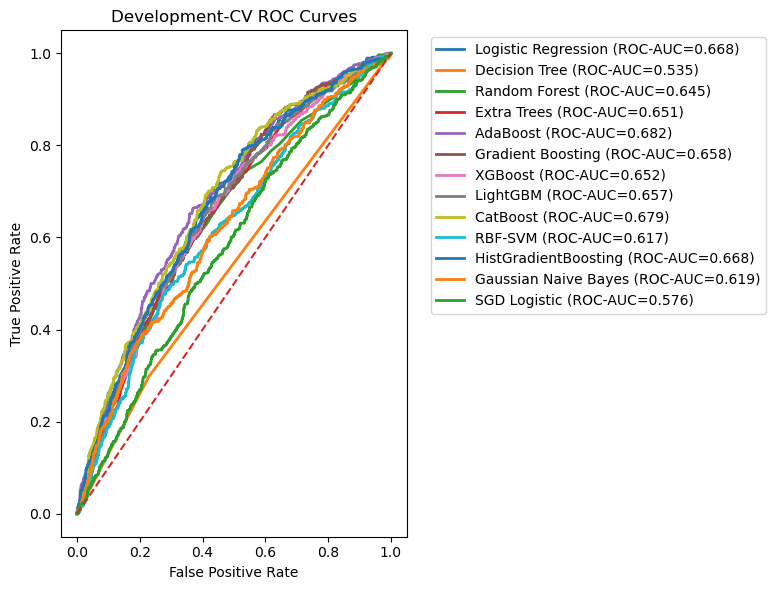


✓ ROC curves are based on PSU-grouped development-CV predictions.
✓ Final test data are not used in Step-17.


In [18]:
# ==========================================================
# Step-17 : Development-CV ROC Curves
#           NO FINAL TEST DATA
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)


plt.figure(
    figsize=(
        8,
        6
    )
)


for name, probability in default_cv_predictions.items():

    fpr, tpr, _ = roc_curve(

        y_train,

        probability,

        sample_weight=
            weights_train
    )


    roc_auc_value = roc_auc_score(

        y_train,

        probability,

        sample_weight=
            weights_train
    )


    plt.plot(

        fpr,

        tpr,

        linewidth=
            2,

        label=
            f"{name} "
            f"(ROC-AUC={roc_auc_value:.3f})"
    )


plt.plot(

    [
        0,
        1
    ],

    [
        0,
        1
    ],

    linestyle=
        "--"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Development-CV ROC Curves"
)

plt.legend(

    bbox_to_anchor=(
        1.05,
        1
    ),

    loc=
        "upper left"
)

plt.tight_layout()

plt.show()


print(
    "\n✓ ROC curves are based on "
    "PSU-grouped development-CV predictions."
)

print(
    "✓ Final test data are not used in Step-17."
)

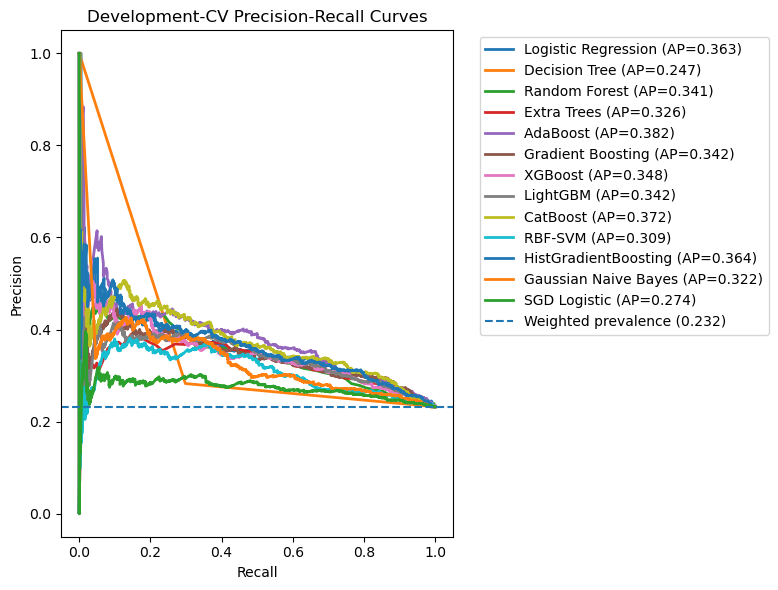


✓ Precision-recall curves are based on PSU-grouped development-CV predictions.
✓ Average Precision (AP) is reported.
✓ Final test data are not used in Step-18.


In [19]:
# ==========================================================
# Step-18 : Development-CV Precision-Recall Curves
#           NO FINAL TEST DATA
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)


plt.figure(
    figsize=(
        8,
        6
    )
)


for name, probability in default_cv_predictions.items():

    precision, recall, _ = precision_recall_curve(

        y_train,

        probability,

        sample_weight=
            weights_train
    )


    ap = average_precision_score(

        y_train,

        probability,

        sample_weight=
            weights_train
    )


    plt.plot(

        recall,

        precision,

        linewidth=
            2,

        label=
            f"{name} "
            f"(AP={ap:.3f})"
    )


weighted_prevalence = np.average(

    np.asarray(
        y_train,
        dtype=float
    ),

    weights=
        weights_train
)


plt.axhline(

    weighted_prevalence,

    linestyle=
        "--",

    label=
        f"Weighted prevalence "
        f"({weighted_prevalence:.3f})"
)


plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Development-CV Precision-Recall Curves"
)

plt.legend(

    bbox_to_anchor=(
        1.05,
        1
    ),

    loc=
        "upper left"
)

plt.tight_layout()

plt.show()


print(
    "\n✓ Precision-recall curves are based on "
    "PSU-grouped development-CV predictions."
)

print(
    "✓ Average Precision (AP) is reported."
)

print(
    "✓ Final test data are not used in Step-18."
)

In [20]:
# ==========================================================
# Step-19 : Best Model Selection From Development CV Only
#           PRIMARY CRITERION = MEAN FOLD ROC-AUC
# ==========================================================

import pandas as pd


print("=" * 70)

print(
    "FINAL MODEL FAMILY LOCKING"
)

print("=" * 70)


eligible_ranking_df = (

    default_df[

        default_df[
            "Model"
        ].apply(
            supports_survey_weight
        )
    ]

    .copy()
)


if eligible_ranking_df.empty:

    raise RuntimeError(

        "No survey-weight-capable model is "
        "available for final model selection."
    )


ranking_df = (

    eligible_ranking_df

    .sort_values(
        "Mean_Fold_AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nDevelopment-CV ranking by the "
    "prespecified Mean_Fold_AUC rule"
)


display(

    ranking_df[
        [
            "Model",
            "Mean_Fold_AUC",
            "SD_Fold_AUC",
            "Accuracy",
            "Balanced_Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "Kappa",
            "MCC",
            "AUC",
            "Average_Precision",
            "Brier",
            "LogLoss",
            "AUC_CI_Lower",
            "AUC_CI_Upper",
        ]
    ]

    .round(
        4
    )
)


best_model_name = ranking_df.loc[
    0,
    "Model"
]


best_model_template = models_default[
    best_model_name
]


best_model_params = (

    best_model_template
    .get_params()
)


print(
    "\nSelected model family:",
    best_model_name
)


print(
    "Selected/fixed model configuration:"
)


print(
    best_model_params
)


if len(
    ranking_df
) >= 3:

    print(
        "\nTop development-CV AUCs (descriptive):"
    )


    display(

        ranking_df.loc[

            :2,

            [
                "Model",
                "Mean_Fold_AUC",
                "SD_Fold_AUC"
            ]

        ].round(
            4
        )
    )


print(
    "\n✓ CatBoost or any other selected family "
    "is selected only by the prespecified rule."
)

print(
    "✓ Small differences in mean CV AUC are "
    "reported descriptively relative to "
    "fold-level variability."
)

print(
    "✓ No statement of statistical or "
    "definitive superiority is made."
)

print(
    "✓ Calibration and threshold selection "
    "are not performed in Step-19."
)

print(
    "✓ Final-test performance is not "
    "evaluated in Step-19."
)

FINAL MODEL FAMILY LOCKING

Development-CV ranking by the prespecified Mean_Fold_AUC rule


,Model,Mean_Fold_AUC,SD_Fold_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,Kappa,MCC,AUC,Average_Precision,Brier,LogLoss,AUC_CI_Lower,AUC_CI_Upper
0,CatBoost,0.6834,0.0279,0.7637,0.5224,0.4472,0.0717,0.9732,0.1235,0.0634,0.1000,0.6789,0.3724,0.1680,0.5173,0.6488,0.7086
1,AdaBoost,0.6825,0.0214,0.7711,0.5214,0.5780,0.0548,0.9879,0.1002,0.0624,0.1229,0.6822,0.3816,0.1945,0.5788,0.6525,0.7130
2,HistGradientBoosting,0.6729,0.0204,0.7574,0.5439,0.4341,0.1451,0.9428,0.2175,0.1144,0.1386,0.6682,0.3644,0.1805,0.5903,0.6344,0.6996
3,Logistic Regression,0.6711,0.0213,0.7580,0.5476,0.4406,0.1545,0.9406,0.2288,0.1230,0.1469,0.6678,0.3633,0.1716,0.5235,0.6369,0.6982
4,LightGBM,0.6608,0.0193,0.7477,0.5370,0.3849,0.1434,0.9306,0.2089,0.0948,0.1112,0.6571,0.3425,0.1839,0.5987,0.6247,0.6878
5,Gradient Boosting,0.6599,0.0233,0.7590,0.5363,0.4327,0.1203,0.9523,0.1882,0.0969,0.1246,0.6581,0.3422,0.1730,0.5263,0.6248,0.6892
6,Extra Trees,0.6555,0.0238,0.7523,0.5083,0.3065,0.0525,0.9640,0.0897,0.0233,0.0357,0.6510,0.3264,0.1727,0.5257,0.6225,0.6819
7,XGBoost,0.6550,0.0361,0.7557,0.5550,0.4373,0.1801,0.9299,0.2551,0.1383,0.1579,0.6518,0.3479,0.1959,0.7060,0.6228,0.6804
8,Random Forest,0.6504,0.0320,0.7657,0.5127,0.4515,0.0401,0.9852,0.0737,0.0372,0.0753,0.6455,0.3409,0.1707,0.5209,0.6099,0.6763
9,Gaussian Naive Bayes,0.6504,0.0259,0.4330,0.5661,0.2654,0.8148,0.3174,0.4004,0.0768,0.1235,0.6192,0.3217,0.5250,4.2137,0.5887,0.6545



Selected model family: CatBoost
Selected/fixed model configuration:
{'verbose': 0, 'random_state': 42}

Top development-CV AUCs (descriptive):


,Model,Mean_Fold_AUC,SD_Fold_AUC
0,CatBoost,0.6834,0.0279
1,AdaBoost,0.6825,0.0214
2,HistGradientBoosting,0.6729,0.0204



✓ CatBoost or any other selected family is selected only by the prespecified rule.
✓ Small differences in mean CV AUC are reported descriptively relative to fold-level variability.
✓ No statement of statistical or definitive superiority is made.
✓ Calibration and threshold selection are not performed in Step-19.
✓ Final-test performance is not evaluated in Step-19.


In [21]:
# ==========================================================
# Step-20 : Final Development Fit
#           + Cross-Fitted Calibration
#           + Cross-Fitted MCC Threshold Selection
#           + Final Calibrator Fit AFTER Threshold Lock
#
# NO FINAL-TEST PERFORMANCE EVALUATION
# ==========================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedGroupKFold
)
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    brier_score_loss
)


print("=" * 70)

print(
    "FINAL DEVELOPMENT FIT + "
    "CROSS-FITTED CALIBRATION/THRESHOLD"
)

print("=" * 70)


APPLY_PROBABILITY_CALIBRATION = True


# ==========================================================
# 1. MODEL-FITTING WEIGHT SENSITIVITY
# ==========================================================

weight_sensitivity_rows = []

weight_sensitivity_cv_predictions = {}


for strategy in WEIGHT_STRATEGIES:

    cv_probabilities = np.full(

        len(
            y_train
        ),

        np.nan,

        dtype=float
    )


    fold_auc_values = []


    for fold in development_fold_cache:

        model_fold = clone(
            best_model_template
        )


        fold_fit_weights = (
            make_training_fit_weights(

                fold[
                    "y_train"
                ],

                fold[
                    "survey_weight_train"
                ],

                strategy=
                    strategy
            )
        )


        model_fold.fit(

            fold[
                "X_train_scaled"
            ],

            fold[
                "y_train"
            ],

            sample_weight=
                fold_fit_weights
        )


        probability_valid = (

            model_fold

            .predict_proba(

                fold[
                    "X_valid_scaled"
                ]

            )[
                :,
                1
            ]
        )


        cv_probabilities[

            fold[
                "local_valid_idx"
            ]

        ] = probability_valid


        fold_auc_values.append(

            roc_auc_score(

                fold[
                    "y_valid"
                ],

                probability_valid,

                sample_weight=
                    fold[
                        "survey_weight_valid"
                    ]
            )
        )


    if np.isnan(
        cv_probabilities
    ).any():

        raise RuntimeError(

            "Missing development-CV probabilities "
            f"for {strategy}."
        )


    metrics = weighted_binary_metrics(

        y_true=
            y_train,

        pred=
            (
                cv_probabilities
                >=
                0.50
            ).astype(
                int
            ),

        prob=
            cv_probabilities,

        sample_weight=
            weights_train
    )


    weight_sensitivity_cv_predictions[
        strategy
    ] = cv_probabilities.copy()


    weight_sensitivity_rows.append({

        "Strategy":
            strategy,

        "Mean_CV_AUC":
            float(
                np.mean(
                    fold_auc_values
                )
            ),

        "SD_CV_AUC":
            float(
                np.std(
                    fold_auc_values,
                    ddof=1
                )
            ),

        "AUC":
            metrics[
                "AUC"
            ],

        "Average_Precision":
            metrics[
                "Average_Precision"
            ],

        "Brier":
            metrics[
                "Brier"
            ],

        "LogLoss":
            metrics[
                "LogLoss"
            ],
    })


weight_sensitivity_df = pd.DataFrame(

    weight_sensitivity_rows
)


display(

    weight_sensitivity_df.round(
        4
    )
)


best_weight_strategy = (
    "SurveyWeightOnly"
)


print(
    "Locked training-weight strategy:",
    best_weight_strategy
)


# ==========================================================
# 2. ONE FINAL DEVELOPMENT-ONLY RFECV REALIZATION
#
# This selected set is NOT interpreted
# as stable determinants.
# ==========================================================

calibration_prepared = prepare_rfecv_fold(

    global_train_indices=
        np.asarray(
            train_idx,
            dtype=int
        ),

    global_valid_indices=
        np.asarray(
            calibration_idx,
            dtype=int
        ),

    random_state=
        4242
)


selected_vars = list(

    calibration_prepared[
        "selected_vars"
    ]
)


model_features = list(

    calibration_prepared[
        "model_features"
    ]
)


rfecv_df = (

    calibration_prepared[
        "rfecv_df"
    ]

    .copy()
)


onehot_encoder = (

    calibration_prepared[
        "encoder"
    ]
)


encoded_nominal_columns = list(

    calibration_prepared[
        "encoded_names"
    ]
)


scaler = calibration_prepared[
    "scaler"
]


socio_encoded_features = (

    list(
        non_nominal_socio_vars
    )

    +

    encoded_nominal_columns
)


final_predictor_definition_df = (

    predictor_definition_df
    .copy()
)


# ==========================================================
# 3. DEVELOPMENT OBJECTS
# ==========================================================

X_train_raw = (

    calibration_prepared[
        "X_train_raw"
    ]

    .copy()
)


X_train = (

    calibration_prepared[
        "X_train_scaled"
    ]

    .copy()
)


y_train = pd.Series(

    calibration_prepared[
        "y_train"
    ],

    name=
        target
)


weights_train = np.asarray(

    calibration_prepared[
        "survey_weight_train"
    ],

    dtype=float
)


groups_train = np.asarray(

    calibration_prepared[
        "groups_train"
    ]
)


strata_train = np.asarray(

    calibration_prepared[
        "strata_train"
    ]
)


spatial_clusters_train = np.asarray(

    calibration_prepared[
        "spatial_clusters_train"
    ]
)


X_train_common_raw = (

    calibration_prepared[
        "X_common_train_raw"
    ]

    .copy()
)


# ==========================================================
# 4. CALIBRATION OBJECTS
# ==========================================================

X_calibration_raw = (

    calibration_prepared[
        "X_valid_raw"
    ]

    .copy()
)


X_calibration = (

    calibration_prepared[
        "X_valid_scaled"
    ]

    .copy()
)


y_calibration = pd.Series(

    calibration_prepared[
        "y_valid"
    ],

    name=
        target
)


weights_calibration = np.asarray(

    calibration_prepared[
        "survey_weight_valid"
    ],

    dtype=float
)


groups_calibration = np.asarray(

    calibration_prepared[
        "groups_valid"
    ]
)


strata_calibration = np.asarray(

    calibration_prepared[
        "strata_valid"
    ]
)


spatial_clusters_calibration = np.asarray(

    calibration_prepared[
        "spatial_clusters_valid"
    ]
)


X_calibration_common_raw = (

    calibration_prepared[
        "X_common_valid_raw"
    ]

    .copy()
)


# ==========================================================
# 5. LOCKED FINAL-TEST TRANSFORMATION
#
# No RFECV refit
# No encoder refit
# No scaler refit
# ==========================================================

def transform_with_locked_preprocessing(

    global_train_indices,
    global_valid_indices,
    reference_prepared
):

    global_train_indices = np.asarray(

        global_train_indices,

        dtype=int
    )


    global_valid_indices = np.asarray(

        global_valid_indices,

        dtype=int
    )


    train_clusters_locked = np.unique(

        df.iloc[
            global_train_indices
        ][
            "dhsclust"
        ].to_numpy()
    )


    valid_clusters_locked = np.unique(

        df.iloc[
            global_valid_indices
        ][
            "dhsclust"
        ].to_numpy()
    )


    if len(

        np.intersect1d(

            train_clusters_locked,

            valid_clusters_locked
        )

    ):

        raise RuntimeError(

            "DHS spatial-cluster leakage "
            "in locked transformation."
        )


    wx_locked = build_inductive_wx(

        data=
            df,

        train_clusters=
            train_clusters_locked,

        test_clusters=
            valid_clusters_locked,

        lag_vars=
            env_vars,

        k=
            K_NEIGHBORS
    )


    locked_df = (

        df

        .drop(

            columns=
                wx_vars,

            errors=
                "ignore"
        )

        .copy()
    )


    locked_df[
        "_row_order"
    ] = np.arange(
        len(
            locked_df
        )
    )


    locked_df = (

        locked_df

        .merge(

            wx_locked,

            on=
                "dhsclust",

            how=
                "left",

            validate=
                "many_to_one",

            sort=
                False
        )

        .sort_values(
            "_row_order"
        )

        .drop(
            columns=
                "_row_order"
        )

        .reset_index(
            drop=True
        )
    )


    encoder_locked = reference_prepared[
        "encoder"
    ]


    encoded_names_locked = list(

        reference_prepared[
            "encoded_names"
        ]
    )


    model_features_locked = list(

        reference_prepared[
            "model_features"
        ]
    )


    scaler_locked = reference_prepared[
        "scaler"
    ]


    valid_cat = (

        locked_df.iloc[
            global_valid_indices
        ][
            nominal_socio_vars
        ]
    )


    unseen_category_report = {}


    for variable, known_categories in zip(

        nominal_socio_vars,

        encoder_locked.categories_
    ):

        unseen = (

            set(

                valid_cat[
                    variable
                ]

                .dropna()

                .tolist()
            )

            -

            set(
                known_categories.tolist()
            )
        )


        if unseen:

            unseen_category_report[
                variable
            ] = sorted(

                unseen,

                key=
                    lambda value:
                        str(
                            value
                        )
            )


    with warnings.catch_warnings():

        warnings.filterwarnings(

            "ignore",

            message=
                "Found unknown categories.*",

            category=
                UserWarning
        )


        encoded_valid = (

            encoder_locked

            .transform(
                valid_cat
            )
        )


    encoded_valid_df = pd.DataFrame(

        encoded_valid,

        columns=
            encoded_names_locked
    )


    base_feature_names = (

        list(
            non_nominal_socio_vars
        )

        +

        list(
            env_vars
        )

        +

        list(
            wx_vars
        )
    )


    valid_base = (

        locked_df.iloc[
            global_valid_indices
        ][
            base_feature_names
        ]

        .reset_index(
            drop=True
        )

        .astype(
            float
        )
    )


    coord_valid = (

        locked_df.iloc[
            global_valid_indices
        ][
            [
                "lat",
                "lon"
            ]
        ]

        .reset_index(
            drop=True
        )

        .astype(
            float
        )
    )


    X_common_valid_raw = pd.concat(

        [
            valid_base,
            encoded_valid_df,
            coord_valid
        ],

        axis=
            1
    )


    missing_locked = [

        feature

        for feature
        in model_features_locked

        if feature not in X_common_valid_raw.columns
    ]


    if missing_locked:

        raise RuntimeError(

            "Locked model features missing "
            "from final test: "

            f"{missing_locked}"
        )


    X_valid_raw = (

        X_common_valid_raw[

            model_features_locked

        ].copy()
    )


    X_valid_scaled = pd.DataFrame(

        scaler_locked.transform(
            X_valid_raw
        ),

        columns=
            model_features_locked
    )


    return {

        "X_common_valid_raw":
            X_common_valid_raw,

        "X_valid_raw":
            X_valid_raw,

        "X_valid_scaled":
            X_valid_scaled,

        "y_valid":

            locked_df.iloc[
                global_valid_indices
            ][
                target
            ]

            .astype(
                int
            )

            .to_numpy(),

        "survey_weight_valid":

            locked_df.iloc[
                global_valid_indices
            ][
                "survey_weight"
            ]

            .astype(
                float
            )

            .to_numpy(),

        "groups_valid":

            locked_df.iloc[
                global_valid_indices
            ][
                "psu"
            ].to_numpy(),

        "strata_valid":

            locked_df.iloc[
                global_valid_indices
            ][
                "survey_stratum"
            ].to_numpy(),

        "spatial_clusters_valid":

            locked_df.iloc[
                global_valid_indices
            ][
                "dhsclust"
            ].to_numpy(),

        "unseen_category_report":
            unseen_category_report,
    }


final_test_locked = (
    transform_with_locked_preprocessing(

        global_train_indices=
            np.asarray(
                train_idx,
                dtype=int
            ),

        global_valid_indices=
            np.asarray(
                test_idx,
                dtype=int
            ),

        reference_prepared=
            calibration_prepared
    )
)


X_test_common_raw = (

    final_test_locked[
        "X_common_valid_raw"
    ]

    .copy()
)


X_test_raw = (

    final_test_locked[
        "X_valid_raw"
    ]

    .copy()
)


X_test = (

    final_test_locked[
        "X_valid_scaled"
    ]

    .copy()
)


y_test = pd.Series(

    final_test_locked[
        "y_valid"
    ],

    name=
        target
)


weights_test = np.asarray(

    final_test_locked[
        "survey_weight_valid"
    ],

    dtype=float
)


groups_test = np.asarray(

    final_test_locked[
        "groups_valid"
    ]
)


strata_test = np.asarray(

    final_test_locked[
        "strata_valid"
    ]
)


spatial_clusters_test = np.asarray(

    final_test_locked[
        "spatial_clusters_valid"
    ]
)


coords_train = (

    df.iloc[
        np.asarray(
            train_idx,
            dtype=int
        )
    ][
        [
            "lon",
            "lat"
        ]
    ]

    .to_numpy(
        dtype=float
    )
)


coords_calibration = (

    df.iloc[
        np.asarray(
            calibration_idx,
            dtype=int
        )
    ][
        [
            "lon",
            "lat"
        ]
    ]

    .to_numpy(
        dtype=float
    )
)


coords_test = (

    df.iloc[
        np.asarray(
            test_idx,
            dtype=int
        )
    ][
        [
            "lon",
            "lat"
        ]
    ]

    .to_numpy(
        dtype=float
    )
)


# ==========================================================
# 6. FIT LOCKED BASE MODEL
#    MODEL-DEVELOPMENT DATA ONLY
# ==========================================================

final_fit_weights = (
    make_training_fit_weights(

        y_train,

        weights_train,

        strategy=
            best_weight_strategy
    )
)


combined_train_weights = np.asarray(

    final_fit_weights,

    dtype=float

).copy()


final_model = clone(
    best_model_template
)


final_model.fit(

    X_train,

    y_train,

    sample_weight=
        final_fit_weights
)


# ==========================================================
# 7. RAW CALIBRATION PROBABILITIES
# ==========================================================

EPS = 1e-6


def probability_to_logit(
    probability
):

    probability = np.clip(

        np.asarray(
            probability,
            dtype=float
        ),

        EPS,

        1
        -
        EPS
    )


    return np.log(

        probability

        /

        (
            1.0
            -
            probability
        )
    )


calibration_probability_raw = (

    final_model

    .predict_proba(
        X_calibration
    )[
        :,
        1
    ]
)


calibration_y_array = np.asarray(

    y_calibration,

    dtype=int
)


calibration_weight_array = np.asarray(

    weights_calibration,

    dtype=float
)


calibration_group_array = np.asarray(

    groups_calibration
)


# ==========================================================
# 8. CROSS-FITTED CALIBRATED PROBABILITIES
#
# Threshold is selected ONLY from these OOF calibrated
# probabilities.
# ==========================================================

n_calibration_psu = len(

    np.unique(
        calibration_group_array
    )
)


if n_calibration_psu < 5:

    raise RuntimeError(

        "Not enough calibration PSUs for "
        "5-fold cross-fitted calibration."
    )


calibration_cv = StratifiedGroupKFold(

    n_splits=
        5,

    shuffle=
        True,

    random_state=
        2026
)


calibration_probability_oof = np.full(

    len(
        calibration_y_array
    ),

    np.nan,

    dtype=float
)


for fold_no, (

    fit_idx,
    valid_idx

) in enumerate(

    calibration_cv.split(

        np.zeros(
            len(
                calibration_y_array
            )
        ),

        calibration_y_array,

        groups=
            calibration_group_array
    ),

    start=
        1
):

    if len(

        np.intersect1d(

            calibration_group_array[
                fit_idx
            ],

            calibration_group_array[
                valid_idx
            ]
        )

    ):

        raise RuntimeError(

            f"Calibration PSU leakage in "
            f"cross-fit fold {fold_no}."
        )


    if np.unique(

        calibration_y_array[
            fit_idx
        ]

    ).size < 2:

        raise RuntimeError(

            f"Calibration training fold "
            f"{fold_no} has one outcome class."
        )


    fold_calibrator = LogisticRegression()


    fold_calibrator.fit(

        probability_to_logit(

            calibration_probability_raw[
                fit_idx
            ]

        ).reshape(
            -1,
            1
        ),

        calibration_y_array[
            fit_idx
        ],

        sample_weight=
            calibration_weight_array[
                fit_idx
            ]
    )


    calibration_probability_oof[
        valid_idx
    ] = (

        fold_calibrator

        .predict_proba(

            probability_to_logit(

                calibration_probability_raw[
                    valid_idx
                ]

            ).reshape(
                -1,
                1
            )

        )[
            :,
            1
        ]
    )


if np.isnan(

    calibration_probability_oof

).any():

    raise RuntimeError(

        "Cross-fitted calibration did not generate "
        "all calibration probabilities."
    )


raw_brier = brier_score_loss(

    calibration_y_array,

    calibration_probability_raw,

    sample_weight=
        calibration_weight_array
)


crossfitted_calibrated_brier = brier_score_loss(

    calibration_y_array,

    calibration_probability_oof,

    sample_weight=
        calibration_weight_array
)


print(

    "\nCalibration Brier - raw             :",

    round(
        raw_brier,
        6
    )
)


print(

    "Calibration Brier - cross-fitted cal:",

    round(
        crossfitted_calibrated_brier,
        6
    )
)


# ==========================================================
# 9. LOCK MCC THRESHOLD
#    USING CROSS-FITTED CALIBRATED PROBABILITIES
# ==========================================================

def weighted_mcc_at_threshold(

    y_true,
    prob,
    weight,
    threshold
):

    pred = (

        np.asarray(
            prob,
            dtype=float
        )

        >=

        threshold

    ).astype(
        int
    )


    cm = confusion_matrix(

        np.asarray(
            y_true,
            dtype=int
        ),

        pred,

        labels=[
            0,
            1
        ],

        sample_weight=
            np.asarray(
                weight,
                dtype=float
            )
    )


    tn, fp, fn, tp = cm.ravel()


    denominator = np.sqrt(

        (
            tp
            +
            fp
        )

        *

        (
            tp
            +
            fn
        )

        *

        (
            tn
            +
            fp
        )

        *

        (
            tn
            +
            fn
        )
    )


    return (

        (
            tp
            *
            tn

            -

            fp
            *
            fn
        )

        /
        denominator

        if denominator
        >
        0

        else

        np.nan
    )


candidate_thresholds = np.unique(

    calibration_probability_oof
)


threshold_rows = []


for threshold_value in candidate_thresholds:

    mcc_value = weighted_mcc_at_threshold(

        calibration_y_array,

        calibration_probability_oof,

        calibration_weight_array,

        float(
            threshold_value
        )
    )


    if np.isfinite(
        mcc_value
    ):

        threshold_rows.append({

            "Threshold":
                float(
                    threshold_value
                ),

            "MCC":
                float(
                    mcc_value
                ),
        })


mcc_threshold_df = pd.DataFrame(

    threshold_rows
)


if mcc_threshold_df.empty:

    raise RuntimeError(

        "No valid MCC threshold could be "
        "selected from cross-fitted "
        "calibration probabilities."
    )


best_threshold_row = mcc_threshold_df.loc[

    mcc_threshold_df[
        "MCC"
    ].idxmax()

]


final_threshold = float(

    best_threshold_row[
        "Threshold"
    ]
)


# This object is the threshold-selection probability.
calibration_probability = (

    calibration_probability_oof.copy()
)


print(

    "\nLocked MCC threshold from CROSS-FITTED "
    "calibrated probabilities:",

    round(
        final_threshold,
        6
    )
)


print(

    "Cross-fitted calibration weighted MCC:",

    round(

        float(
            best_threshold_row[
                "MCC"
            ]
        ),

        6
    )
)


# ==========================================================
# 10. AFTER THRESHOLD LOCK:
#     FIT FINAL CALIBRATOR ON ALL CALIBRATION DATA
# ==========================================================

probability_calibrator = LogisticRegression()


probability_calibrator.fit(

    probability_to_logit(

        calibration_probability_raw

    ).reshape(
        -1,
        1
    ),

    calibration_y_array,

    sample_weight=
        calibration_weight_array
)


def apply_probability_calibration(
    raw_probability
):

    return (

        probability_calibrator

        .predict_proba(

            probability_to_logit(

                raw_probability

            ).reshape(
                -1,
                1
            )

        )[
            :,
            1
        ]
    )


calibration_probability_fullfit = (
    apply_probability_calibration(

        calibration_probability_raw
    )
)


print(
    "\nFinal RFECV-selected feature count:",
    len(
        selected_vars
    )
)

print(
    "Final model feature count         :",
    len(
        model_features
    )
)

print(
    "Final-test unseen category audit  :",
    final_test_locked[
        "unseen_category_report"
    ]
)


print(
    "\n✓ Threshold was selected and locked from "
    "cross-fitted calibrated probabilities."
)

print(
    "✓ The final calibrator was fitted on all "
    "calibration observations only AFTER "
    "threshold locking."
)

print(
    "✓ The locked threshold will be applied "
    "only to the final test in Step-21/22."
)

print(
    "✓ Final RFECV-selected variables are one "
    "predictive-model realization, not stable "
    "determinants."
)

print(
    "✓ No final-test performance metric is "
    "calculated in Step-20."
)

FINAL DEVELOPMENT FIT + CROSS-FITTED CALIBRATION/THRESHOLD


,Strategy,Mean_CV_AUC,SD_CV_AUC,AUC,Average_Precision,Brier,LogLoss
0,SurveyWeightOnly,0.6834,0.0279,0.6789,0.3724,0.1680,0.5173
1,SurveyWeight_ClassBalanced,0.6778,0.0290,0.6755,0.3703,0.1818,0.5438


Locked training-weight strategy: SurveyWeightOnly

Calibration Brier - raw             : 0.167426
Calibration Brier - cross-fitted cal: 0.167422

Locked MCC threshold from CROSS-FITTED calibrated probabilities: 0.247229
Cross-fitted calibration weighted MCC: 0.192542

Final RFECV-selected feature count: 21
Final model feature count         : 23
Final-test unseen category audit  : {}

✓ Threshold was selected and locked from cross-fitted calibrated probabilities.
✓ The final calibrator was fitted on all calibration observations only AFTER threshold locking.
✓ The locked threshold will be applied only to the final test in Step-21/22.
✓ Final RFECV-selected variables are one predictive-model realization, not stable determinants.
✓ No final-test performance metric is calculated in Step-20.


In [22]:
# ==========================================================
# Step-21 : First Final-Test Performance Evaluation
#           + 16-Stratum Conditional PSU-Bootstrap AUC CI
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)


print("=" * 70)
print("FIRST FINAL-TEST MODEL-PERFORMANCE EVALUATION")
print("=" * 70)


# ==========================================================
# 1. SURVEY-STRATUM AUDIT
# ==========================================================

EXPECTED_SURVEY_STRATA = 16

observed_survey_strata = int(
    df[
        "survey_stratum"
    ].nunique(
        dropna=True
    )
)

if observed_survey_strata != EXPECTED_SURVEY_STRATA:
    raise RuntimeError(
        f"Expected {EXPECTED_SURVEY_STRATA} survey strata; "
        f"found {observed_survey_strata}."
    )


# ==========================================================
# 2. FINAL-TEST RAW PROBABILITIES
# ==========================================================

y_prob_raw = (
    final_model
    .predict_proba(
        X_test
    )[
        :,
        1
    ]
)


# ==========================================================
# 3. APPLY FINAL CALIBRATOR
# ==========================================================

y_prob = apply_probability_calibration(
    y_prob_raw
)


# ==========================================================
# 4. APPLY LOCKED THRESHOLD
# ==========================================================

y_pred = (
    y_prob
    >=
    final_threshold
).astype(
    int
)


# ==========================================================
# 5. FINAL-TEST POINT ESTIMATES
# ==========================================================

final_test_auc = roc_auc_score(
    y_test,
    y_prob,
    sample_weight=weights_test
)


final_test_ap = average_precision_score(
    y_test,
    y_prob,
    sample_weight=weights_test
)


final_test_brier = brier_score_loss(
    y_test,
    y_prob,
    sample_weight=weights_test
)


# ==========================================================
# 6. CONDITIONAL STRATIFIED PSU-BOOTSTRAP AUC CI
# ==========================================================

(
    final_auc_ci_lower,
    final_auc_ci_upper

) = stratified_psu_bootstrap_auc_ci(

    y_true=
        y_test,

    y_prob=
        y_prob,

    psu=
        groups_test,

    strata=
        strata_test,

    sample_weight=
        weights_test,

    n_bootstrap=
        1000,

    random_state=
        2026
)


# ==========================================================
# 7. SAVE FINAL-TEST SUMMARY
# ==========================================================

final_test_metrics_df = pd.DataFrame([
    {

        "Model":
            best_model_name,

        "ROC_AUC":
            final_test_auc,

        "AUC_CI_Lower":
            final_auc_ci_lower,

        "AUC_CI_Upper":
            final_auc_ci_upper,

        "Average_Precision":
            final_test_ap,

        "Brier":
            final_test_brier,

        "Threshold":
            final_threshold,

        "Survey_Strata":
            EXPECTED_SURVEY_STRATA,

        "CI_Interpretation":
            (
                "Conditional final-test "
                "stratified PSU-resampling uncertainty"
            ),
    }
])


display(
    final_test_metrics_df.round(
        4
    )
)


# ==========================================================
# 8. PRINT RESULTS
# ==========================================================

print(
    "\nFinal-test ROC-AUC:",
    round(
        final_test_auc,
        4
    )
)


print(
    "Conditional stratified PSU-bootstrap 95% CI:",
    f"{final_auc_ci_lower:.4f}"
    "-"
    f"{final_auc_ci_upper:.4f}"
)


print(
    "Average Precision:",
    round(
        final_test_ap,
        4
    )
)


print(
    "Brier score:",
    round(
        final_test_brier,
        4
    )
)


print(
    "Survey-stratum levels:",
    observed_survey_strata
)


print(
    "\n✓ Final-test predictions were generated "
    "only after model selection and calibration."
)

print(
    "✓ Locked threshold from Step-20 was used."
)

print(
    "✓ CI conditions on the already "
    "fitted/selected/calibrated pipeline."
)

print(
    "✓ CI does not include uncertainty from "
    "feature selection, model selection, "
    "calibration, or model refitting."
)

FIRST FINAL-TEST MODEL-PERFORMANCE EVALUATION


,Model,ROC_AUC,AUC_CI_Lower,AUC_CI_Upper,Average_Precision,Brier,Threshold,Survey_Strata,CI_Interpretation
0,CatBoost,0.6481,0.5999,0.6902,0.3258,0.1657,0.2472,16,Conditional final-test stratified PSU-resampli...



Final-test ROC-AUC: 0.6481
Conditional stratified PSU-bootstrap 95% CI: 0.5999-0.6902
Average Precision: 0.3258
Brier score: 0.1657
Survey-stratum levels: 16

✓ Final-test predictions were generated only after model selection and calibration.
✓ Locked threshold from Step-20 was used.
✓ CI conditions on the already fitted/selected/calibrated pipeline.
✓ CI does not include uncertainty from feature selection, model selection, calibration, or model refitting.


In [23]:
# ==========================================================
# Step-22 : Final-Test Threshold Metrics + Calibration
#           + 16-Stratum Conditional PSU-Bootstrap CIs
# ==========================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
import warnings


print("=" * 70)
print(
    "FINAL TEST PREDICTION + "
    "CONDITIONAL PSU-BOOTSTRAP CIs"
)
print("=" * 70)


# ==========================================================
# 1. SURVEY-STRATUM AUDIT
# ==========================================================

EXPECTED_SURVEY_STRATA = 16

observed_survey_strata = int(
    df[
        "survey_stratum"
    ].nunique(
        dropna=True
    )
)

if observed_survey_strata != EXPECTED_SURVEY_STRATA:
    raise RuntimeError(
        f"Expected {EXPECTED_SURVEY_STRATA} survey strata; "
        f"found {observed_survey_strata}."
    )


# ==========================================================
# 2. FINAL PREDICTION USING LOCKED THRESHOLD
# ==========================================================

y_pred = (
    np.asarray(
        y_prob,
        dtype=float
    )
    >=
    final_threshold
).astype(
    int
)


# ==========================================================
# 3. WEIGHTED FINAL-TEST METRICS
# ==========================================================

final_test_metrics = weighted_binary_metrics(

    y_true=
        y_test,

    pred=
        y_pred,

    prob=
        y_prob,

    sample_weight=
        weights_test
)


# ==========================================================
# 4. FINAL-TEST CALIBRATION INTERCEPT / SLOPE
# ==========================================================

prob_safe = np.clip(
    np.asarray(
        y_prob,
        dtype=float
    ),
    1e-6,
    1 - 1e-6
)


logit_prob = np.log(
    prob_safe
    /
    (
        1.0
        -
        prob_safe
    )
)


X_cal_test = sm.add_constant(
    logit_prob
)


with warnings.catch_warnings():

    warnings.simplefilter(
        "ignore"
    )

    calibration_assessment = sm.GLM(

        np.asarray(
            y_test,
            dtype=float
        ),

        X_cal_test,

        family=
            sm.families.Binomial(),

        freq_weights=
            np.asarray(
                weights_test,
                dtype=float
            )

    ).fit()


calibration_intercept_test = float(
    calibration_assessment.params[
        0
    ]
)


calibration_slope_test = float(
    calibration_assessment.params[
        1
    ]
)


# ==========================================================
# 5. BOOTSTRAP CONFIGURATION
# ==========================================================

N_FINAL_BOOTSTRAP = 1000

FINAL_BOOTSTRAP_RANDOM_STATE = 42


rng = np.random.default_rng(
    FINAL_BOOTSTRAP_RANDOM_STATE
)


y_test_array = np.asarray(
    y_test,
    dtype=int
)


y_prob_array = np.asarray(
    y_prob,
    dtype=float
)


weights_test_array = np.asarray(
    weights_test,
    dtype=float
)


groups_test_array = np.asarray(
    groups_test
)


strata_test_array = np.asarray(
    strata_test
)


print(
    "Full analytical survey-stratum levels:",
    observed_survey_strata
)

print(
    "Survey strata represented in final test:",
    np.unique(
        strata_test_array
    ).size
)


# ==========================================================
# 6. BOOTSTRAP STORAGE
# ==========================================================

bootstrap_metric_names = [

    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "MCC",
]


bootstrap_metric_values = {

    metric_name:
        []

    for metric_name
    in bootstrap_metric_names
}


bootstrap_calibration_intercept = []

bootstrap_calibration_slope = []


# ==========================================================
# 7. STRATIFIED PSU BOOTSTRAP
# ==========================================================

for _ in range(
    N_FINAL_BOOTSTRAP
):

    sampled_indices = []


    for stratum_value in np.unique(
        strata_test_array
    ):

        stratum_mask = (
            strata_test_array
            ==
            stratum_value
        )


        psus_in_stratum = np.unique(

            groups_test_array[
                stratum_mask
            ]
        )


        if len(
            psus_in_stratum
        ) == 0:

            continue


        sampled_psus = rng.choice(

            psus_in_stratum,

            size=
                len(
                    psus_in_stratum
                ),

            replace=True
        )


        for sampled_psu in sampled_psus:

            sampled_indices.extend(

                np.where(

                    stratum_mask

                    &

                    (
                        groups_test_array
                        ==
                        sampled_psu
                    )

                )[0].tolist()
            )


    sampled_indices = np.asarray(
        sampled_indices,
        dtype=int
    )


    if len(
        sampled_indices
    ) == 0:

        continue


    y_boot = y_test_array[
        sampled_indices
    ]


    if np.unique(
        y_boot
    ).size < 2:

        continue


    prob_boot = y_prob_array[
        sampled_indices
    ]


    weight_boot = weights_test_array[
        sampled_indices
    ]


    pred_boot = (
        prob_boot
        >=
        final_threshold
    ).astype(
        int
    )


    metrics_boot = weighted_binary_metrics(

        y_true=
            y_boot,

        pred=
            pred_boot,

        prob=
            prob_boot,

        sample_weight=
            weight_boot
    )


    for metric_name in bootstrap_metric_names:

        value = metrics_boot[
            metric_name
        ]


        if np.isfinite(
            value
        ):

            bootstrap_metric_values[
                metric_name
            ].append(
                float(
                    value
                )
            )


    # ------------------------------------------------------
    # Calibration intercept / slope for bootstrap sample
    # ------------------------------------------------------

    prob_boot_safe = np.clip(
        prob_boot,
        1e-6,
        1 - 1e-6
    )


    logit_boot = np.log(
        prob_boot_safe
        /
        (
            1.0
            -
            prob_boot_safe
        )
    )


    try:

        with warnings.catch_warnings():

            warnings.simplefilter(
                "ignore"
            )


            calibration_boot = sm.GLM(

                y_boot.astype(
                    float
                ),

                sm.add_constant(
                    logit_boot
                ),

                family=
                    sm.families.Binomial(),

                freq_weights=
                    weight_boot

            ).fit()


        intercept_boot = float(
            calibration_boot.params[
                0
            ]
        )


        slope_boot = float(
            calibration_boot.params[
                1
            ]
        )


        if np.isfinite(
            intercept_boot
        ):

            bootstrap_calibration_intercept.append(
                intercept_boot
            )


        if np.isfinite(
            slope_boot
        ):

            bootstrap_calibration_slope.append(
                slope_boot
            )


    except Exception:

        pass


# ==========================================================
# 8. PERCENTILE CI FUNCTION
# ==========================================================

def percentile_ci(
    values
):

    values = np.asarray(
        values,
        dtype=float
    )


    values = values[
        np.isfinite(
            values
        )
    ]


    if len(
        values
    ) == 0:

        return (
            np.nan,
            np.nan
        )


    return (
        float(
            np.percentile(
                values,
                2.5
            )
        ),
        float(
            np.percentile(
                values,
                97.5
            )
        )
    )


# ==========================================================
# 9. BOOTSTRAP CIs
# ==========================================================

final_metric_ci = {

    metric_name:
        percentile_ci(
            bootstrap_metric_values[
                metric_name
            ]
        )

    for metric_name
    in bootstrap_metric_names
}


(
    calibration_intercept_ci_lower,
    calibration_intercept_ci_upper

) = percentile_ci(
    bootstrap_calibration_intercept
)


(
    calibration_slope_ci_lower,
    calibration_slope_ci_upper

) = percentile_ci(
    bootstrap_calibration_slope
)


# ==========================================================
# 10. FINAL METRICS DATAFRAME
# ==========================================================

final_test_metrics_df = pd.DataFrame([
    {

        "Model":
            best_model_name,

        "Threshold":
            final_threshold,

        "Accuracy":
            final_test_metrics[
                "Accuracy"
            ],

        "Balanced_Accuracy":
            final_test_metrics[
                "Balanced_Accuracy"
            ],

        "Balanced_Accuracy_CI_Lower":
            final_metric_ci[
                "Balanced_Accuracy"
            ][0],

        "Balanced_Accuracy_CI_Upper":
            final_metric_ci[
                "Balanced_Accuracy"
            ][1],

        "Precision":
            final_test_metrics[
                "Precision"
            ],

        "Precision_CI_Lower":
            final_metric_ci[
                "Precision"
            ][0],

        "Precision_CI_Upper":
            final_metric_ci[
                "Precision"
            ][1],

        "Recall":
            final_test_metrics[
                "Recall"
            ],

        "Recall_CI_Lower":
            final_metric_ci[
                "Recall"
            ][0],

        "Recall_CI_Upper":
            final_metric_ci[
                "Recall"
            ][1],

        "Specificity":
            final_test_metrics[
                "Specificity"
            ],

        "Specificity_CI_Lower":
            final_metric_ci[
                "Specificity"
            ][0],

        "Specificity_CI_Upper":
            final_metric_ci[
                "Specificity"
            ][1],

        "F1":
            final_test_metrics[
                "F1"
            ],

        "F1_CI_Lower":
            final_metric_ci[
                "F1"
            ][0],

        "F1_CI_Upper":
            final_metric_ci[
                "F1"
            ][1],

        "Kappa":
            final_test_metrics[
                "Kappa"
            ],

        "MCC":
            final_test_metrics[
                "MCC"
            ],

        "MCC_CI_Lower":
            final_metric_ci[
                "MCC"
            ][0],

        "MCC_CI_Upper":
            final_metric_ci[
                "MCC"
            ][1],

        "AUC":
            final_test_metrics[
                "AUC"
            ],

        "AUC_CI_Lower":
            final_auc_ci_lower,

        "AUC_CI_Upper":
            final_auc_ci_upper,

        "Average_Precision":
            final_test_metrics[
                "Average_Precision"
            ],

        "Brier":
            final_test_metrics[
                "Brier"
            ],

        "LogLoss":
            final_test_metrics[
                "LogLoss"
            ],

        "Calibration_Intercept":
            calibration_intercept_test,

        "Calibration_Intercept_CI_Lower":
            calibration_intercept_ci_lower,

        "Calibration_Intercept_CI_Upper":
            calibration_intercept_ci_upper,

        "Calibration_Slope":
            calibration_slope_test,

        "Calibration_Slope_CI_Lower":
            calibration_slope_ci_lower,

        "Calibration_Slope_CI_Upper":
            calibration_slope_ci_upper,

        "Survey_Strata":
            EXPECTED_SURVEY_STRATA,

        "CI_Interpretation":
            (
                "Conditional final-test "
                "stratified PSU-resampling uncertainty"
            ),
    }
])


# ==========================================================
# 11. PRINT RESULTS
# ==========================================================

print(
    "Selected model:",
    best_model_name
)


print(
    "Locked cross-fitted-calibration threshold:",
    round(
        final_threshold,
        4
    )
)


print(
    "Calibration intercept:",
    round(
        calibration_intercept_test,
        4
    ),
    "conditional 95% PSU-bootstrap CI:",
    f"{calibration_intercept_ci_lower:.4f}"
    "-"
    f"{calibration_intercept_ci_upper:.4f}"
)


print(
    "Calibration slope:",
    round(
        calibration_slope_test,
        4
    ),
    "conditional 95% PSU-bootstrap CI:",
    f"{calibration_slope_ci_lower:.4f}"
    "-"
    f"{calibration_slope_ci_upper:.4f}"
)


print(
    "\nFINAL TEST METRICS"
)


display(
    final_test_metrics_df.round(
        4
    )
)


print(
    "\n✓ Threshold was locked in Step-20 "
    "using cross-fitted calibrated probabilities "
    "from the calibration sample."
)


print(
    f"✓ Bootstrap uses the retained "
    f"{EXPECTED_SURVEY_STRATA}-level "
    f"survey_stratum variable."
)


print(
    "✓ These confidence intervals are "
    "conditional final-test/PSU-resampling "
    "uncertainty only."
)


print(
    "✓ They do not include feature-selection, "
    "model-selection, calibration-fitting, "
    "or model-refitting uncertainty."
)


print(
    "✓ Final test data are not used to "
    "refit or modify the pipeline."
)

FINAL TEST PREDICTION + CONDITIONAL PSU-BOOTSTRAP CIs
Full analytical survey-stratum levels: 16
Survey strata represented in final test: 16
Selected model: CatBoost
Locked cross-fitted-calibration threshold: 0.2472
Calibration intercept: 0.1607 conditional 95% PSU-bootstrap CI: -0.3532-0.6690
Calibration slope: 1.0585 conditional 95% PSU-bootstrap CI: 0.7007-1.4426

FINAL TEST METRICS


,Model,Threshold,Accuracy,Balanced_Accuracy,Balanced_Accuracy_CI_Lower,Balanced_Accuracy_CI_Upper,Precision,Precision_CI_Lower,Precision_CI_Upper,Recall,...,Brier,LogLoss,Calibration_Intercept,Calibration_Intercept_CI_Lower,Calibration_Intercept_CI_Upper,Calibration_Slope,Calibration_Slope_CI_Lower,Calibration_Slope_CI_Upper,Survey_Strata,CI_Interpretation
0,CatBoost,0.2472,0.662,0.5667,0.5224,0.6121,0.3015,0.2391,0.3593,0.3952,...,0.1657,0.508,0.1607,-0.3532,0.669,1.0585,0.7007,1.4426,16,Conditional final-test stratified PSU-resampli...



✓ Threshold was locked in Step-20 using cross-fitted calibrated probabilities from the calibration sample.
✓ Bootstrap uses the retained 16-level survey_stratum variable.
✓ These confidence intervals are conditional final-test/PSU-resampling uncertainty only.
✓ They do not include feature-selection, model-selection, calibration-fitting, or model-refitting uncertainty.
✓ Final test data are not used to refit or modify the pipeline.


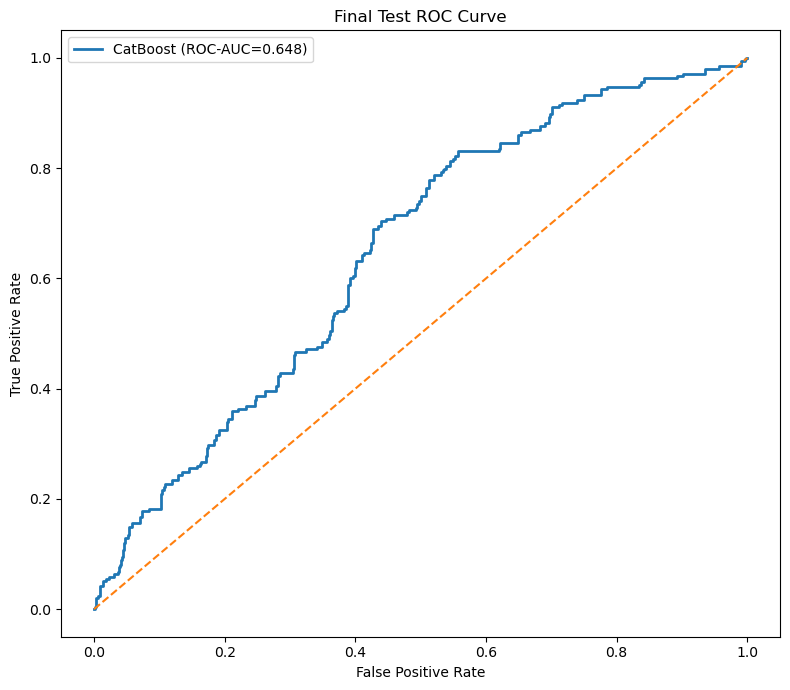

In [24]:
# ==========================================================
# Step-23 : Final Test ROC Curve
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

fpr_test, tpr_test, _ = roc_curve(

    y_test,

    y_prob,

    sample_weight=
        weights_test
)

roc_auc_test = roc_auc_score(

    y_test,

    y_prob,

    sample_weight=
        weights_test
)

plt.figure(
    figsize=(
        8,
        7
    )
)

plt.plot(

    fpr_test,

    tpr_test,

    linewidth=2,

    label=
        f"{best_model_name} "
        f"(ROC-AUC={roc_auc_test:.3f})"
)

plt.plot(
    [
        0,
        1
    ],
    [
        0,
        1
    ],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Final Test ROC Curve"
)

plt.legend()

plt.tight_layout()

plt.show()

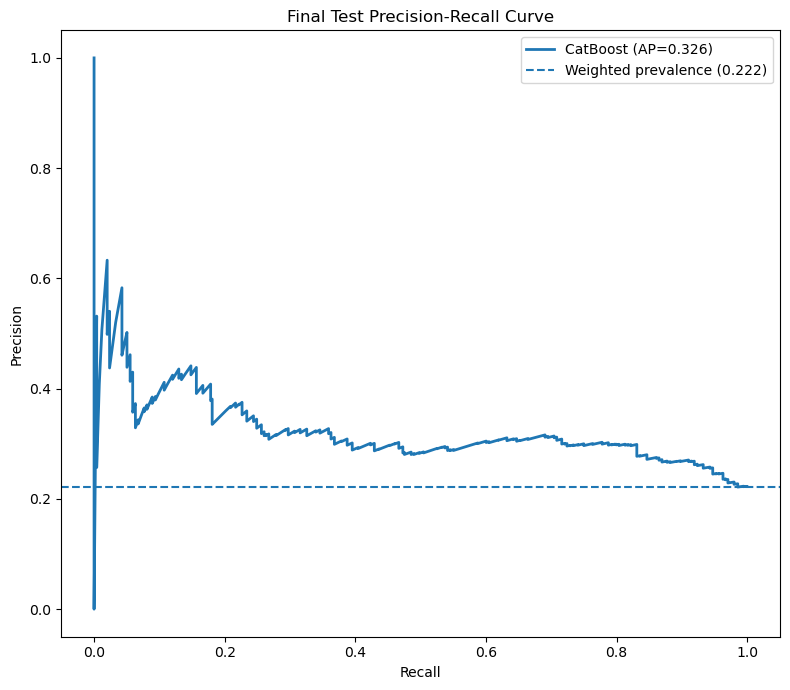

In [25]:
# ==========================================================
# Step-24 : FINAL TEST PRECISION-RECALL CURVE
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_test, recall_test, _ = (

    precision_recall_curve(

        y_test,

        y_prob,

        sample_weight=
            weights_test

    )

)

ap_test = average_precision_score(

    y_test,

    y_prob,

    sample_weight=
        weights_test

)

weighted_test_prevalence = np.average(

    np.asarray(
        y_test,
        dtype=float
    ),

    weights=
        weights_test

)

plt.figure(
    figsize=(
        8,
        7
    )
)

plt.plot(

    recall_test,

    precision_test,

    linewidth=2,

    label=
        f"{best_model_name} "
        f"(AP={ap_test:.3f})"

)

plt.axhline(

    weighted_test_prevalence,

    linestyle="--",

    label=
        f"Weighted prevalence "
        f"({weighted_test_prevalence:.3f})"

)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Final Test Precision-Recall Curve"
)

plt.legend()

plt.tight_layout()

plt.show()

In [26]:
# ==========================================================
# Step-25 : Descriptive Residual
#            Spatial-Autocorrelation Diagnostic
#
#            Global Moran's I
#            + Local Moran's I / LISA
#            + Benjamini-Hochberg FDR
# ==========================================================

import numpy as np
import pandas as pd

from libpysal.weights import W

from esda.moran import (
    Moran,
    Moran_Local
)

from sklearn.neighbors import BallTree

from statsmodels.stats.multitest import (
    multipletests
)


print("=" * 70)

print(
    "DESCRIPTIVE RESIDUAL "
    "SPATIAL-AUTOCORRELATION DIAGNOSTIC"
)

print("=" * 70)


# ==========================================================
# 1. PREDICTION RESIDUALS
# ==========================================================

residuals = (

    np.asarray(
        y_test,
        dtype=float
    )

    -

    np.asarray(
        y_prob,
        dtype=float
    )
)


# ==========================================================
# 2. CHILD-LEVEL TABLE
# ==========================================================

residual_df = pd.DataFrame({

    "dhsclust":
        spatial_clusters_test,

    "lon":
        coords_test[
            :,
            0
        ],

    "lat":
        coords_test[
            :,
            1
        ],

    "residual":
        residuals,

    "survey_weight":
        weights_test
})


# ==========================================================
# 3. SURVEY-WEIGHTED CLUSTER RESIDUAL
# ==========================================================

cluster_rows = []


for cluster_id, group in residual_df.groupby(

    "dhsclust",

    sort=False
):

    residual_values = (

        group[
            "residual"
        ]

        .to_numpy(
            dtype=float
        )
    )


    weight_values = (

        group[
            "survey_weight"
        ]

        .to_numpy(
            dtype=float
        )
    )


    valid_weight_mask = (

        np.isfinite(
            weight_values
        )

        &

        (
            weight_values > 0
        )

        &

        np.isfinite(
            residual_values
        )
    )


    if not np.any(
        valid_weight_mask
    ):

        raise RuntimeError(

            "No valid residual/weight values "
            f"for DHS cluster {cluster_id}."
        )


    cluster_rows.append({

        "dhsclust":
            cluster_id,

        "lon":
            float(
                group[
                    "lon"
                ].iloc[
                    0
                ]
            ),

        "lat":
            float(
                group[
                    "lat"
                ].iloc[
                    0
                ]
            ),

        "residual":
            float(

                np.average(

                    residual_values[
                        valid_weight_mask
                    ],

                    weights=
                        weight_values[
                            valid_weight_mask
                        ]
                )
            )
    })


cluster_residual = pd.DataFrame(
    cluster_rows
)


# ==========================================================
# 4. HAVERSINE KNN
# ==========================================================

if (

    len(
        cluster_residual
    )

    <=

    K_NEIGHBORS

):

    raise RuntimeError(

        "Not enough test DHS clusters for "
        "the requested residual KNN diagnostic."
    )


coords_rad = np.radians(

    cluster_residual[
        [
            "lat",
            "lon"
        ]
    ]

    .to_numpy(
        dtype=float
    )
)


tree = BallTree(

    coords_rad,

    metric=
        "haversine"
)


neighbor_candidates = tree.query(

    coords_rad,

    k=
        K_NEIGHBORS
        +
        1,

    return_distance=
        False
)


neighbor_idx = []


for row_i, candidate_idx in enumerate(
    neighbor_candidates
):

    valid_neighbors = [

        int(
            j
        )

        for j
        in candidate_idx

        if int(
            j
        )
        !=
        row_i
    ]


    if len(
        valid_neighbors
    ) < K_NEIGHBORS:

        raise RuntimeError(

            "Unable to identify enough "
            "non-self neighbours for "
            "residual Moran diagnostic."
        )


    neighbor_idx.append(

        valid_neighbors[
            :K_NEIGHBORS
        ]
    )


neighbor_idx = np.asarray(

    neighbor_idx,

    dtype=int
)


neighbors = {

    i:
        neighbor_idx[
            i
        ].tolist()

    for i
    in range(
        len(
            cluster_residual
        )
    )
}


moran_weights_dict = {

    i:

        [
            1.0
        ]

        *

        len(
            neighbors[
                i
            ]
        )

    for i
    in neighbors
}


w_residual = W(

    neighbors,

    moran_weights_dict,

    silence_warnings=
        True
)


w_residual.transform = (
    "R"
)


# ==========================================================
# 5. CONNECTIVITY AUDIT
# ==========================================================

n_components = int(
    w_residual.n_components
)


print(

    "DHS clusters in residual diagnostic:",

    len(
        cluster_residual
    )
)


print(
    "K neighbours:",
    K_NEIGHBORS
)


print(

    "Spatial-weight connected components:",

    n_components
)


if n_components > 1:

    print(

        f"NOTE: The KNN spatial-weights graph "
        f"contains {n_components} disconnected "
        "components. Global and local Moran "
        "diagnostics are retained as descriptive "
        "KNN diagnostics and should be interpreted "
        "with this connectivity limitation in mind."
    )


# ==========================================================
# 6. GLOBAL MORAN'S I
# ==========================================================

np.random.seed(
    42
)


moran_residual = Moran(

    cluster_residual[
        "residual"
    ]

    .to_numpy(
        dtype=float
    ),

    w_residual,

    permutations=
        999
)


print(
    "\nGLOBAL MORAN'S I"
)


print(

    "Moran's I      :",

    round(
        moran_residual.I,
        4
    )
)


print(

    "Expected I     :",

    round(
        moran_residual.EI,
        4
    )
)


print(

    "Permutation p  :",

    round(
        moran_residual.p_sim,
        4
    )
)


alpha = 0.05


if (

    moran_residual.p_sim

    <

    alpha

):

    print(

        "Interpretation : Evidence of global "
        "residual spatial autocorrelation "
        "at alpha = 0.05."
    )

else:

    print(

        "Interpretation : No statistically "
        "significant evidence of global "
        "residual spatial autocorrelation "
        "at alpha = 0.05."
    )


# ==========================================================
# 7. LOCAL MORAN'S I / LISA
# ==========================================================

local_moran_residual = Moran_Local(

    cluster_residual[
        "residual"
    ]

    .to_numpy(
        dtype=float
    ),

    w_residual,

    permutations=
        999,

    geoda_quads=
        False,

    seed=
        42
)


# ==========================================================
# 8. RAW LOCAL PERMUTATION P-VALUES
# ==========================================================

local_p_raw = np.asarray(

    local_moran_residual.p_sim,

    dtype=float
)


# ==========================================================
# 9. BENJAMINI-HOCHBERG FDR
# ==========================================================

(
    local_reject_fdr,
    local_p_fdr,
    _,
    _

) = multipletests(

    local_p_raw,

    alpha=
        0.05,

    method=
        "fdr_bh"
)


# ==========================================================
# 10. LISA QUADRANTS
# ==========================================================

lisa_quadrant_map = {

    1:
        "High-High",

    2:
        "Low-High",

    3:
        "Low-Low",

    4:
        "High-Low"
}


cluster_residual[
    "Local_Moran_I"
] = (

    local_moran_residual.Is
)


cluster_residual[
    "Local_Moran_p_raw"
] = (

    local_p_raw
)


cluster_residual[
    "Local_Moran_p_FDR"
] = (

    local_p_fdr
)


cluster_residual[
    "Local_Moran_FDR_Significant"
] = (

    local_reject_fdr
)


cluster_residual[
    "LISA_Quadrant"
] = [

    lisa_quadrant_map.get(

        int(
            q
        ),

        "Unknown"
    )

    for q
    in local_moran_residual.q
]


cluster_residual[
    "LISA_Pattern_FDR"
] = np.where(

    cluster_residual[
        "Local_Moran_FDR_Significant"
    ],

    cluster_residual[
        "LISA_Quadrant"
    ],

    "Not significant"
)


# ==========================================================
# 11. LOCAL SUMMARY
# ==========================================================

n_local_raw = int(

    np.sum(
        local_p_raw
        <
        0.05
    )
)


n_local_fdr = int(

    np.sum(
        local_reject_fdr
    )
)


print(
    "\nLOCAL MORAN'S I / LISA"
)


print(

    "Clusters with raw local p < 0.05 :",

    n_local_raw
)


print(

    "FDR-significant local clusters   :",

    n_local_fdr
)


lisa_fdr_summary = (

    cluster_residual.loc[

        cluster_residual[
            "Local_Moran_FDR_Significant"
        ],

        "LISA_Quadrant"
    ]

    .value_counts()

    .rename_axis(
        "LISA_Quadrant"
    )

    .reset_index(
        name=
            "N_Clusters"
    )
)


print(
    "\nFDR-significant LISA patterns"
)


display(
    lisa_fdr_summary
)


# ==========================================================
# 12. FULL LOCAL MORAN RESULT TABLE
# ==========================================================

local_moran_results = (

    cluster_residual[
        [
            "dhsclust",
            "lon",
            "lat",
            "residual",
            "Local_Moran_I",
            "Local_Moran_p_raw",
            "Local_Moran_p_FDR",
            "Local_Moran_FDR_Significant",
            "LISA_Quadrant",
            "LISA_Pattern_FDR"
        ]
    ]

    .copy()

    .sort_values(

        [
            "Local_Moran_FDR_Significant",
            "Local_Moran_p_FDR"
        ],

        ascending=[
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


display(
    local_moran_results
)


# ==========================================================
# 13. AUDIT
# ==========================================================

print(

    "\n✓ Global Moran remains the overall "
    "residual spatial-autocorrelation diagnostic."
)


print(

    "✓ Global Moran permutation inference "
    "now has an explicit NumPy random seed."
)


print(
    "✓ Local Moran uses seed=42."
)


print(

    "✓ Cluster residual aggregation uses "
    "DHS survey weights."
)


print(

    "✓ Global and local diagnostics use "
    "the same K-neighbour spatial weights."
)


print(

    "✓ Benjamini-Hochberg FDR correction "
    "is applied across local permutation tests."
)


print(

    "✓ These diagnostics do not alter "
    "the predictive model."
)

DESCRIPTIVE RESIDUAL SPATIAL-AUTOCORRELATION DIAGNOSTIC
DHS clusters in residual diagnostic: 134
K neighbours: 5
Spatial-weight connected components: 2
NOTE: The KNN spatial-weights graph contains 2 disconnected components. Global and local Moran diagnostics are retained as descriptive KNN diagnostics and should be interpreted with this connectivity limitation in mind.

GLOBAL MORAN'S I
Moran's I      : 0.0678
Expected I     : -0.0075
Permutation p  : 0.086
Interpretation : No statistically significant evidence of global residual spatial autocorrelation at alpha = 0.05.

LOCAL MORAN'S I / LISA
Clusters with raw local p < 0.05 : 19
FDR-significant local clusters   : 0

FDR-significant LISA patterns


,LISA_Quadrant,N_Clusters


,dhsclust,lon,lat,residual,Local_Moran_I,Local_Moran_p_raw,Local_Moran_p_FDR,Local_Moran_FDR_Significant,LISA_Quadrant,LISA_Pattern_FDR
0,32,90.260120,22.784236,-0.161794,0.719121,0.012,0.238222,False,Low-Low,Not significant
1,77,91.801299,22.292076,-0.178151,-1.029405,0.014,0.238222,False,Low-High,Not significant
2,82,91.800369,22.365043,-0.233697,-1.568685,0.006,0.238222,False,Low-High,Not significant
3,83,91.818599,22.348779,-0.137904,-0.867892,0.008,0.238222,False,Low-High,Not significant
4,87,91.820386,22.372950,-0.054652,-0.338245,0.016,0.238222,False,Low-High,Not significant
...,...,...,...,...,...,...,...,...,...,...
129,255,90.578367,23.709813,0.044964,-0.007306,0.489,0.498439,False,High-Low,Not significant
130,287,89.224497,22.916227,0.046657,-0.000910,0.476,0.498439,False,High-Low,Not significant
131,317,89.162053,23.048182,-0.194765,-0.001055,0.487,0.498439,False,Low-High,Not significant
132,162,91.246481,23.048684,-0.048142,0.011440,0.496,0.499000,False,Low-Low,Not significant



✓ Global Moran remains the overall residual spatial-autocorrelation diagnostic.
✓ Global Moran permutation inference now has an explicit NumPy random seed.
✓ Local Moran uses seed=42.
✓ Cluster residual aggregation uses DHS survey weights.
✓ Global and local diagnostics use the same K-neighbour spatial weights.
✓ Benjamini-Hochberg FDR correction is applied across local permutation tests.
✓ These diagnostics do not alter the predictive model.


In [27]:
# ==========================================================
# Step-26 : Selected-Feature Deletion Sensitivity Analysis
#           SECONDARY DISCRIMINATION SENSITIVITY ONLY
# ==========================================================

import pandas as pd

from sklearn.base import clone

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.metrics import (
    roc_auc_score
)


print("=" * 70)

print(
    "SELECTED-FEATURE DELETION SENSITIVITY "
    "- ROC-AUC ONLY"
)

print("=" * 70)


socio_domain = [

    feature

    for feature
    in model_features

    if feature in socio_encoded_features
]


env_domain = [

    feature

    for feature
    in model_features

    if feature in env_vars
]


wx_domain = [

    feature

    for feature
    in model_features

    if feature in wx_vars
]


coord_domain = [

    feature

    for feature
    in [
        "lat",
        "lon"
    ]

    if feature in model_features
]


selected_feature_deletion_sets = {

    "Full selected-feature model":

        model_features.copy(),


    "Delete selected socioeconomic features":

        [

            feature

            for feature
            in model_features

            if feature not in socio_domain
        ],


    "Delete selected environmental features":

        [

            feature

            for feature
            in model_features

            if feature not in env_domain
        ],


    "Delete selected WX features":

        [

            feature

            for feature
            in model_features

            if feature not in wx_domain
        ],


    "Delete selected coordinate features":

        [

            feature

            for feature
            in model_features

            if feature not in coord_domain
        ],
}


selected_feature_deletion_results = []


for label, features in selected_feature_deletion_sets.items():

    if len(
        features
    ) == 0:

        continue


    scaler_sens = StandardScaler()


    scaler_sens.fit(

        X_train_raw[
            features
        ],

        sample_weight=
            weights_train
    )


    X_train_sens = scaler_sens.transform(

        X_train_raw[
            features
        ]
    )


    X_test_sens = scaler_sens.transform(

        X_test_raw[
            features
        ]
    )


    model_sens = clone(
        final_model
    )


    model_sens.fit(

        X_train_sens,

        y_train,

        sample_weight=
            combined_train_weights
    )


    prob_sens = (

        model_sens

        .predict_proba(
            X_test_sens
        )[
            :,
            1
        ]
    )


    selected_feature_deletion_results.append({

        "Analysis":
            label,

        "N_Features":
            len(
                features
            ),

        "ROC_AUC":

            roc_auc_score(

                y_test,

                prob_sens,

                sample_weight=
                    weights_test
            ),
    })


selected_feature_deletion_df = pd.DataFrame(

    selected_feature_deletion_results
)


full_auc = float(

    selected_feature_deletion_df.loc[

        selected_feature_deletion_df[
            "Analysis"
        ]

        ==

        "Full selected-feature model",

        "ROC_AUC"

    ].iloc[
        0
    ]
)


selected_feature_deletion_df[
    "Delta_ROC_AUC_vs_Full"
] = (

    selected_feature_deletion_df[
        "ROC_AUC"
    ]

    -

    full_auc
)


display(

    selected_feature_deletion_df.round(
        4
    )
)


print(
    "\n✓ This is a selected-feature deletion "
    "sensitivity analysis."
)

print(
    "✓ It is not described as a complete "
    "domain-ablation analysis."
)

print(
    "✓ Variables outside the already selected "
    "feature set are not allowed to re-enter."
)

print(
    "✓ Results are not used for model "
    "selection or redesign."
)

SELECTED-FEATURE DELETION SENSITIVITY - ROC-AUC ONLY


,Analysis,N_Features,ROC_AUC,Delta_ROC_AUC_vs_Full
0,Full selected-feature model,23,0.6481,0.0000
1,Delete selected socioeconomic features,16,0.5449,-0.1032
2,Delete selected environmental features,16,0.6381,-0.0100
3,Delete selected WX features,16,0.6505,0.0024
4,Delete selected coordinate features,21,0.6519,0.0038



✓ This is a selected-feature deletion sensitivity analysis.
✓ It is not described as a complete domain-ablation analysis.
✓ Variables outside the already selected feature set are not allowed to re-enter.
✓ Results are not used for model selection or redesign.


SURVEY-WEIGHTED CONFUSION MATRIX
Raw final-test N: 716
Weighted confusion-matrix total (sum of survey weights): 728.0268


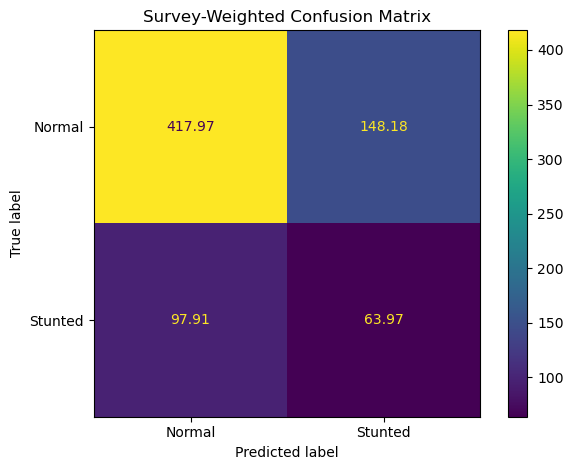

In [28]:
# ==========================================================
# Step-27 : Survey-Weighted Confusion Matrix
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)


print("=" * 70)

print(
    "SURVEY-WEIGHTED CONFUSION MATRIX"
)

print("=" * 70)


weighted_cm = confusion_matrix(

    y_test,

    y_pred,

    labels=[
        0,
        1
    ],

    sample_weight=
        weights_test
)


print(
    "Raw final-test N:",
    len(
        y_test
    )
)


print(

    "Weighted confusion-matrix total "
    "(sum of survey weights):",

    round(
        float(
            weighted_cm.sum()
        ),
        4
    )
)


ConfusionMatrixDisplay(

    confusion_matrix=
        weighted_cm,

    display_labels=[
        "Normal",
        "Stunted"
    ]

).plot(
    values_format=".2f"
)


plt.title(
    "Survey-Weighted Confusion Matrix"
)

plt.tight_layout()

plt.show()

In [29]:
# ==========================================================
# Step-28 : Survey-Weighted Classification Report
#           + Raw Class Counts
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report
)


print("=" * 70)

print(
    "SURVEY-WEIGHTED CLASSIFICATION REPORT"
)

print("=" * 70)


weighted_report = classification_report(

    y_test,

    y_pred,

    labels=[
        0,
        1
    ],

    target_names=[
        "Normal",
        "Stunted"
    ],

    sample_weight=
        weights_test,

    zero_division=
        0,

    output_dict=
        True
)


weighted_report_df = pd.DataFrame(

    weighted_report

).T


display(

    weighted_report_df.round(
        4
    )
)


raw_class_counts = (

    pd.Series(

        np.asarray(
            y_test,
            dtype=int
        )
    )

    .value_counts()

    .reindex(

        [
            0,
            1
        ],

        fill_value=
            0
    )

    .rename(

        index={

            0:
                "Normal",

            1:
                "Stunted"
        }
    )

    .rename(
        "Raw_N"
    )

    .to_frame()
)


print(
    "\nRAW FINAL-TEST OBSERVATION COUNTS"
)


display(
    raw_class_counts
)


print(

    "Raw final-test N:",

    int(

        raw_class_counts[
            "Raw_N"
        ].sum()
    )
)


print(
    "\n✓ In the weighted classification report, "
    "'support' is the sum of survey weights, "
    "not the raw number of observations."
)

print(
    "✓ Raw class-specific observation counts "
    "are reported separately above."
)

SURVEY-WEIGHTED CLASSIFICATION REPORT


,precision,recall,f1-score,support
Normal,0.8102,0.7383,0.7726,566.1492
Stunted,0.3015,0.3952,0.3421,161.8776
accuracy,0.6620,0.6620,0.6620,0.6620
macro avg,0.5559,0.5667,0.5573,728.0268
weighted avg,0.6971,0.6620,0.6768,728.0268



RAW FINAL-TEST OBSERVATION COUNTS


,Raw_N
Normal,553
Stunted,163


Raw final-test N: 716

✓ In the weighted classification report, 'support' is the sum of survey weights, not the raw number of observations.
✓ Raw class-specific observation counts are reported separately above.


In [30]:
# ==========================================================
# Step-29 : Save Final Survey-Aware Spatial ML Workspace
#           + Relative Output Path
#           + SHA-256 Source/Artifact Manifest
#           + Original KR File Included
# ==========================================================

import shutil
import joblib
import pandas as pd

from pathlib import Path


print("=" * 70)
print("SAVING FINAL SPATIAL ML WORKSPACE")
print("=" * 70)


# ==========================================================
# 1. RESET OUTPUT DIRECTORY
# ==========================================================

if SAVE_DIR.exists():

    shutil.rmtree(
        SAVE_DIR
    )


SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ==========================================================
# 2. SURVEY PROVENANCE
# ==========================================================

survey_provenance = {

    "original_dhs_weight_variable":
        ORIGINAL_DHS_WEIGHT_VAR,

    "exact_weight_transformation":
        ORIGINAL_DHS_WEIGHT_FORMULA,

    "anthropometry_weight_verification":
        ORIGINAL_DHS_WEIGHT_SAMPLE_NOTE,

    "original_dhs_psu_variable":
        ORIGINAL_DHS_PSU_VAR,

    "original_dhs_stratum_variable":
        ORIGINAL_DHS_STRATUM_VAR,

    "survey_stratum_levels":
        16,

    "original_haz_variable":
        ORIGINAL_DHS_HAZ_VAR,

    "canonical_analysis_weight":
        "survey_weight",

    "canonical_analysis_psu":
        "psu",

    "canonical_analysis_stratum":
        "survey_stratum",
}


# ==========================================================
# 3. FINAL PREDICTION COMPONENTS
# ==========================================================

final_prediction_components = {

    "final_base_model":
        final_model,

    "probability_calibrator":
        probability_calibrator,

    "final_threshold":
        final_threshold,

    "scaler":
        scaler,

    "onehot_encoder":
        onehot_encoder,

    "model_features":
        model_features,

    "selected_variables":
        selected_vars,

    "nominal_socio_vars":
        nominal_socio_vars,

    "encoded_nominal_columns":
        encoded_nominal_columns,

    "socioeconomic_variables_raw":
        socio_vars_raw,

    "socioeconomic_encoded_features":
        socio_encoded_features,

    "environment_variables":
        env_vars,

    "wx_variables":
        wx_vars,

    "K_NEIGHBORS":
        K_NEIGHBORS,

    "best_weight_strategy":
        best_weight_strategy,
}


# ==========================================================
# 4. OBJECTS TO SAVE
# ==========================================================

objects_to_save = {

    "final_base_model.pkl":
        final_model,

    "best_model_name.pkl":
        best_model_name,

    "fixed_model_templates.pkl":
        models_default,

    "best_weight_strategy.pkl":
        best_weight_strategy,

    "final_threshold.pkl":
        final_threshold,

    "final_prediction_components.pkl":
        final_prediction_components,

    "probability_calibrator.pkl":
        probability_calibrator,

    "calibration_probability_raw.pkl":
        calibration_probability_raw,

    "calibration_probability_oof.pkl":
        calibration_probability_oof,

    "calibration_probability_fullfit.pkl":
        calibration_probability_fullfit,

    "final_scaler.pkl":
        scaler,

    "final_onehot_encoder.pkl":
        onehot_encoder,

    "fixed_category_levels.pkl":
        fixed_category_levels,

    "nominal_socio_vars.pkl":
        nominal_socio_vars,

    "encoded_nominal_columns.pkl":
        encoded_nominal_columns,

    "model_features.pkl":
        model_features,

    "selected_variables.pkl":
        selected_vars,

    "rfecv_results.pkl":
        rfecv_df,

    "rfecv_fold_cache.pkl":
        rfecv_fold_cache,

    "development_fold_cache.pkl":
        development_fold_cache,

    "spatial_block_fold_cache.pkl":
        spatial_block_fold_cache,

    "wx_variables.pkl":
        wx_vars,

    "environment_variables.pkl":
        env_vars,

    "socioeconomic_variables_raw.pkl":
        socio_vars_raw,

    "socioeconomic_encoded_features.pkl":
        socio_encoded_features,

    "predictor_definition.pkl":
        final_predictor_definition_df,

    "X_model_development_raw.pkl":
        X_train_raw,

    "X_calibration_raw.pkl":
        X_calibration_raw,

    "X_final_test_raw.pkl":
        X_test_raw,

    "X_model_development_common_raw.pkl":
        X_train_common_raw,

    "X_calibration_common_raw.pkl":
        X_calibration_common_raw,

    "X_final_test_common_raw.pkl":
        X_test_common_raw,

    "X_model_development.pkl":
        X_train,

    "X_calibration.pkl":
        X_calibration,

    "X_final_test.pkl":
        X_test,

    "y_model_development.pkl":
        y_train,

    "y_calibration.pkl":
        y_calibration,

    "y_final_test.pkl":
        y_test,

    "groups_model_development.pkl":
        groups_train,

    "groups_calibration.pkl":
        groups_calibration,

    "groups_final_test.pkl":
        groups_test,

    "all_groups.pkl":
        groups,

    "weights_model_development.pkl":
        weights_train,

    "weights_calibration.pkl":
        weights_calibration,

    "weights_final_test.pkl":
        weights_test,

    "final_fit_weights.pkl":
        final_fit_weights,

    "all_survey_weights.pkl":
        survey_weights,

    "strata_model_development.pkl":
        strata_train,

    "strata_calibration.pkl":
        strata_calibration,

    "strata_final_test.pkl":
        strata_test,

    "all_strata.pkl":
        strata,

    "spatial_clusters_model_development.pkl":
        spatial_clusters_train,

    "spatial_clusters_calibration.pkl":
        spatial_clusters_calibration,

    "spatial_clusters_final_test.pkl":
        spatial_clusters_test,

    "all_spatial_clusters.pkl":
        spatial_clusters,

    "coords_model_development.pkl":
        coords_train,

    "coords_calibration.pkl":
        coords_calibration,

    "coords_final_test.pkl":
        coords_test,

    "all_coordinates.pkl":
        coordinates,

    "spatial_blocks_model_development.pkl":
        spatial_blocks_train,

    "development_pool_idx.pkl":
        development_pool_idx,

    "model_development_idx.pkl":
        train_idx,

    "calibration_idx.pkl":
        calibration_idx,

    "final_test_idx.pkl":
        test_idx,

    "y_pred.pkl":
        y_pred,

    "y_prob_calibrated.pkl":
        y_prob,

    "y_prob_raw.pkl":
        y_prob_raw,

    "development_cv_results.pkl":
        default_df,

    "spatial_holdout_cv_results.pkl":
        spatial_block_cv_df,

    "ranking_results.pkl":
        ranking_df,

    "weight_sensitivity_results.pkl":
        weight_sensitivity_df,

    "final_test_metrics.pkl":
        final_test_metrics_df,

    "final_dataset.pkl":
        df,

    "target_vector.pkl":
        y,

    "K_NEIGHBORS.pkl":
        K_NEIGHBORS,

    "target_name.pkl":
        target,

    "survey_provenance.pkl":
        survey_provenance,
}


if (
    "spatial_interpretation_note"
    in globals()
):

    objects_to_save[
        "spatial_interpretation_note.pkl"
    ] = spatial_interpretation_note


# ==========================================================
# 5. SAVE ANALYSIS OBJECTS
# ==========================================================

for (
    filename,
    obj
) in objects_to_save.items():

    joblib.dump(
        obj,
        SAVE_DIR
        /
        filename
    )


# ==========================================================
# 6. FROZEN SOURCE FILES FOR SHA-256
# ==========================================================

source_files = [

    BDHS_FILE,

    ORIGINAL_KR_FILE,

    ENV_FILE,
]


# Include ALL shapefile sidecar files.

source_files += sorted(
    GPS_FILE.parent.glob(
        GPS_FILE.stem
        +
        ".*"
    )
)


source_files += sorted(
    DIVISION_BOUNDARY_FILE.parent.glob(
        DIVISION_BOUNDARY_FILE.stem
        +
        ".*"
    )
)


source_files = list(
    dict.fromkeys(
        Path(
            file_path
        ).resolve()

        for file_path
        in source_files

        if Path(
            file_path
        ).exists()
    )
)


# ==========================================================
# 7. SOURCE SHA-256 MANIFEST
# ==========================================================

source_hash_df = pd.DataFrame([

    {

        "Type":
            "Frozen source dataset",

        "Path":
            str(
                file_path.relative_to(
                    PROJECT_ROOT
                )
            ),

        "SHA256":
            sha256_file(
                file_path
            ),

    }

    for file_path
    in source_files
])


source_hash_df.to_csv(

    SAVE_DIR
    /
    "source_sha256_manifest.csv",

    index=False
)


# ==========================================================
# 8. ARTIFACT SHA-256 MANIFEST
# ==========================================================

artifact_files = sorted(
    SAVE_DIR.glob(
        "*.pkl"
    )
)


artifact_hash_df = pd.DataFrame([

    {

        "Type":
            "Key analysis artifact",

        "Path":
            str(
                file_path.relative_to(
                    PROJECT_ROOT
                )
            ),

        "SHA256":
            sha256_file(
                file_path
            ),

    }

    for file_path
    in artifact_files
])


artifact_hash_df.to_csv(

    SAVE_DIR
    /
    "artifact_sha256_manifest.csv",

    index=False
)


# ==========================================================
# 9. SUMMARY
# ==========================================================

print(
    "Saved folder:",
    SAVE_DIR.relative_to(
        PROJECT_ROOT
    )
)


print(
    "Total saved objects:",
    len(
        objects_to_save
    )
)


print(
    "\nSOURCE SHA-256 MANIFEST"
)

display(
    source_hash_df
)


print(
    "\nARTIFACT SHA-256 MANIFEST"
)

display(
    artifact_hash_df
)


print(
    "\n✓ Original analytical SAV included in source manifest."
)

print(
    "✓ Original BDKR81FL.SAV included in source manifest."
)

print(
    "✓ Environmental source included in source manifest."
)

print(
    "✓ GPS shapefile and associated files included."
)

print(
    "✓ Division boundary shapefile and associated files included."
)

print(
    "✓ Frozen source datasets and key analysis "
    "artifacts have recorded SHA-256 hashes."
)

SAVING FINAL SPATIAL ML WORKSPACE
Saved folder: SpatialML_Saved
Total saved objects: 78

SOURCE SHA-256 MANIFEST


,Type,Path,SHA256
0,Frozen source dataset,Stunting_Final_Recoded_Final.SAV,a3b21cbaff1a69d4c7bf9f8631a08399cbce7e049f2f5f...
1,Frozen source dataset,BDKR81FL.SAV,449e96efeeccd0eae220e0e969c32ed4fd820ea9c63292...
2,Frozen source dataset,GPS DATA\bdhs_env_2022.csv,48d8a2fccfd1fa74b78d0e85697f6897a6060b2d4b4566...
3,Frozen source dataset,GPS DATA\Division\BDGE81FL.cpg,3ad3031f5503a4404af825262ee8232cc04d4ea6683d42...
4,Frozen source dataset,GPS DATA\Division\BDGE81FL.dbf,d1fcf10a379636bd1e2de65518050dfbb77a908b93b69e...
5,Frozen source dataset,GPS DATA\Division\BDGE81FL.prj,a02a27b1d1982c8516d83398e85a3c8b1aef1713c13ef4...
6,Frozen source dataset,GPS DATA\Division\BDGE81FL.sbn,0be54455cdb302080c0dc3adfb345bb4bc87d95374ecf2...
7,Frozen source dataset,GPS DATA\Division\BDGE81FL.sbx,7e4b3f95a5169cadc9dd2193b7ab6276d704afeed26aec...
8,Frozen source dataset,GPS DATA\Division\BDGE81FL.shp,926b157aa75c83ce39274f0253a785239f6f79a7f38209...
9,Frozen source dataset,GPS DATA\Division\BDGE81FL.shp.xml,3162243dde224fffa56f8c5db2d67424795e8493a8221b...



ARTIFACT SHA-256 MANIFEST


,Type,Path,SHA256
0,Key analysis artifact,SpatialML_Saved\all_coordinates.pkl,719bfcea1dd3a26e34e6ef2b409d9bf42523390411e9d3...
1,Key analysis artifact,SpatialML_Saved\all_groups.pkl,dbd818bcd24cab426509eb4954ae83126b62c5e9a1b711...
2,Key analysis artifact,SpatialML_Saved\all_spatial_clusters.pkl,dbd818bcd24cab426509eb4954ae83126b62c5e9a1b711...
3,Key analysis artifact,SpatialML_Saved\all_strata.pkl,b91ddfc293cd237447b89838a8398bbf258e0a9ccd9eff...
4,Key analysis artifact,SpatialML_Saved\all_survey_weights.pkl,2240c7cf57625bc56af794c5480b4b6fd7be7400c682a4...
...,...,...,...
73,Key analysis artifact,SpatialML_Saved\y_final_test.pkl,570bc9a27119487fbd1d8bfbe68285af76858d9767954a...
74,Key analysis artifact,SpatialML_Saved\y_model_development.pkl,da378dc4d4d5094a408e42d2ed9e72325542570c375e59...
75,Key analysis artifact,SpatialML_Saved\y_pred.pkl,927ce40b888f608b6eb26633b416416043d118f039361b...
76,Key analysis artifact,SpatialML_Saved\y_prob_calibrated.pkl,95be6c6dfec4d42140f3bd1c70c195b70916903a59740e...



✓ Original analytical SAV included in source manifest.
✓ Original BDKR81FL.SAV included in source manifest.
✓ Environmental source included in source manifest.
✓ GPS shapefile and associated files included.
✓ Division boundary shapefile and associated files included.
✓ Frozen source datasets and key analysis artifacts have recorded SHA-256 hashes.


In [31]:
# ==========================================================
# Step-30 : Record Computational Environment
#           and Package Versions
# ==========================================================

import platform
import importlib.metadata as importlib_metadata

import pandas as pd


print("=" * 70)

print(
    "RECORD COMPUTATIONAL ENVIRONMENT "
    "AND PACKAGE VERSIONS"
)

print("=" * 70)


packages = [

    "numpy",
    "pandas",
    "geopandas",
    "pyreadstat",
    "matplotlib",
    "scikit-learn",
    "xgboost",
    "lightgbm",
    "catboost",
    "libpysal",
    "statsmodels",
    "joblib",
    "geoshapley",
]


environment_rows = [

    {

        "Component":
            "Python",

        "Version":
            platform.python_version(),
    },

    {

        "Component":
            "Platform",

        "Version":
            platform.platform(),
    },
]


for package in packages:

    try:

        version = importlib_metadata.version(
            package
        )


    except importlib_metadata.PackageNotFoundError:

        version = (
            "Not installed"
        )


    environment_rows.append({

        "Component":
            package,

        "Version":
            version,
    })


environment_versions_df = pd.DataFrame(

    environment_rows
)


environment_versions_df.to_csv(

    SAVE_DIR
    /
    "computational_environment_versions.csv",

    index=
        False
)


display(
    environment_versions_df
)


print(

    "\nSaved:",

    (
        SAVE_DIR
        /
        "computational_environment_versions.csv"
    ).relative_to(
        PROJECT_ROOT
    )
)

RECORD COMPUTATIONAL ENVIRONMENT AND PACKAGE VERSIONS


,Component,Version
0,Python,3.13.9
1,Platform,Windows-10-10.0.19045-SP0
2,numpy,2.3.5
3,pandas,2.3.3
4,geopandas,1.1.3
5,pyreadstat,1.3.4
6,matplotlib,3.10.6
7,scikit-learn,1.7.2
8,xgboost,3.2.0
9,lightgbm,4.6.0



Saved: SpatialML_Saved\computational_environment_versions.csv


In [32]:
# ==========================================================
# Step-31 : Restore Final Survey-Aware Spatial ML Workspace
# ==========================================================

import joblib
import numpy as np

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)


print("=" * 70)

print(
    "RESTORING FINAL SPATIAL ML WORKSPACE"
)

print("=" * 70)


def load_saved(
    filename
):

    path = (

        SAVE_DIR
        /
        filename
    )


    if not path.exists():

        raise FileNotFoundError(

            f"Missing saved object: {path}"
        )


    return joblib.load(
        path
    )


# ==========================================================
# Final model
# ==========================================================

final_model = load_saved(
    "final_base_model.pkl"
)


best_model_name = load_saved(
    "best_model_name.pkl"
)


models_default = load_saved(
    "fixed_model_templates.pkl"
)


best_model_template = models_default[
    best_model_name
]


best_weight_strategy = load_saved(
    "best_weight_strategy.pkl"
)


final_threshold = load_saved(
    "final_threshold.pkl"
)


final_prediction_components = load_saved(
    "final_prediction_components.pkl"
)


probability_calibrator = load_saved(
    "probability_calibrator.pkl"
)


calibration_probability_raw = load_saved(
    "calibration_probability_raw.pkl"
)


calibration_probability_oof = load_saved(
    "calibration_probability_oof.pkl"
)


calibration_probability_fullfit = load_saved(
    "calibration_probability_fullfit.pkl"
)


# ==========================================================
# Preprocessing/features
# ==========================================================

scaler = load_saved(
    "final_scaler.pkl"
)


onehot_encoder = load_saved(
    "final_onehot_encoder.pkl"
)


fixed_category_levels = load_saved(
    "fixed_category_levels.pkl"
)


nominal_socio_vars = load_saved(
    "nominal_socio_vars.pkl"
)


encoded_nominal_columns = load_saved(
    "encoded_nominal_columns.pkl"
)


model_features = load_saved(
    "model_features.pkl"
)


selected_vars = load_saved(
    "selected_variables.pkl"
)


rfecv_df = load_saved(
    "rfecv_results.pkl"
)


rfecv_fold_cache = load_saved(
    "rfecv_fold_cache.pkl"
)


development_fold_cache = load_saved(
    "development_fold_cache.pkl"
)


spatial_block_fold_cache = load_saved(
    "spatial_block_fold_cache.pkl"
)


wx_vars = load_saved(
    "wx_variables.pkl"
)


env_vars = load_saved(
    "environment_variables.pkl"
)


socio_vars_raw = load_saved(
    "socioeconomic_variables_raw.pkl"
)


socio_encoded_features = load_saved(
    "socioeconomic_encoded_features.pkl"
)


final_predictor_definition_df = load_saved(
    "predictor_definition.pkl"
)


# ==========================================================
# Matrices
# ==========================================================

X_train_raw = load_saved(
    "X_model_development_raw.pkl"
)


X_calibration_raw = load_saved(
    "X_calibration_raw.pkl"
)


X_test_raw = load_saved(
    "X_final_test_raw.pkl"
)


X_train_common_raw = load_saved(
    "X_model_development_common_raw.pkl"
)


X_calibration_common_raw = load_saved(
    "X_calibration_common_raw.pkl"
)


X_test_common_raw = load_saved(
    "X_final_test_common_raw.pkl"
)


X_train = load_saved(
    "X_model_development.pkl"
)


X_calibration = load_saved(
    "X_calibration.pkl"
)


X_test = load_saved(
    "X_final_test.pkl"
)


y_train = load_saved(
    "y_model_development.pkl"
)


y_calibration = load_saved(
    "y_calibration.pkl"
)


y_test = load_saved(
    "y_final_test.pkl"
)


# ==========================================================
# Survey design
# ==========================================================

groups_train = load_saved(
    "groups_model_development.pkl"
)


groups_calibration = load_saved(
    "groups_calibration.pkl"
)


groups_test = load_saved(
    "groups_final_test.pkl"
)


groups = load_saved(
    "all_groups.pkl"
)


weights_train = load_saved(
    "weights_model_development.pkl"
)


weights_calibration = load_saved(
    "weights_calibration.pkl"
)


weights_test = load_saved(
    "weights_final_test.pkl"
)


final_fit_weights = load_saved(
    "final_fit_weights.pkl"
)


combined_train_weights = np.asarray(

    final_fit_weights,

    dtype=float

).copy()


survey_weights = load_saved(
    "all_survey_weights.pkl"
)


strata_train = load_saved(
    "strata_model_development.pkl"
)


strata_calibration = load_saved(
    "strata_calibration.pkl"
)


strata_test = load_saved(
    "strata_final_test.pkl"
)


strata = load_saved(
    "all_strata.pkl"
)


# ==========================================================
# Spatial objects
# ==========================================================

spatial_clusters_train = load_saved(
    "spatial_clusters_model_development.pkl"
)


spatial_clusters_calibration = load_saved(
    "spatial_clusters_calibration.pkl"
)


spatial_clusters_test = load_saved(
    "spatial_clusters_final_test.pkl"
)


spatial_clusters = load_saved(
    "all_spatial_clusters.pkl"
)


coords_train = load_saved(
    "coords_model_development.pkl"
)


coords_calibration = load_saved(
    "coords_calibration.pkl"
)


coords_test = load_saved(
    "coords_final_test.pkl"
)


coordinates = load_saved(
    "all_coordinates.pkl"
)


spatial_blocks_train = load_saved(
    "spatial_blocks_model_development.pkl"
)


# ==========================================================
# Indices
# ==========================================================

development_pool_idx = load_saved(
    "development_pool_idx.pkl"
)


train_idx = load_saved(
    "model_development_idx.pkl"
)


calibration_idx = load_saved(
    "calibration_idx.pkl"
)


test_idx = load_saved(
    "final_test_idx.pkl"
)


# ==========================================================
# Predictions/results
# ==========================================================

y_pred = load_saved(
    "y_pred.pkl"
)


y_prob = load_saved(
    "y_prob_calibrated.pkl"
)


y_prob_raw = load_saved(
    "y_prob_raw.pkl"
)


default_df = load_saved(
    "development_cv_results.pkl"
)


spatial_block_cv_df = load_saved(
    "spatial_holdout_cv_results.pkl"
)


ranking_df = load_saved(
    "ranking_results.pkl"
)


weight_sensitivity_df = load_saved(
    "weight_sensitivity_results.pkl"
)


final_test_metrics_df = load_saved(
    "final_test_metrics.pkl"
)


# ==========================================================
# Dataset/settings
# ==========================================================

df = load_saved(
    "final_dataset.pkl"
)


y = load_saved(
    "target_vector.pkl"
)


K_NEIGHBORS = load_saved(
    "K_NEIGHBORS.pkl"
)


target = load_saved(
    "target_name.pkl"
)


survey_provenance = load_saved(
    "survey_provenance.pkl"
)


optional_note = (

    SAVE_DIR
    /
    "spatial_interpretation_note.pkl"
)


if optional_note.exists():

    spatial_interpretation_note = joblib.load(
        optional_note
    )


# ==========================================================
# Calibration helper
# ==========================================================

EPS = 1e-6


def probability_to_logit(
    probability
):

    probability = np.clip(

        np.asarray(
            probability,
            dtype=float
        ),

        EPS,

        1
        -
        EPS
    )


    return np.log(

        probability

        /

        (
            1.0
            -
            probability
        )
    )


def apply_probability_calibration(
    raw_probability
):

    return (

        probability_calibrator

        .predict_proba(

            probability_to_logit(

                raw_probability

            ).reshape(
                -1,
                1
            )

        )[
            :,
            1
        ]
    )


# ==========================================================
# Restore final statistics
# ==========================================================

final_test_auc = roc_auc_score(

    y_test,

    y_prob,

    sample_weight=
        weights_test
)


final_test_ap = average_precision_score(

    y_test,

    y_prob,

    sample_weight=
        weights_test
)


final_test_brier = brier_score_loss(

    y_test,

    y_prob,

    sample_weight=
        weights_test
)


final_auc_ci_lower = float(

    final_test_metrics_df.loc[
        0,
        "AUC_CI_Lower"
    ]
)


final_auc_ci_upper = float(

    final_test_metrics_df.loc[
        0,
        "AUC_CI_Upper"
    ]
)


if (

    len(
        X_train
    )
    !=
    len(
        y_train
    )

    or

    len(
        X_calibration
    )
    !=
    len(
        y_calibration
    )

    or

    len(
        X_test
    )
    !=
    len(
        y_test
    )

):

    raise RuntimeError(

        "Restored X/y lengths do not match."
    )


if list(
    X_train.columns
) != list(
    model_features
):

    raise RuntimeError(

        "Restored model feature names do not "
        "match the development matrix."
    )


print(
    "Model:",
    best_model_name
)

print(
    "Model-development N:",
    len(
        y_train
    )
)

print(
    "Calibration N:",
    len(
        y_calibration
    )
)

print(
    "Final-test N:",
    len(
        y_test
    )
)

print(
    "Features:",
    len(
        model_features
    )
)

print(
    "Locked threshold:",
    round(
        final_threshold,
        4
    )
)

print(
    "Final-test ROC-AUC:",
    round(
        final_test_auc,
        4
    )
)

print(

    "Conditional PSU-bootstrap 95% CI:",

    f"{final_auc_ci_lower:.4f}"
    "-"
    f"{final_auc_ci_upper:.4f}"
)


print(
    "\n✓ Workspace restored from the "
    "project-root output directory."
)

RESTORING FINAL SPATIAL ML WORKSPACE
Model: CatBoost
Model-development N: 2340
Calibration N: 564
Final-test N: 716
Features: 23
Locked threshold: 0.2472
Final-test ROC-AUC: 0.6481
Conditional PSU-bootstrap 95% CI: 0.5999-0.6902

✓ Workspace restored from the project-root output directory.


In [33]:
# ==========================================================
# Step-32 : Reduced Explanatory Model for GeoShapley
#           + Grouped Out-of-Fold Permutation Importance
#           + Paired 16-Stratum PSU Bootstrap
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.base import clone

from sklearn.inspection import (
    permutation_importance
)

from sklearn.pipeline import (
    Pipeline
)

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.metrics import (
    roc_auc_score
)


print("=" * 70)
print(
    "GROUPED OOF PERMUTATION IMPORTANCE "
    "FOR GEOSHAPLEY FEATURE SELECTION"
)
print("=" * 70)


# ==========================================================
# 1. SURVEY-STRATUM AUDIT
# ==========================================================

EXPECTED_SURVEY_STRATA = 16

observed_survey_strata = int(
    df[
        "survey_stratum"
    ].nunique(
        dropna=True
    )
)

if observed_survey_strata != EXPECTED_SURVEY_STRATA:
    raise RuntimeError(
        f"Expected {EXPECTED_SURVEY_STRATA} survey strata; "
        f"found {observed_survey_strata}."
    )


# ==========================================================
# 2. CONFIGURATION
# ==========================================================

N_TOP_FEATURES = 10


coord_cols = [

    feature

    for feature
    in [
        "lat",
        "lon"
    ]

    if feature
    in model_features
]


noncoord_locked_features = [

    feature

    for feature
    in model_features

    if feature
    not in coord_cols
]


# ==========================================================
# 3. GROUPED OOF PERMUTATION IMPORTANCE
# ==========================================================

oof_permutation_rows = []


for fold in development_fold_cache:

    missing_features = [

        feature

        for feature
        in model_features

        if (
            feature
            not in fold[
                "X_train_scaled"
            ].columns
        )
        or
        (
            feature
            not in fold[
                "X_valid_scaled"
            ].columns
        )
    ]


    if missing_features:

        raise RuntimeError(

            "Locked final features are absent "
            "from a development fold: "

            f"{missing_features}"
        )


    X_fold_train = (
        fold[
            "X_train_scaled"
        ][
            model_features
        ]
    )


    X_fold_valid = (
        fold[
            "X_valid_scaled"
        ][
            model_features
        ]
    )


    fold_model = clone(
        best_model_template
    )


    fold_model.fit(

        X_fold_train,

        fold[
            "y_train"
        ],

        sample_weight=
            fold[
                "fit_weight_train"
            ]
    )


    valid_weights = np.asarray(

        fold[
            "survey_weight_valid"
        ],

        dtype=float
    )


    def fold_weighted_auc_scorer(
        estimator,
        X_valid_perm,
        y_valid_perm
    ):

        probability = (
            estimator
            .predict_proba(
                X_valid_perm
            )[
                :,
                1
            ]
        )


        return roc_auc_score(

            np.asarray(
                y_valid_perm,
                dtype=int
            ),

            probability,

            sample_weight=
                valid_weights
        )


    permutation_result = permutation_importance(

        fold_model,

        X_fold_valid,

        fold[
            "y_valid"
        ],

        scoring=
            fold_weighted_auc_scorer,

        n_repeats=
            20,

        random_state=
            3200
            +
            int(
                fold[
                    "fold_no"
                ]
            ),

        n_jobs=
            1
    )


    for (
        feature,
        mean_imp,
        sd_imp

    ) in zip(

        model_features,

        permutation_result.importances_mean,

        permutation_result.importances_std
    ):

        oof_permutation_rows.append({

            "Fold":
                int(
                    fold[
                        "fold_no"
                    ]
                ),

            "Feature":
                feature,

            "OOF_Permutation_Importance_Mean":
                float(
                    mean_imp
                ),

            "OOF_Permutation_Importance_SD":
                float(
                    sd_imp
                ),
        })


# ==========================================================
# 4. AGGREGATE ACROSS FOLDS
# ==========================================================

oof_permutation_fold_df = pd.DataFrame(
    oof_permutation_rows
)


permutation_importance_df = (

    oof_permutation_fold_df

    .groupby(
        "Feature",
        as_index=False
    )

    .agg(

        OOF_Permutation_Importance=(
            "OOF_Permutation_Importance_Mean",
            "mean"
        ),

        Across_Fold_SD=(
            "OOF_Permutation_Importance_Mean",
            "std"
        ),

        N_Folds=(
            "Fold",
            "nunique"
        ),
    )

    .sort_values(
        "OOF_Permutation_Importance",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nGrouped OOF permutation importance "
    "aggregated across development folds"
)


display(
    permutation_importance_df.round(
        6
    )
)


# ==========================================================
# 5. SELECT EXPLANATORY FEATURES
# ==========================================================

top_features = (

    permutation_importance_df[

        permutation_importance_df[
            "Feature"
        ].isin(
            noncoord_locked_features
        )
    ]

    .head(
        N_TOP_FEATURES
    )[

        "Feature"
    ]

    .tolist()
)


if len(
    top_features
) == 0:

    raise RuntimeError(
        "No non-coordinate feature available "
        "for GeoShapley."
    )


geo_feature_list = (
    top_features
    +
    coord_cols
)


print(
    "\nGeoShapley feature list:"
)


for (
    index,
    feature
) in enumerate(
    geo_feature_list,
    start=1
):

    print(
        f"{index:02d}. {feature}"
    )


# ==========================================================
# 6. REDUCED EXPLANATORY MODEL
# ==========================================================

X_train_geo = (
    X_train_raw[
        geo_feature_list
    ].copy()
)


X_test_geo = (
    X_test_raw[
        geo_feature_list
    ].copy()
)


reduced_geo_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        clone(
            best_model_template
        )
    ),
])


reduced_geo_pipeline.fit(

    X_train_geo,

    y_train,

    scaler__sample_weight=
        weights_train,

    model__sample_weight=
        combined_train_weights
)


geo_test_prob = (
    reduced_geo_pipeline
    .predict_proba(
        X_test_geo
    )[
        :,
        1
    ]
)


geo_test_auc = roc_auc_score(

    y_test,

    geo_test_prob,

    sample_weight=
        weights_test
)


auc_gap = float(
    geo_test_auc
    -
    final_test_auc
)


# ==========================================================
# 7. PAIRED STRATIFIED PSU BOOTSTRAP
#    AUC DIFFERENCE: REDUCED - FULL
# ==========================================================

def paired_psu_auc_difference_ci(
    y_true,
    full_prob,
    reduced_prob,
    weight,
    psu,
    strata,
    n_bootstrap=1000,
    random_state=42
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    full_prob = np.asarray(
        full_prob,
        dtype=float
    )

    reduced_prob = np.asarray(
        reduced_prob,
        dtype=float
    )

    weight = np.asarray(
        weight,
        dtype=float
    )

    psu = np.asarray(
        psu
    )

    strata = np.asarray(
        strata
    )


    rng = np.random.default_rng(
        random_state
    )


    values = []


    for _ in range(
        n_bootstrap
    ):

        sampled_indices = []


        for stratum_value in np.unique(
            strata
        ):

            stratum_mask = (
                strata
                ==
                stratum_value
            )


            psus = np.unique(
                psu[
                    stratum_mask
                ]
            )


            sampled_psus = rng.choice(
                psus,
                size=len(psus),
                replace=True
            )


            for sampled_psu in sampled_psus:

                sampled_indices.extend(

                    np.where(

                        stratum_mask

                        &

                        (
                            psu
                            ==
                            sampled_psu
                        )

                    )[0].tolist()
                )


        sampled_indices = np.asarray(
            sampled_indices,
            dtype=int
        )


        if (
            len(
                sampled_indices
            ) == 0
            or
            np.unique(
                y_true[
                    sampled_indices
                ]
            ).size < 2
        ):
            continue


        full_auc_boot = roc_auc_score(

            y_true[
                sampled_indices
            ],

            full_prob[
                sampled_indices
            ],

            sample_weight=
                weight[
                    sampled_indices
                ]
        )


        reduced_auc_boot = roc_auc_score(

            y_true[
                sampled_indices
            ],

            reduced_prob[
                sampled_indices
            ],

            sample_weight=
                weight[
                    sampled_indices
                ]
        )


        values.append(
            float(
                reduced_auc_boot
                -
                full_auc_boot
            )
        )


    if not values:

        return (
            np.nan,
            np.nan
        )


    return (
        float(
            np.percentile(
                values,
                2.5
            )
        ),
        float(
            np.percentile(
                values,
                97.5
            )
        )
    )


# ==========================================================
# 8. AUC-DIFFERENCE CI
# ==========================================================

(
    auc_gap_ci_lower,
    auc_gap_ci_upper

) = paired_psu_auc_difference_ci(

    y_true=
        y_test,

    full_prob=
        y_prob,

    reduced_prob=
        geo_test_prob,

    weight=
        weights_test,

    psu=
        groups_test,

    strata=
        strata_test,

    n_bootstrap=
        1000,

    random_state=
        42
)


# ==========================================================
# 9. PRINT REDUCED-MODEL COMPARISON
# ==========================================================

print(
    "\nFull final-model ROC-AUC:",
    round(
        final_test_auc,
        4
    )
)


print(
    "Reduced GeoShapley-model ROC-AUC:",
    round(
        geo_test_auc,
        4
    )
)


print(
    "ROC-AUC difference (Reduced - Full):",
    round(
        auc_gap,
        4
    )
)


print(
    "Conditional paired stratified "
    "PSU-bootstrap 95% CI for difference:",

    f"{auc_gap_ci_lower:.4f}"
    "-"
    f"{auc_gap_ci_upper:.4f}"
)


# ==========================================================
# 10. DHS DISPLACED COORDINATES
# ==========================================================

X_train_dhs_coords = pd.DataFrame({

    "dhs_lat":
        coords_train[
            :,
            1
        ],

    "dhs_lon":
        coords_train[
            :,
            0
        ],
})


X_test_dhs_coords = pd.DataFrame({

    "dhs_lat":
        coords_test[
            :,
            1
        ],

    "dhs_lon":
        coords_test[
            :,
            0
        ],
})


# ==========================================================
# 11. WEIGHTED GEOSHAPLEY BACKGROUND
# ==========================================================

GEOSHAPLEY_BACKGROUND_SIZE = min(

    30,

    len(
        X_train_geo
    )
)


background = (

    X_train_geo

    .sample(

        n=
            GEOSHAPLEY_BACKGROUND_SIZE,

        weights=
            np.asarray(
                weights_train,
                dtype=float
            ),

        random_state=
            42
    )

    .to_numpy()
)


print(
    "Background Shape:",
    background.shape
)


# ==========================================================
# 12. FINAL AUDIT
# ==========================================================

print(
    f"\n✓ Survey bootstrap uses the retained "
    f"{EXPECTED_SURVEY_STRATA}-level "
    f"survey_stratum variable."
)


print(
    "✓ GeoShapley candidate features are selected "
    "from grouped OOF permutation importance "
    "aggregated across folds."
)


print(
    "✓ Permutation importance is no longer "
    "calculated in-sample on the same observations "
    "used to fit one final model."
)


print(
    "✓ This explanation analysis is conditional "
    "on the locked Step-20 feature set "
    "and model family."
)


print(
    "✓ It does not demonstrate upstream "
    "feature-selection or model-refit stability."
)

GROUPED OOF PERMUTATION IMPORTANCE FOR GEOSHAPLEY FEATURE SELECTION

Grouped OOF permutation importance aggregated across development folds


,Feature,OOF_Permutation_Importance,Across_Fold_SD,N_Folds
0,Maternal_Height_3.0,0.088063,0.012017,5
1,Child_age_months,0.040086,0.013821,5
2,flood_occurrence_pct,0.006854,0.006261,5
3,BMI_2.0,0.006285,0.008525,5
4,Father_education_1.0,0.006256,0.005301,5
5,slope_degrees,0.003354,0.008873,5
6,Fever_0.0,0.002420,0.003917,5
7,wx_soil_moisture,0.001156,0.008190,5
8,ndvi,0.001123,0.005078,5
9,Child_sex_2.0,0.001062,0.005355,5



GeoShapley feature list:
01. Maternal_Height_3.0
02. Child_age_months
03. flood_occurrence_pct
04. BMI_2.0
05. Father_education_1.0
06. slope_degrees
07. Fever_0.0
08. wx_soil_moisture
09. ndvi
10. Child_sex_2.0
11. lat
12. lon

Full final-model ROC-AUC: 0.6481
Reduced GeoShapley-model ROC-AUC: 0.6394
ROC-AUC difference (Reduced - Full): -0.0087
Conditional paired stratified PSU-bootstrap 95% CI for difference: -0.0395-0.0198
Background Shape: (30, 12)

✓ Survey bootstrap uses the retained 16-level survey_stratum variable.
✓ GeoShapley candidate features are selected from grouped OOF permutation importance aggregated across folds.
✓ Permutation importance is no longer calculated in-sample on the same observations used to fit one final model.
✓ This explanation analysis is conditional on the locked Step-20 feature set and model family.
✓ It does not demonstrate upstream feature-selection or model-refit stability.


In [34]:
# ==========================================================
# Step-33 : Reduced-Model GeoShapley Explainer
# ==========================================================

from geoshapley import GeoShapleyExplainer

print("=" * 70)
print("BUILDING REDUCED-MODEL GEOSHAPLEY EXPLAINER")
print("=" * 70)

def predict_probability(data):

    if isinstance(
        data,
        np.ndarray
    ):

        data = pd.DataFrame(
            data,
            columns=geo_feature_list
        )

    return (

        reduced_geo_pipeline

        .predict_proba(
            data[geo_feature_list]
        )[:, 1]

    )


geo_explainer = GeoShapleyExplainer(

    predict_f=predict_probability,

    background=background,

    g=2,

    exact=False
)

print(
    "GeoShapley Explainer created successfully."
)

BUILDING REDUCED-MODEL GEOSHAPLEY EXPLAINER
GeoShapley Explainer created successfully.


In [35]:
# ==========================================================
# Step-34 : Compute GeoShapley Values
#           + CONDITIONAL Background-Sample Sensitivity
# ==========================================================

import numpy as np
import pandas as pd

from geoshapley import (
    GeoShapleyExplainer
)


print("=" * 70)

print(
    "COMPUTING GEOSHAPLEY VALUES"
)

print("=" * 70)


X_geo_sample = (

    X_test_geo

    .reset_index(
        drop=True
    )

    .copy()
)


dhs_coords_sample = (

    X_test_dhs_coords

    .reset_index(
        drop=True
    )

    .copy()
)


cluster_ids_sample = pd.Series(

    spatial_clusters_test

).reset_index(
    drop=True
)


print(
    "Sample Size            :",
    len(
        X_geo_sample
    )
)

print(
    "Feature Count          :",
    X_geo_sample.shape[
        1
    ]
)

print(
    "Unique Spatial Clusters:",
    cluster_ids_sample.nunique()
)


geo_results = geo_explainer.explain(

    X_geo_sample,

    n_jobs=
        1
)


print(
    "\nGeoShapley completed successfully."
)


# ==========================================================
# Helper
# ==========================================================

def get_primary_matrix(

    results_object,
    expected_rows
):

    primary_array = np.asarray(

        results_object.primary,

        dtype=float
    )


    if primary_array.ndim == 1:

        primary_array = primary_array.reshape(

            expected_rows,

            -1
        )


    if (

        primary_array.ndim
        ==
        2

        and

        primary_array.shape[
            0
        ]
        !=
        expected_rows

        and

        primary_array.shape[
            1
        ]
        ==
        expected_rows

    ):

        primary_array = (
            primary_array.T
        )


    if primary_array.shape[
        0
    ] != expected_rows:

        raise RuntimeError(

            "Unable to align GeoShapley primary "
            "contributions with explained observations."
        )


    return primary_array


primary_matrix = get_primary_matrix(

    geo_results,

    len(
        X_geo_sample
    )
)


primary_mean_abs = np.mean(

    np.abs(
        primary_matrix
    ),

    axis=
        0
)


# ==========================================================
# CONDITIONAL background-sample sensitivity
# ==========================================================

background_sensitivity_rows = []


for alternative_seed in [

    43,
    44
]:

    alternative_background = (

        X_train_geo

        .sample(

            n=
                GEOSHAPLEY_BACKGROUND_SIZE,

            weights=
                np.asarray(
                    weights_train,
                    dtype=float
                ),

            random_state=
                alternative_seed
        )

        .to_numpy()
    )


    alternative_explainer = GeoShapleyExplainer(

        predict_f=
            predict_probability,

        background=
            alternative_background,

        g=
            2,

        exact=
            False
    )


    alternative_results = (

        alternative_explainer

        .explain(

            X_geo_sample,

            n_jobs=
                1
        )
    )


    alternative_primary_matrix = get_primary_matrix(

        alternative_results,

        len(
            X_geo_sample
        )
    )


    if (

        alternative_primary_matrix.shape[
            1
        ]

        !=

        primary_matrix.shape[
            1
        ]

    ):

        raise RuntimeError(

            "GeoShapley contribution dimensions "
            "differ across backgrounds."
        )


    alternative_mean_abs = np.mean(

        np.abs(
            alternative_primary_matrix
        ),

        axis=
            0
    )


    rank_correlation = (

        pd.Series(
            primary_mean_abs
        )

        .corr(

            pd.Series(
                alternative_mean_abs
            ),

            method=
                "spearman"
        )
    )


    background_sensitivity_rows.append({

        "Primary_Background_Seed":
            42,

        "Alternative_Background_Seed":
            alternative_seed,

        "Background_Size":
            GEOSHAPLEY_BACKGROUND_SIZE,

        "Spearman_Rank_Correlation":
            float(
                rank_correlation
            ),
    })


geoshapley_background_sensitivity_df = pd.DataFrame(

    background_sensitivity_rows
)


print(
    "\nCONDITIONAL GEOSHAPLEY "
    "BACKGROUND-SAMPLE SENSITIVITY"
)


display(

    geoshapley_background_sensitivity_df

    .round(
        4
    )
)


print(
    "\n✓ Primary results remain based on the "
    "weighted development background with "
    "random_state=42."
)

print(
    "✓ Alternative weighted backgrounds use "
    "the same size and assess background-sample "
    "sensitivity only."
)

print(
    "✓ This stability is conditional on the "
    "locked selected feature set and fitted "
    "reduced model."
)

print(
    "✓ It does not demonstrate upstream "
    "feature-selection stability or stability "
    "across model refits."
)

COMPUTING GEOSHAPLEY VALUES
Sample Size            : 716
Feature Count          : 12
Unique Spatial Clusters: 134


  0%|          | 0/716 [00:00<?, ?it/s]


GeoShapley completed successfully.


  0%|          | 0/716 [00:00<?, ?it/s]

  0%|          | 0/716 [00:00<?, ?it/s]


CONDITIONAL GEOSHAPLEY BACKGROUND-SAMPLE SENSITIVITY


,Primary_Background_Seed,Alternative_Background_Seed,Background_Size,Spearman_Rank_Correlation
0,42,43,30,0.6606
1,42,44,30,0.9152



✓ Primary results remain based on the weighted development background with random_state=42.
✓ Alternative weighted backgrounds use the same size and assess background-sample sensitivity only.
✓ This stability is conditional on the locked selected feature set and fitted reduced model.
✓ It does not demonstrate upstream feature-selection stability or stability across model refits.


In [36]:
# ==========================================================
# Step-35 : Inspect GeoShapley Results
# ==========================================================

print("=" * 70)
print("GEOSHAPLEY RESULTS")
print("=" * 70)

print(type(geo_results))

print("\nAvailable Attributes:\n")

print(dir(geo_results))

GEOSHAPLEY RESULTS
<class 'geoshapley.geoshapley.GeoShapleyResults'>

Available Attributes:

['M', 'X_geo', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', 'background', 'base_value', 'check_additivity', 'contribution_bar_plot', 'explainer', 'g', 'geo', 'geo_intera', 'geoshap_to_shap', 'get_svc', 'partial_dependence_plots', 'predict_f', 'primary', 'summary_plot', 'summary_statistics']


GEOSHAPLEY SUMMARY PLOT


C:\Users\Tc\AppData\Roaming\Python\Python313\site-packages\geoshapley\geoshapley.py:435: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(total, names, show=False, **kwargs)


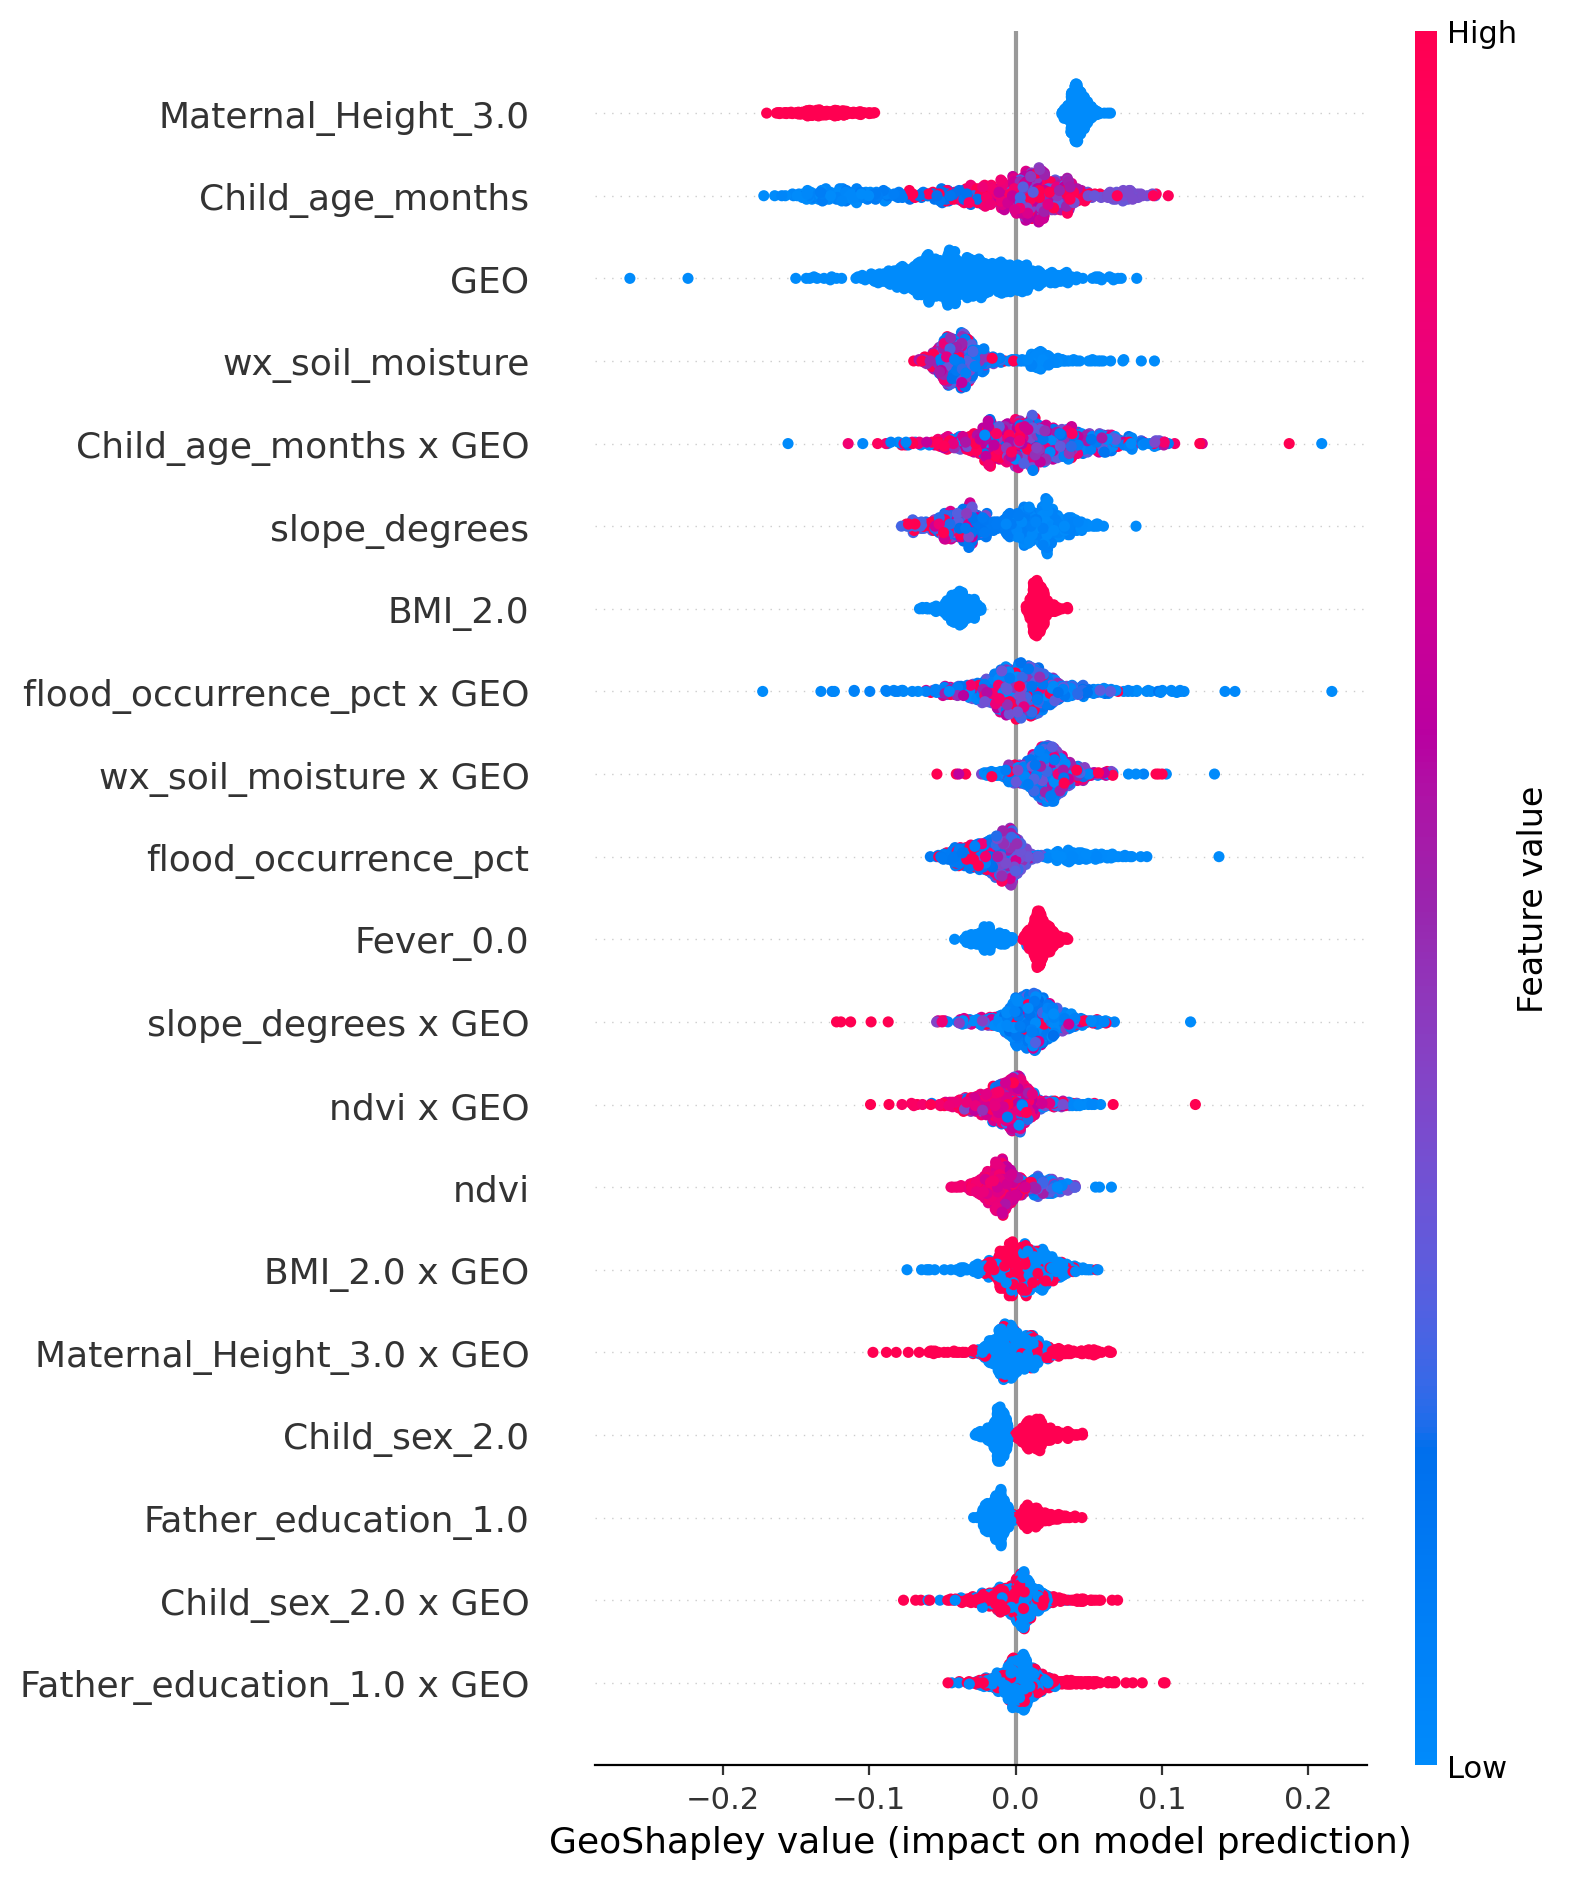

In [37]:
# ==========================================================
# Step-36 : GeoShapley Summary Plot
# ==========================================================

print("=" * 70)
print("GEOSHAPLEY SUMMARY PLOT")
print("=" * 70)

geo_results.summary_plot()

GEOSHAPLEY CONTRIBUTION BAR PLOT


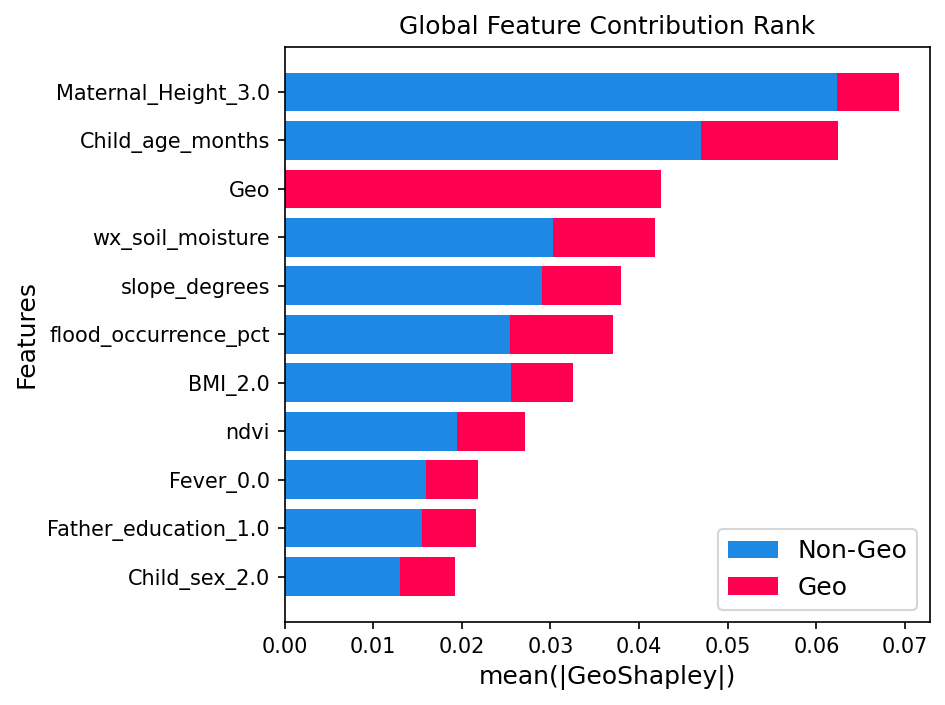

In [38]:
# ==========================================================
# Step-37 : GeoShapley Ranked Contribution Bar Plot
# ==========================================================

print("=" * 70)
print("GEOSHAPLEY CONTRIBUTION BAR PLOT")
print("=" * 70)

geo_results.contribution_bar_plot()

PARTIAL DEPENDENCE PLOTS (NON-SPATIAL)


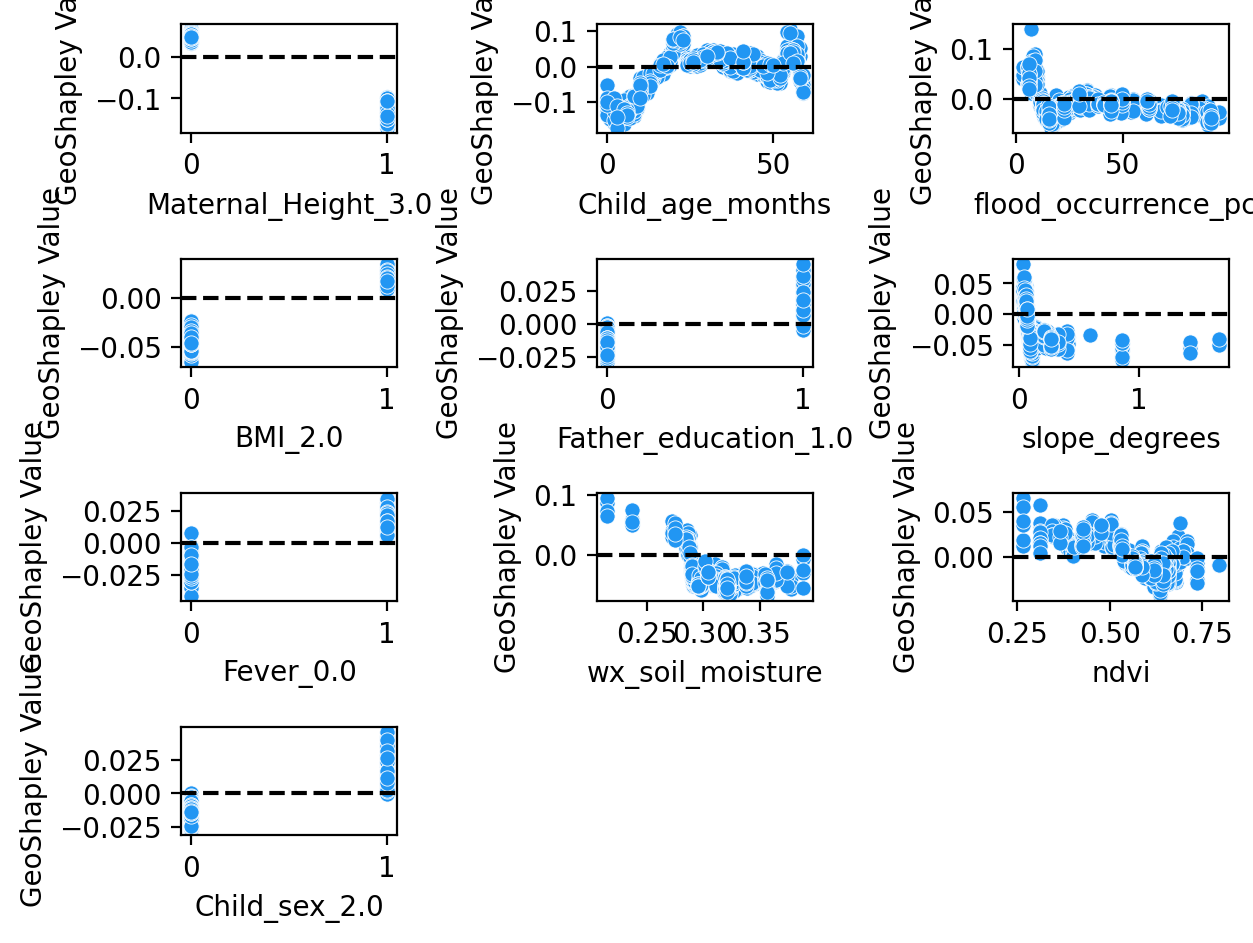

In [39]:
# ==========================================================
# Step-38 : Partial Dependence Plots (Primary / Non-spatial Effects)
# ==========================================================

print("=" * 70)
print("PARTIAL DEPENDENCE PLOTS (NON-SPATIAL)")
print("=" * 70)

geo_results.partial_dependence_plots()

In [40]:
# ==========================================================
# Step-39 : Spatially Varying Coefficients (SVC)
#           Top GeoShapley Features
# ==========================================================

import numpy as np
import pandas as pd


print("=" * 70)

print(
    "SPATIALLY VARYING COEFFICIENTS "
    "(TOP FEATURES)"
)

print("=" * 70)


# ==========================================================
# 1. IDENTIFY NON-COORDINATE TOP FEATURES
# ==========================================================

svc_features = [

    f

    for f
    in top_features

    if f
    not in coord_cols
]


feature_names_geo = list(

    X_geo_sample.columns[
        :-len(
            coord_cols
        )
    ]
)


if len(
    svc_features
) == 0:

    raise RuntimeError(

        "No non-coordinate GeoShapley features "
        "are available for SVC calculation."
    )


missing_svc_features = [

    feature

    for feature
    in svc_features

    if feature
    not in
    feature_names_geo
]


if missing_svc_features:

    raise RuntimeError(

        "SVC feature(s) not found in "
        "GeoShapley feature matrix: "

        f"{missing_svc_features}"
    )


print(
    "Computing SVC for features:"
)


print(
    svc_features
)


# ==========================================================
# 2. OBTAIN CHILD-LEVEL SVC VALUES
# ==========================================================

svc_dict = {}


for feat in svc_features:

    idx = feature_names_geo.index(
        feat
    )


    svc_values = geo_results.get_svc(

        [
            idx
        ],

        coef_type=
            "gwr"
    )


    svc_values = np.asarray(

        svc_values,

        dtype=float
    ).ravel()


    if len(
        svc_values
    ) != len(
        X_geo_sample
    ):

        raise RuntimeError(

            "SVC length mismatch "
            f"for feature: {feat}"
        )


    svc_dict[
        feat
    ] = svc_values


# ==========================================================
# 3. ALIGNMENT AUDIT
# ==========================================================

if not (

    len(
        X_geo_sample
    )

    ==

    len(
        cluster_ids_sample
    )

    ==

    len(
        dhs_coords_sample
    )

    ==

    len(
        weights_test
    )
):

    raise RuntimeError(

        "GeoShapley rows, DHS clusters, "
        "coordinates, and survey weights "
        "are not aligned."
    )


print(

    "\nGeoShapley observations:",

    len(
        X_geo_sample
    )
)


print(

    "DHS cluster IDs:",

    len(
        cluster_ids_sample
    )
)


print(

    "Survey weights:",

    len(
        weights_test
    )
)


# ==========================================================
# 4. CHILD-LEVEL SVC TABLE
# ==========================================================

cluster_geo_child = pd.DataFrame({

    "dhsclust":
        np.asarray(
            cluster_ids_sample
        ),

    "lat":

        dhs_coords_sample[
            "dhs_lat"
        ]

        .to_numpy(
            dtype=float
        ),

    "lon":

        dhs_coords_sample[
            "dhs_lon"
        ]

        .to_numpy(
            dtype=float
        ),

    "survey_weight":
        np.asarray(
            weights_test,
            dtype=float
        )
})


for feat in svc_features:

    cluster_geo_child[
        feat
    ] = svc_dict[
        feat
    ]


# ==========================================================
# 5. BASIC CHILD-LEVEL AUDIT
# ==========================================================

if (

    cluster_geo_child[
        [
            "lat",
            "lon"
        ]
    ]

    .isna()

    .any()

    .any()
):

    raise RuntimeError(
        "Missing GeoShapley coordinates detected."
    )


if (

    cluster_geo_child[
        "survey_weight"
    ]

    .isna()

    .any()
):

    raise RuntimeError(

        "Missing survey weights detected "
        "in GeoShapley sample."
    )


if (

    cluster_geo_child[
        "survey_weight"
    ]

    <=

    0

).any():

    raise RuntimeError(

        "Non-positive survey weights detected "
        "in GeoShapley sample."
    )


# ==========================================================
# 6. SAFE SURVEY-WEIGHTED MEAN
# ==========================================================

def weighted_mean_safe(

    values,
    weights
):

    values = np.asarray(

        values,

        dtype=float
    )


    weights = np.asarray(

        weights,

        dtype=float
    )


    valid = (

        np.isfinite(
            values
        )

        &

        np.isfinite(
            weights
        )

        &

        (
            weights
            >
            0
        )
    )


    if not np.any(
        valid
    ):

        return np.nan


    return float(

        np.average(

            values[
                valid
            ],

            weights=
                weights[
                    valid
                ]
        )
    )


# ==========================================================
# 7. SURVEY-WEIGHTED DHS-CLUSTER AGGREGATION
# ==========================================================

cluster_rows = []


for cluster_id, group in (

    cluster_geo_child

    .groupby(

        "dhsclust",

        sort=False
    )
):

    coordinate_pairs = (

        group[
            [
                "lat",
                "lon"
            ]
        ]

        .drop_duplicates()
    )


    if len(
        coordinate_pairs
    ) != 1:

        raise RuntimeError(

            "More than one coordinate pair found "
            "within DHS cluster "

            f"{cluster_id}."
        )


    row = {

        "dhsclust":
            cluster_id,

        "lat":
            float(
                group[
                    "lat"
                ].iloc[
                    0
                ]
            ),

        "lon":
            float(
                group[
                    "lon"
                ].iloc[
                    0
                ]
            ),

        "n_children":
            int(
                len(
                    group
                )
            ),

        "cluster_survey_weight":
            float(

                np.sum(

                    group[
                        "survey_weight"
                    ]

                    .to_numpy(
                        dtype=float
                    )
                )
            )
    }


    for feat in svc_features:

        row[
            feat
        ] = weighted_mean_safe(

            group[
                feat
            ].to_numpy(
                dtype=float
            ),

            group[
                "survey_weight"
            ].to_numpy(
                dtype=float
            )
        )


    cluster_rows.append(
        row
    )


cluster_geo = pd.DataFrame(
    cluster_rows
)


# ==========================================================
# 8. FINAL CLUSTER-LEVEL AUDIT
# ==========================================================

if (

    cluster_geo[
        "dhsclust"
    ]

    .duplicated()

    .any()
):

    raise RuntimeError(

        "Duplicate DHS clusters remain "
        "after SVC aggregation."
    )


if (

    cluster_geo[
        svc_features
    ]

    .isna()

    .all(
        axis=1
    )

    .any()
):

    raise RuntimeError(

        "At least one DHS cluster has "
        "no valid SVC values."
    )


# ==========================================================
# 9. SUMMARY
# ==========================================================

print(
    "\nCluster-level SVC table:"
)


display(
    cluster_geo.head()
)


print(

    "\nChild-level GeoShapley rows:",

    len(
        cluster_geo_child
    )
)


print(

    "Unique DHS clusters:",

    cluster_geo[
        "dhsclust"
    ].nunique()
)


print(

    "Cluster-level rows:",

    len(
        cluster_geo
    )
)


print(
    "\nChildren per DHS cluster:"
)


display(

    cluster_geo[
        "n_children"
    ]

    .describe()
)


print(
    "\nCluster survey-weight summary:"
)


display(

    cluster_geo[
        "cluster_survey_weight"
    ]

    .describe()
)


print(
    "\nCoordinate summary:"
)


display(

    cluster_geo[
        [
            "lat",
            "lon"
        ]
    ]

    .describe()
)


# ==========================================================
# 10. FINAL AUDIT MESSAGE
# ==========================================================

print(
    "\n✓ Same GeoShapley SVC framework retained."
)


print(
    "✓ Same GeoShapley child-level SVC values retained."
)


print(

    "✓ No model retraining or feature-selection "
    "change was made."
)


print(

    "✓ Child-level SVC values were aggregated "
    "to DHS-cluster level using DHS survey weights."
)


print(

    "✓ One unique row now represents each "
    "DHS cluster."
)

SPATIALLY VARYING COEFFICIENTS (TOP FEATURES)
Computing SVC for features:
['Maternal_Height_3.0', 'Child_age_months', 'flood_occurrence_pct', 'BMI_2.0', 'Father_education_1.0', 'slope_degrees', 'Fever_0.0', 'wx_soil_moisture', 'ndvi', 'Child_sex_2.0']

GeoShapley observations: 716
DHS cluster IDs: 716
Survey weights: 716

Cluster-level SVC table:


,dhsclust,lat,lon,n_children,cluster_survey_weight,Maternal_Height_3.0,Child_age_months,flood_occurrence_pct,BMI_2.0,Father_education_1.0,slope_degrees,Fever_0.0,wx_soil_moisture,ndvi,Child_sex_2.0
0,3,22.713827,90.383011,4,0.633668,0.045319,-0.001777,-0.000103,0.001478,-0.003643,0.062293,-0.023471,0.192708,0.027354,0.001759
1,7,22.715451,90.361845,2,0.182650,0.047663,-0.001777,-0.000098,0.004730,-0.003498,0.063195,-0.023007,0.194887,0.028209,0.001729
2,11,22.720758,90.328569,6,0.567468,0.057862,-0.001736,-0.000088,0.016358,-0.003357,0.063551,-0.021334,0.198167,0.029512,0.001594
3,19,22.986983,90.160907,3,1.038723,0.044061,-0.001248,-0.000036,0.044818,0.008756,0.028084,-0.007555,0.480239,-0.210996,0.050598
4,25,21.985376,90.077147,3,2.119488,0.066921,-0.001084,-0.000016,-0.011776,-0.019202,-0.100988,-0.028066,-0.087670,0.005519,-0.000141



Child-level GeoShapley rows: 716
Unique DHS clusters: 134
Cluster-level rows: 134

Children per DHS cluster:


count    134.000000
mean       5.343284
std        2.595845
min        1.000000
25%        4.000000
50%        5.000000
75%        6.000000
max       15.000000
Name: n_children, dtype: float64


Cluster survey-weight summary:


count    134.000000
mean       5.433036
std        3.780501
min        0.182650
25%        2.904400
50%        4.398657
75%        7.307841
max       17.457710
Name: cluster_survey_weight, dtype: float64


Coordinate summary:


,lat,lon
count,134.000000,134.000000
mean,23.883056,90.299570
std,1.059929,1.019776
min,21.761719,88.287634
25%,22.974704,89.465655
50%,23.842481,90.305419
75%,24.727543,91.060123
max,26.270475,92.224194



✓ Same GeoShapley SVC framework retained.
✓ Same GeoShapley child-level SVC values retained.
✓ No model retraining or feature-selection change was made.
✓ Child-level SVC values were aggregated to DHS-cluster level using DHS survey weights.
✓ One unique row now represents each DHS cluster.


GEOSHAPLEY-DERIVED SVC MAPS


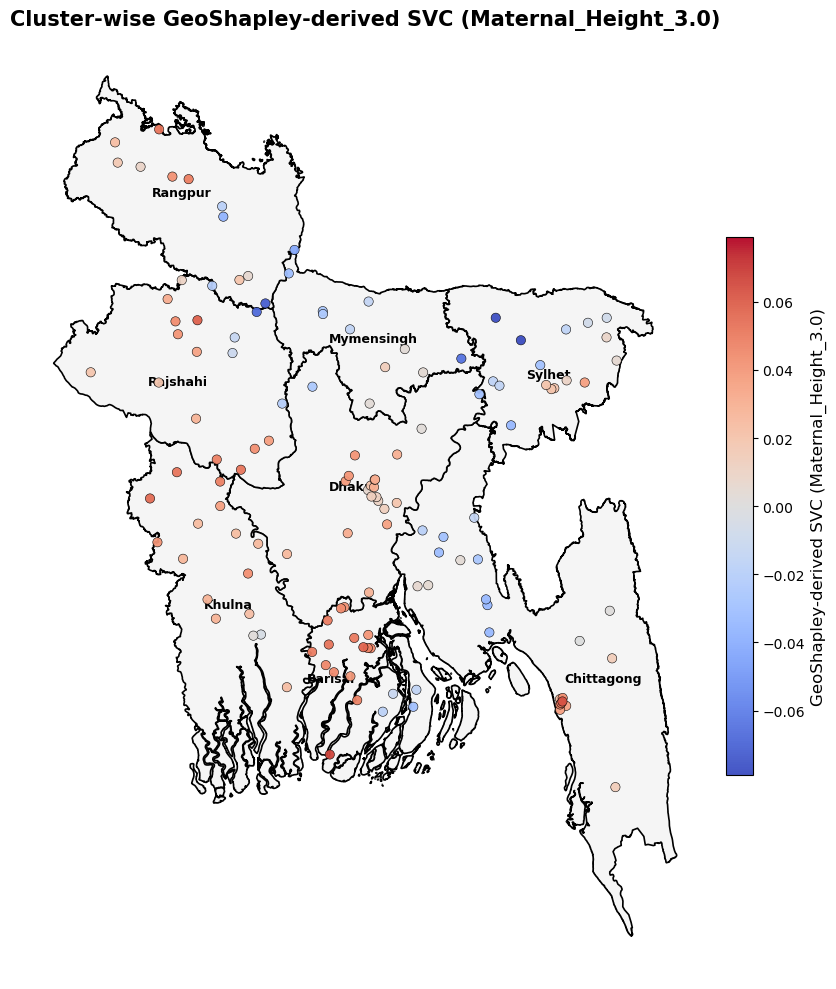

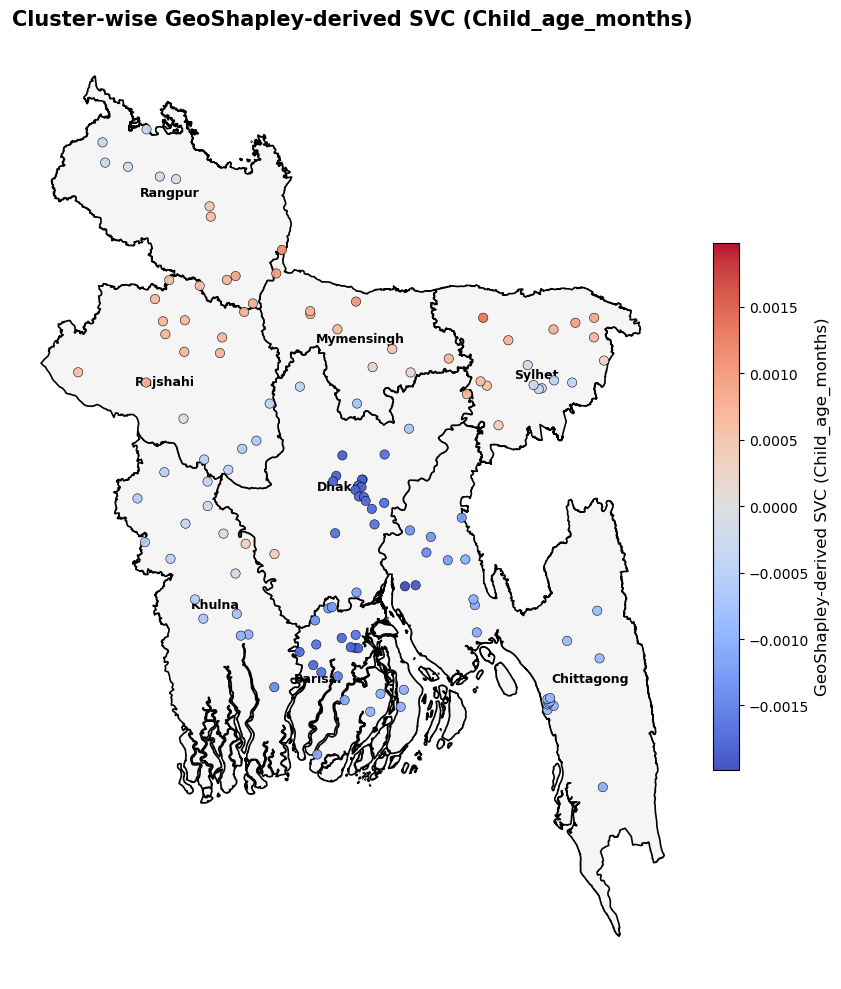

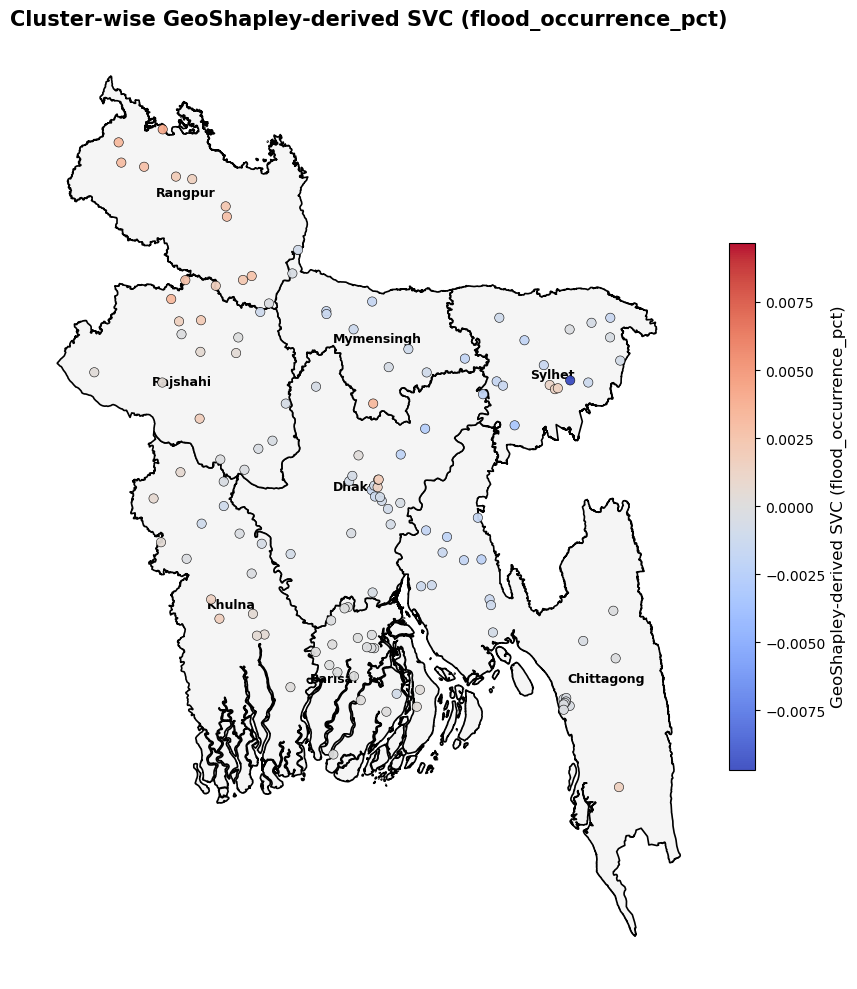

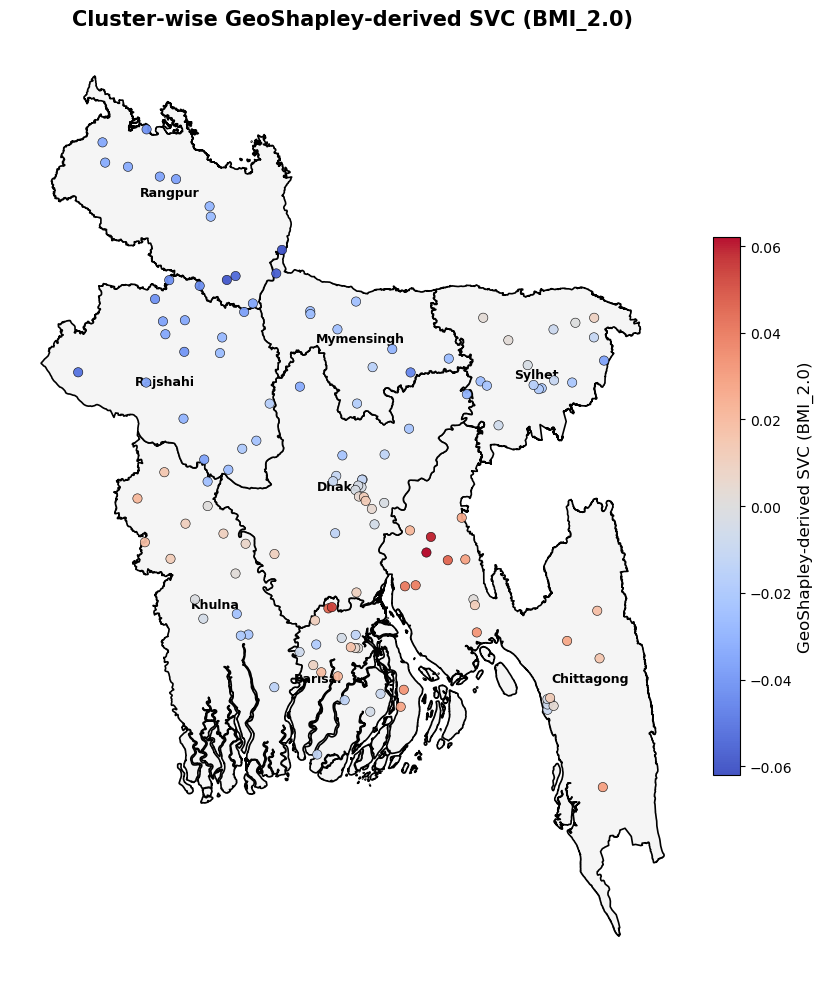

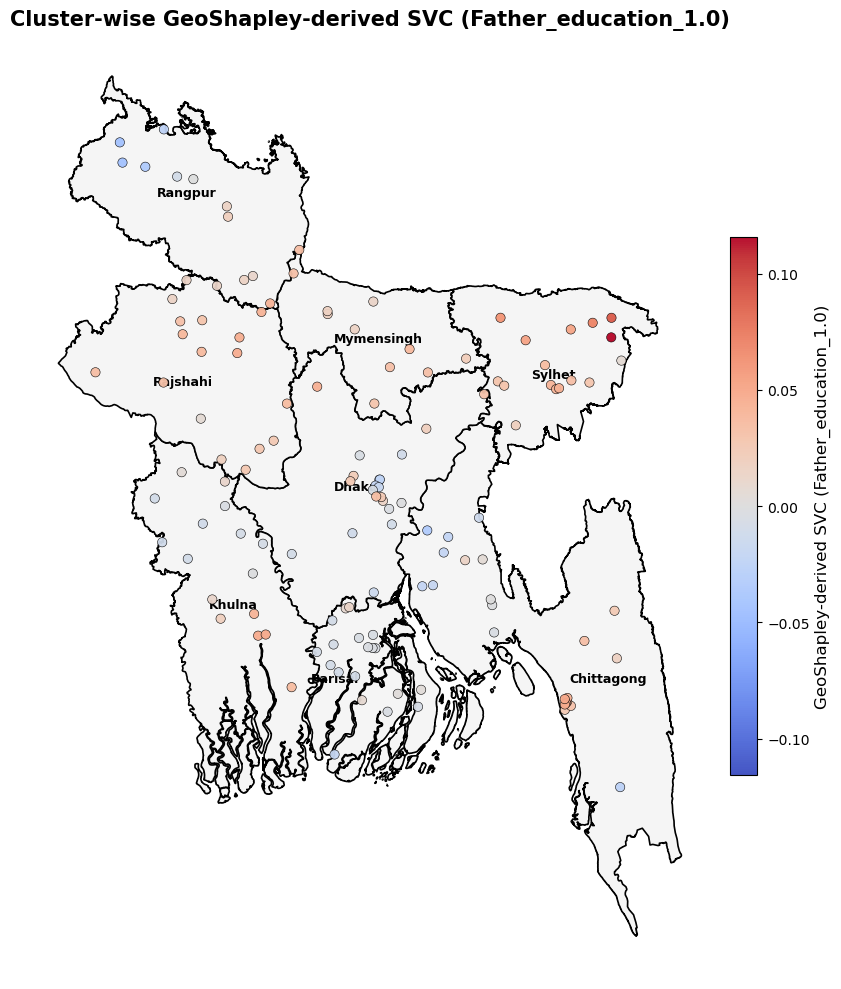

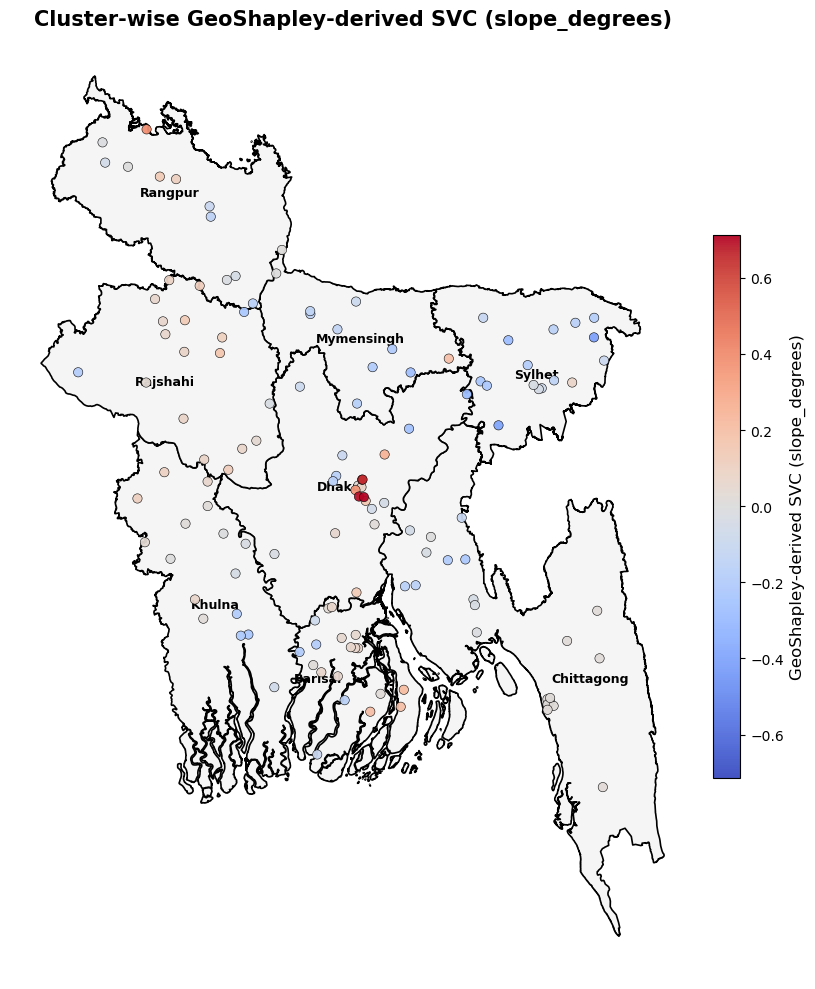

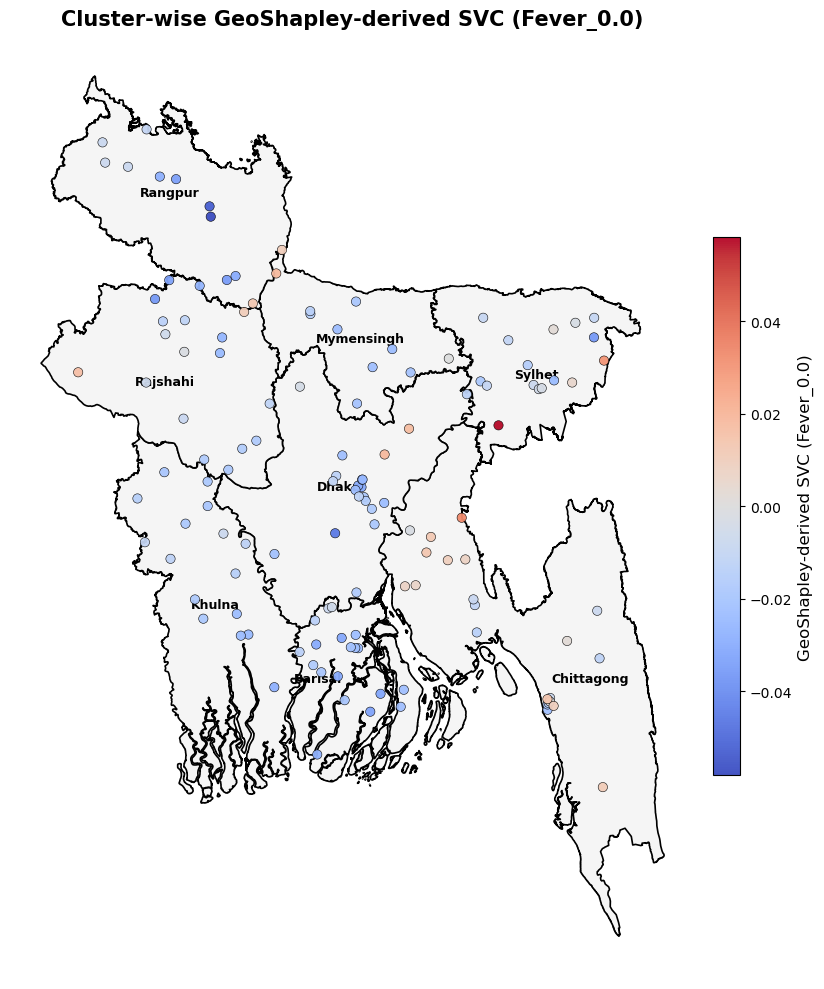

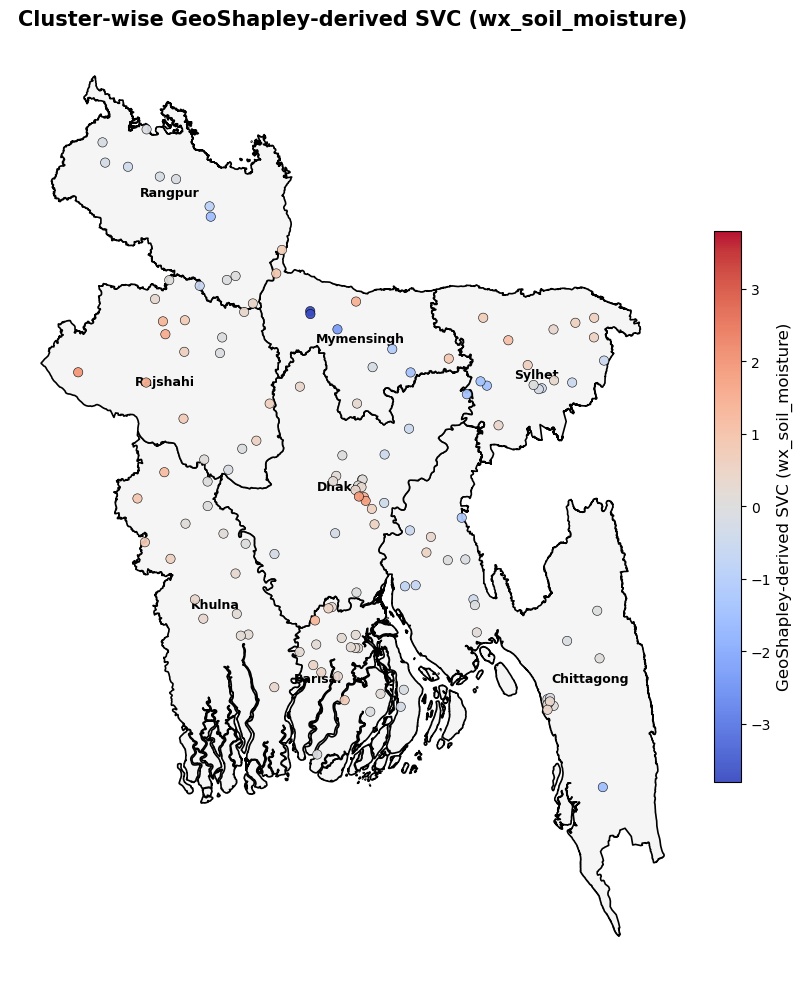

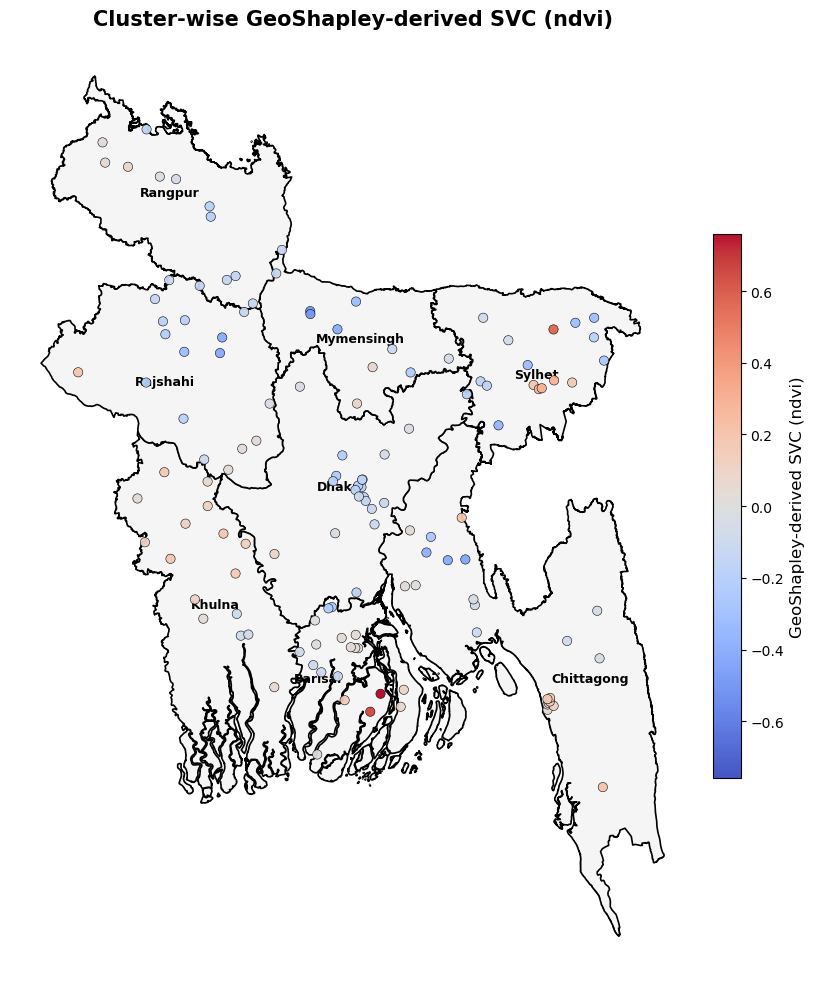

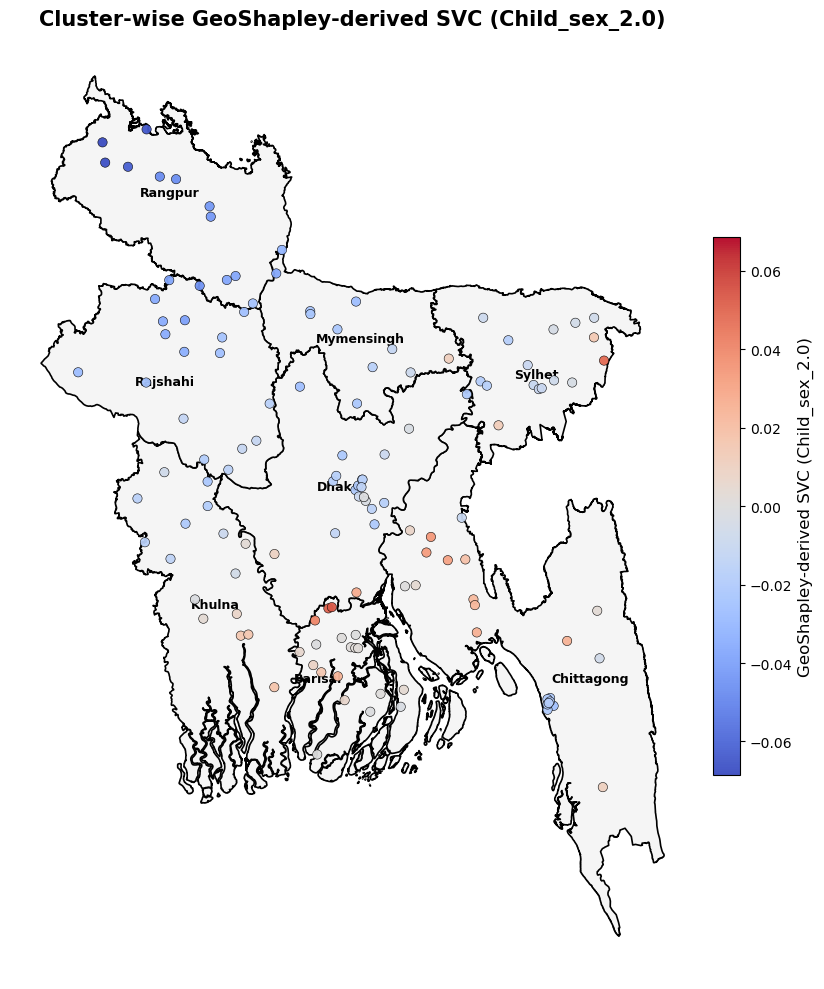


✓ Same GeoShapley SVC values are mapped; only plotting robustness and terminology were cleaned.


In [41]:
# ==========================================================
# Step-40 : Cluster-wise GeoShapley-Derived
#           Spatially Varying Coefficient (SVC) Maps
# ==========================================================

import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt


print("=" * 70)
print("GEOSHAPLEY-DERIVED SVC MAPS")
print("=" * 70)


# ==========================================================
# 1. LOAD BANGLADESH DIVISION BOUNDARY
# ==========================================================

if "DIVISION_BOUNDARY_FILE" not in globals():

    raise RuntimeError(
        "DIVISION_BOUNDARY_FILE is not defined. "
        "Run Step-2 first."
    )


if not DIVISION_BOUNDARY_FILE.exists():

    raise FileNotFoundError(
        f"Division boundary file not found:\n"
        f"{DIVISION_BOUNDARY_FILE}"
    )


divisions = gpd.read_file(
    DIVISION_BOUNDARY_FILE
)


if divisions.crs is None:

    divisions = divisions.set_crs(
        "EPSG:4326",
        allow_override=True
    )

else:

    divisions = divisions.to_crs(
        "EPSG:4326"
    )


name_col = "NAME_1"


if name_col not in divisions.columns:

    raise RuntimeError(
        "Division-name column not found: "
        f"{name_col}"
    )


# ==========================================================
# 2. ONE SVC MAP PER FEATURE
# ==========================================================

for best_feature in svc_features:

    vals = (

        cluster_geo[
            best_feature
        ]

        .astype(
            float
        )

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


    valid_vals = vals.dropna()


    if len(
        valid_vals
    ) == 0:

        abs_max = 1.0

    else:

        abs_max = max(

            abs(
                valid_vals.min()
            ),

            abs(
                valid_vals.max()
            )
        )


    if (
        not np.isfinite(
            abs_max
        )
        or
        abs_max <= 0
    ):

        abs_max = 1.0


    cluster_geo_sorted = (

        cluster_geo

        .sort_values(
            by=best_feature
        )

        .copy()
    )


    fig, ax = plt.subplots(
        figsize=(
            10,
            10
        )
    )


    divisions.plot(

        ax=ax,

        color="#f5f5f5",

        edgecolor="black",

        linewidth=1.2,

        zorder=1
    )


    sc = ax.scatter(

        cluster_geo_sorted[
            "lon"
        ],

        cluster_geo_sorted[
            "lat"
        ],

        c=
            cluster_geo_sorted[
                best_feature
            ],

        cmap="coolwarm",

        s=45,

        edgecolor="black",

        linewidth=0.4,

        alpha=0.95,

        vmin=
            -abs_max,

        vmax=
            abs_max,

        zorder=3
    )


    cb = plt.colorbar(

        sc,

        ax=ax,

        fraction=0.03,

        pad=0.02
    )


    cb.set_label(

        "GeoShapley-derived SVC "
        f"({best_feature})",

        fontsize=12
    )


    for _, row in divisions.iterrows():

        label_point = (

            row.geometry

            .representative_point()
        )


        ax.text(

            label_point.x,

            label_point.y,

            row[
                name_col
            ],

            ha="center",

            va="center",

            fontsize=9,

            fontweight="bold",

            zorder=2
        )


    ax.set_title(

        "Cluster-wise GeoShapley-derived SVC "
        f"({best_feature})",

        fontsize=15,

        fontweight="bold"
    )


    ax.set_xticks(
        []
    )

    ax.set_yticks(
        []
    )


    for spine in ax.spines.values():

        spine.set_visible(
            False
        )


    plt.tight_layout()


    safe_feature_name = (

        str(
            best_feature
        )

        .replace(
            "/",
            "_"
        )

        .replace(
            "\\",
            "_"
        )
    )


    plt.savefig(

        f"geoshapley_svc_map_"
        f"{safe_feature_name}.png",

        dpi=300,

        bbox_inches="tight"
    )


    plt.show()


print(
    "\n✓ Same GeoShapley SVC values are mapped; "
    "only plotting robustness and terminology "
    "were cleaned."
)

COMBINED GEOSHAPLEY-DERIVED SVC MAP
SVC features included: 10
Features: ['Maternal_Height_3.0', 'Child_age_months', 'flood_occurrence_pct', 'BMI_2.0', 'Father_education_1.0', 'slope_degrees', 'Fever_0.0', 'wx_soil_moisture', 'ndvi', 'Child_sex_2.0']
Figure layout: 4 rows × 3 columns


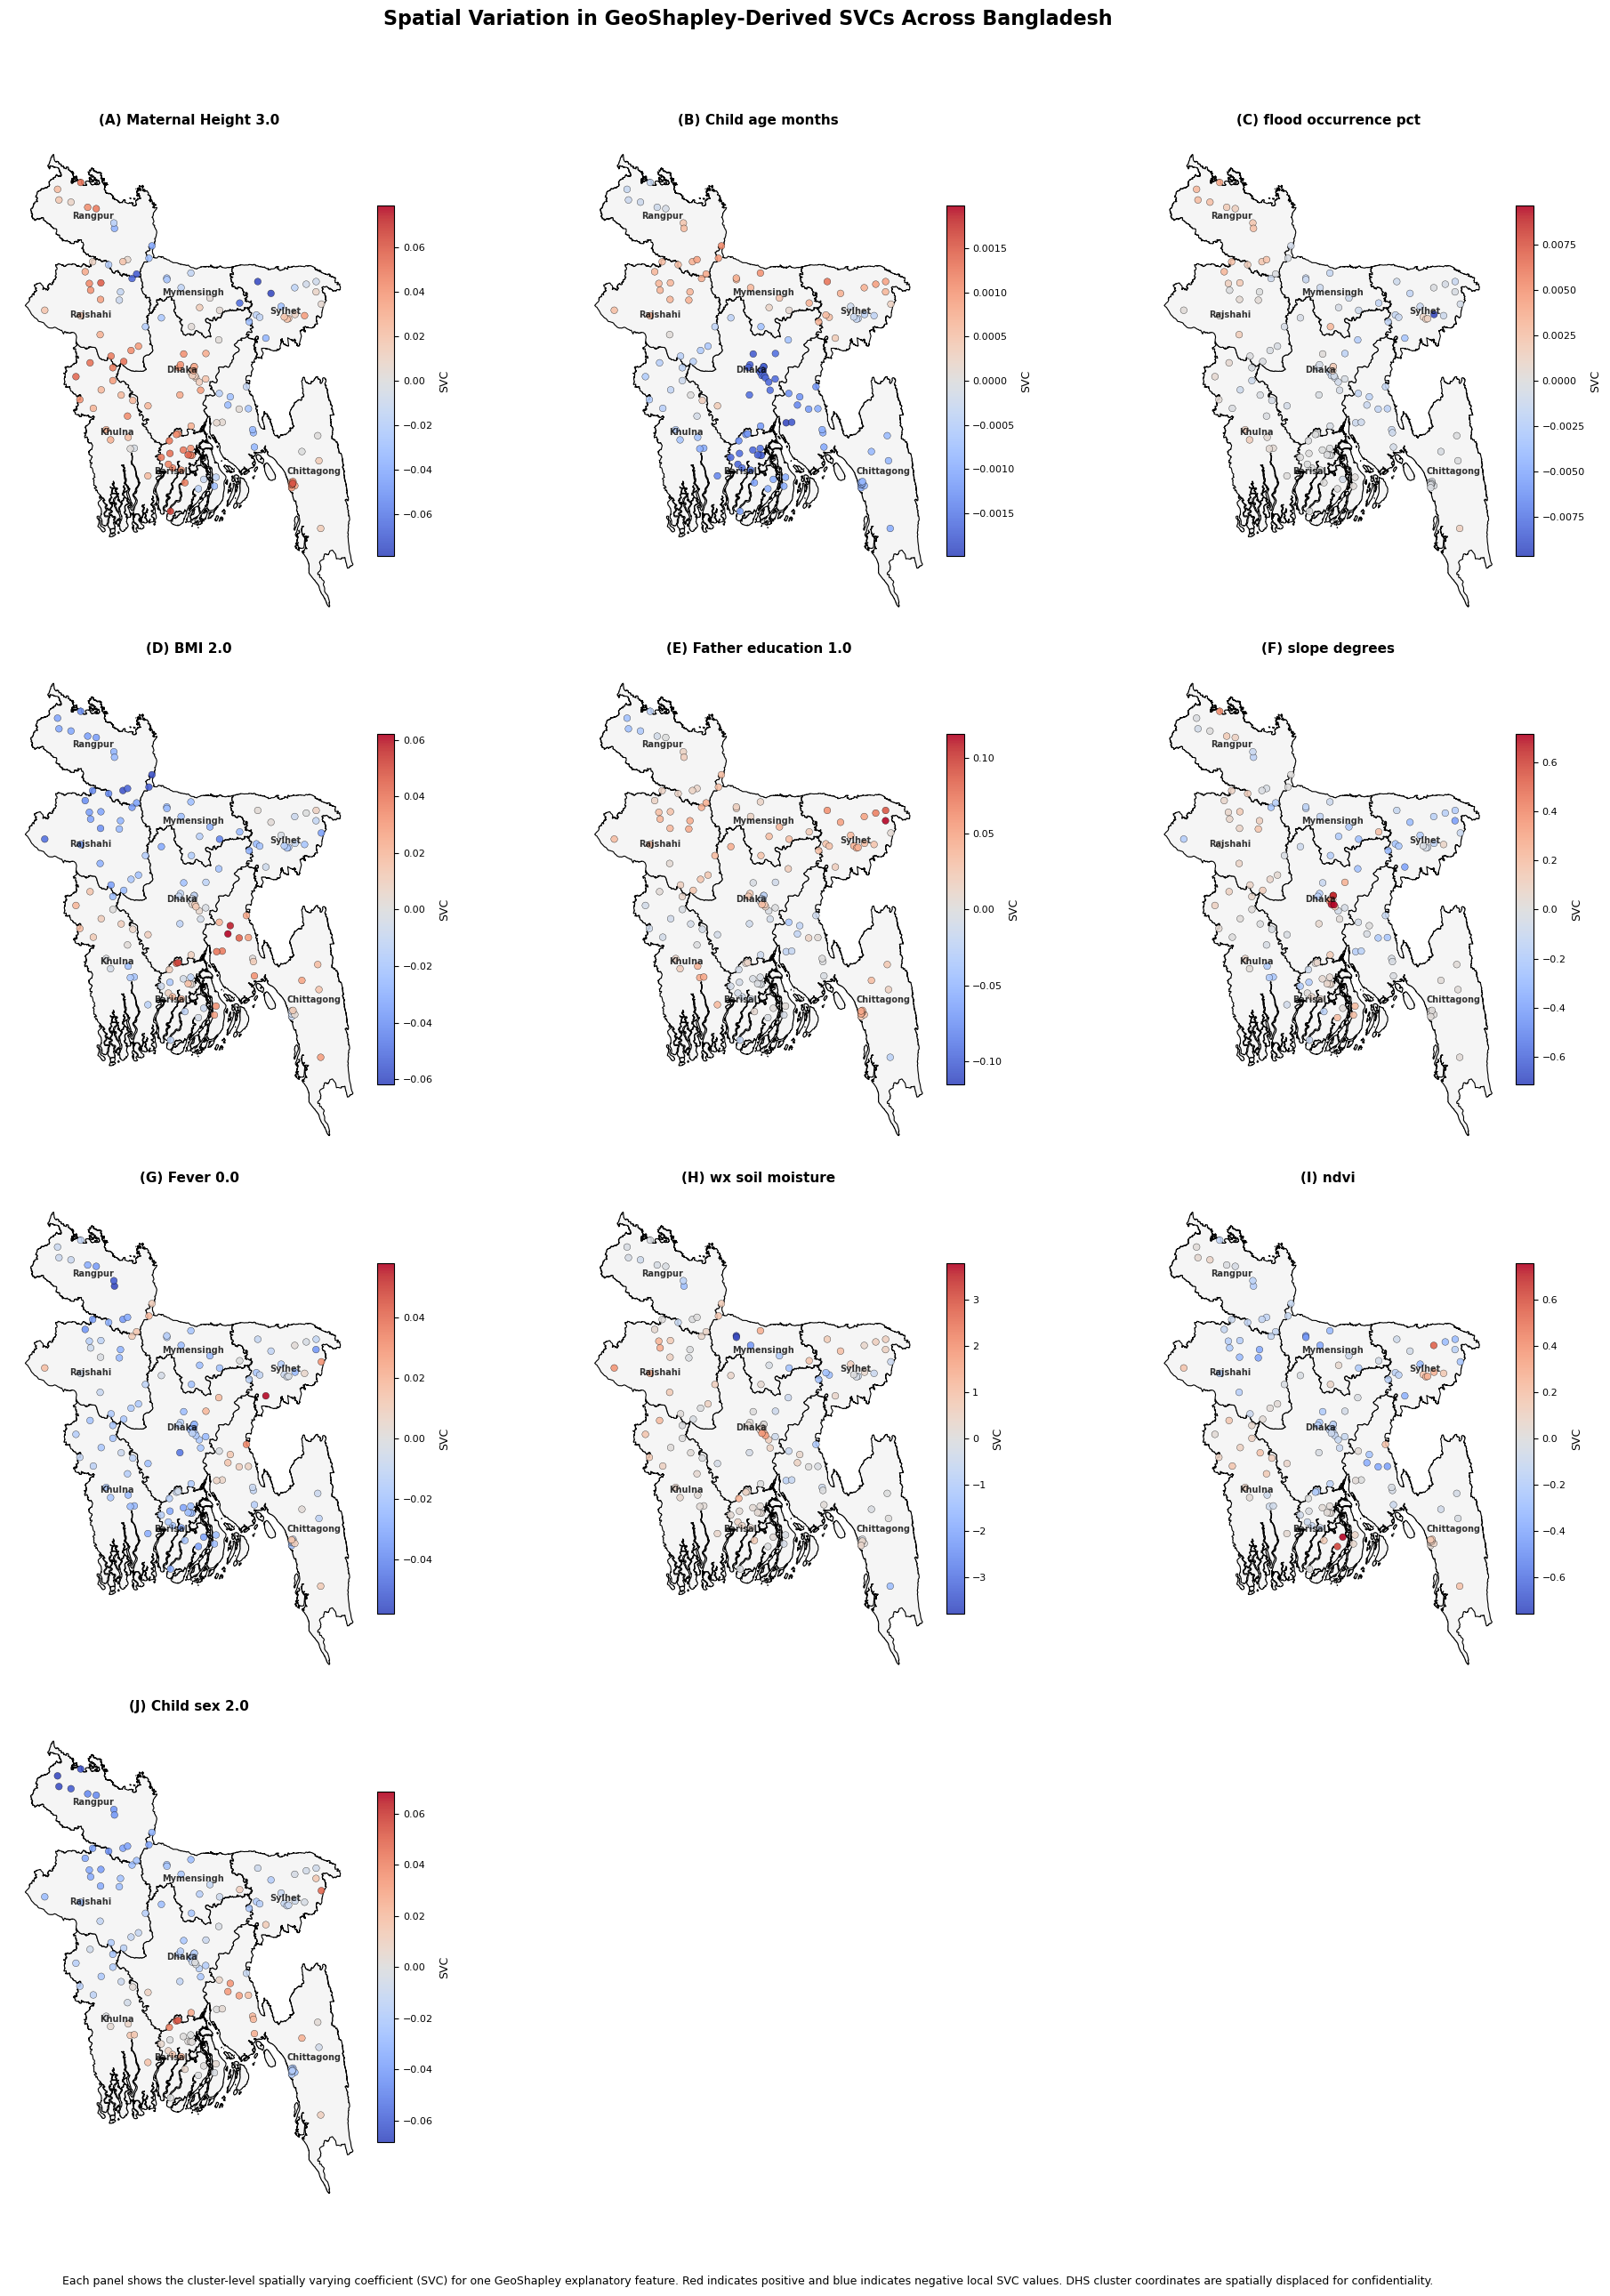


✓ All GeoShapley-derived SVC features are included.
✓ Only ONE combined map figure was generated.
✓ No SVC features were removed from the figure.
✓ Each feature retains its own symmetric SVC scale.
✓ Positive and negative SVC values remain visible.
✓ DHS displaced coordinates are interpreted only as cluster-level spatial approximations.

Saved figure:
geoshapley_combined_svc_map.png


In [42]:
# ==========================================================
# Step-41 : Combined GeoShapley-Derived SVC Map
#           ALL SVC FEATURES IN ONE FIGURE
# ==========================================================

import math
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt


print("=" * 70)
print("COMBINED GEOSHAPLEY-DERIVED SVC MAP")
print("=" * 70)


# ==========================================================
# 1. LOAD BANGLADESH DIVISION BOUNDARY
# ==========================================================

if "DIVISION_BOUNDARY_FILE" not in globals():

    raise RuntimeError(
        "DIVISION_BOUNDARY_FILE is not defined. "
        "Run Step-2 first."
    )


if not DIVISION_BOUNDARY_FILE.exists():

    raise FileNotFoundError(
        f"Division boundary file not found:\n"
        f"{DIVISION_BOUNDARY_FILE}"
    )


divisions = gpd.read_file(
    DIVISION_BOUNDARY_FILE
)


if divisions.crs is None:

    divisions = divisions.set_crs(
        "EPSG:4326",
        allow_override=True
    )

else:

    divisions = divisions.to_crs(
        "EPSG:4326"
    )


name_col = "NAME_1"


if name_col not in divisions.columns:

    raise RuntimeError(
        "Division-name column not found: "
        f"{name_col}"
    )


# ==========================================================
# 2. FIGURE LAYOUT
# ==========================================================

n_features = len(
    svc_features
)


if n_features == 0:

    raise RuntimeError(
        "No SVC features are available for mapping."
    )


if n_features == 1:

    ncols = 1

elif n_features <= 4:

    ncols = 2

else:

    ncols = 3


nrows = math.ceil(

    n_features

    /

    ncols
)


print(
    "SVC features included:",
    n_features
)


print(
    "Features:",
    svc_features
)


print(
    "Figure layout:",
    f"{nrows} rows × {ncols} columns"
)


# ==========================================================
# 3. CREATE FIGURE
# ==========================================================

fig, axes = plt.subplots(

    nrows=nrows,

    ncols=ncols,

    figsize=(
        6.5 * ncols,
        6.5 * nrows
    )
)


axes = np.atleast_1d(
    axes
).ravel()


# ==========================================================
# 4. PLOT ALL SVC FEATURES
# ==========================================================

for panel_idx, best_feature in enumerate(
    svc_features
):

    ax = axes[
        panel_idx
    ]


    vals = (

        cluster_geo[
            best_feature
        ]

        .astype(
            float
        )

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


    valid_vals = vals.dropna()


    if len(
        valid_vals
    ) == 0:

        abs_max = 1.0

    else:

        abs_max = max(

            abs(
                valid_vals.min()
            ),

            abs(
                valid_vals.max()
            )
        )


    if (
        not np.isfinite(
            abs_max
        )
        or
        abs_max == 0
    ):

        abs_max = 1.0


    cluster_geo_sorted = (

        cluster_geo

        .sort_values(
            by=best_feature
        )

        .copy()
    )


    divisions.plot(

        ax=ax,

        color="#f5f5f5",

        edgecolor="black",

        linewidth=0.8
    )


    sc = ax.scatter(

        cluster_geo_sorted[
            "lon"
        ],

        cluster_geo_sorted[
            "lat"
        ],

        c=
            cluster_geo_sorted[
                best_feature
            ],

        cmap="coolwarm",

        s=30,

        edgecolor="black",

        linewidth=0.25,

        alpha=0.9,

        vmin=
            -abs_max,

        vmax=
            abs_max
    )


    cb = fig.colorbar(

        sc,

        ax=ax,

        fraction=0.035,

        pad=0.015
    )


    cb.set_label(
        "SVC",
        fontsize=9
    )


    cb.ax.tick_params(
        labelsize=8
    )


    for _, row in divisions.iterrows():

        label_point = (

            row.geometry

            .representative_point()
        )


        ax.text(

            label_point.x,

            label_point.y,

            row[
                name_col
            ],

            ha="center",

            va="center",

            fontsize=7,

            fontweight="bold",

            alpha=0.8
        )


    panel_letter = chr(
        65 + panel_idx
    )


    clean_feature_name = (

        str(
            best_feature
        )

        .replace(
            "_",
            " "
        )
    )


    ax.set_title(

        f"({panel_letter}) "
        f"{clean_feature_name}",

        fontsize=11,

        fontweight="bold"
    )


    ax.set_xticks(
        []
    )

    ax.set_yticks(
        []
    )


    for spine in ax.spines.values():

        spine.set_visible(
            False
        )


# ==========================================================
# 5. REMOVE EMPTY PANELS
# ==========================================================

for empty_idx in range(

    n_features,

    len(
        axes
    )
):

    axes[
        empty_idx
    ].axis(
        "off"
    )


# ==========================================================
# 6. TITLE
# ==========================================================

fig.suptitle(

    "Spatial Variation in GeoShapley-Derived "
    "SVCs Across Bangladesh",

    fontsize=16,

    fontweight="bold",

    y=0.995
)


# ==========================================================
# 7. FIGURE NOTE
# ==========================================================

fig.text(

    0.5,

    0.01,

    (
        "Each panel shows the cluster-level "
        "spatially varying coefficient (SVC) "
        "for one GeoShapley explanatory feature. "
        "Red indicates positive and blue indicates "
        "negative local SVC values. DHS cluster "
        "coordinates are spatially displaced "
        "for confidentiality."
    ),

    ha="center",

    va="bottom",

    fontsize=9,

    wrap=True
)


plt.tight_layout(

    rect=[
        0,
        0.035,
        1,
        0.97
    ]
)


plt.savefig(

    "geoshapley_combined_svc_map.png",

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ==========================================================
# 8. AUDIT
# ==========================================================

print(
    "\n✓ All GeoShapley-derived SVC "
    "features are included."
)

print(
    "✓ Only ONE combined map figure "
    "was generated."
)

print(
    "✓ No SVC features were removed "
    "from the figure."
)

print(
    "✓ Each feature retains its own "
    "symmetric SVC scale."
)

print(
    "✓ Positive and negative SVC values "
    "remain visible."
)

print(
    "✓ DHS displaced coordinates are "
    "interpreted only as cluster-level "
    "spatial approximations."
)

print(
    "\nSaved figure:"
)

print(
    "geoshapley_combined_svc_map.png"
)

ONE READABLE GEOSHAPLEY SVC MAP


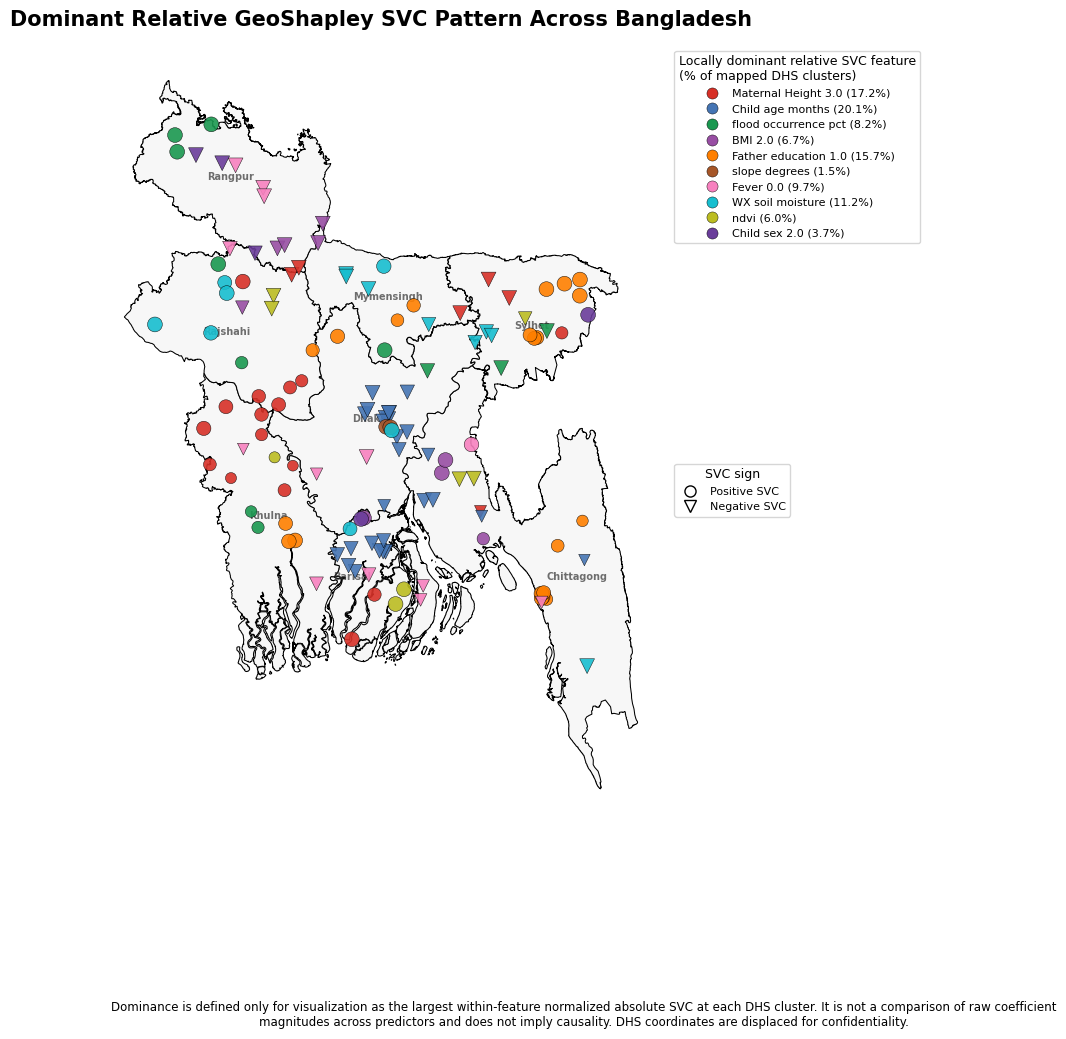


✓ Every SVC feature participates in the relative within-feature comparison.
✓ Raw SVC values are unchanged.
✓ One marker is plotted per DHS cluster.
✓ Map terminology describes a relative SVC pattern, not a causal effect or raw cross-feature ranking.

Saved figure:
geoshapley_dominant_relative_svc_map.png


In [43]:
# ==========================================================
## Step-42 : ONE READABLE GeoShapley Map
#           Dominant Relative GeoShapley SVC Pattern
#           by DHS Cluster
#
# ALL svc_features are included.
#
# Colour = locally dominant relative SVC feature
# Shape  = sign of raw SVC
# Size   = within-feature relative |SVC| strength
#
# IMPORTANT:
# This is a visualization summary.
# It is NOT a causal ranking and does NOT compare
# raw coefficient magnitudes across predictors.
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


print("=" * 75)
print("ONE READABLE GEOSHAPLEY SVC MAP")
print("=" * 75)


# ==========================================================
# 1. CHECKS
# ==========================================================

if "svc_features" not in globals():

    raise RuntimeError(
        "svc_features not found. Run Step-39 first."
    )


if "cluster_geo" not in globals():

    raise RuntimeError(
        "cluster_geo not found. Run Step-39 first."
    )


if "divisions" not in globals():

    raise RuntimeError(
        "divisions not found. "
        "Run the SVC map step first."
    )


if len(
    svc_features
) == 0:

    raise RuntimeError(
        "No GeoShapley SVC features are available."
    )


for col in [
    "lon",
    "lat"
]:

    if col not in cluster_geo.columns:

        raise RuntimeError(
            f"Missing coordinate column: {col}"
        )


for feature in svc_features:

    if feature not in cluster_geo.columns:

        raise RuntimeError(
            "SVC feature missing from cluster_geo: "
            f"{feature}"
        )


# ==========================================================
# 2. FEATURE COLOURS
# ==========================================================

feature_colors = [

    "#D73027",
    "#4575B4",
    "#1A9850",
    "#984EA3",
    "#FF7F00",
    "#A65628",
    "#F781BF",
    "#17BECF",
    "#BCBD22",
    "#6A3D9A",
    "#1B9E77",
    "#E7298A",
    "#7570B3",
    "#66A61E"
]


if len(
    svc_features
) > len(
    feature_colors
):

    raise RuntimeError(
        "More SVC features than available colours."
    )


feature_color_map = {

    feature:
        feature_colors[
            i
        ]

    for i, feature
    in enumerate(
        svc_features
    )
}


# ==========================================================
# 3. RAW SVC MATRIX
# ==========================================================

svc_raw = (

    cluster_geo[
        svc_features
    ]

    .astype(
        float
    )

    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
)


# ==========================================================
# 4. WITHIN-FEATURE RELATIVE STRENGTH
#
# |SVC| / 95th percentile |SVC|
#
# Capped at 1.
#
# This normalization is ONLY for map visualization.
# Raw SVC values remain unchanged.
# ==========================================================

relative_strength = pd.DataFrame(

    index=
        cluster_geo.index,

    columns=
        svc_features,

    dtype=float
)


feature_scale = {}


for feature in svc_features:

    abs_values = (

        svc_raw[
            feature
        ].abs()
    )


    valid_values = (

        abs_values[
            np.isfinite(
                abs_values
            )
        ]
    )


    if len(
        valid_values
    ) == 0:

        scale = 1.0

    else:

        scale = float(

            np.nanpercentile(
                valid_values,
                95
            )
        )


    if (
        not np.isfinite(
            scale
        )
        or
        scale <= 0
    ):

        if len(
            valid_values
        ) > 0:

            scale = float(

                np.nanmax(
                    valid_values
                )
            )


    if (
        not np.isfinite(
            scale
        )
        or
        scale <= 0
    ):

        scale = 1.0


    feature_scale[
        feature
    ] = scale


    relative_strength[
        feature
    ] = (

        abs_values

        /

        scale

    ).clip(
        lower=0,
        upper=1
    )


# ==========================================================
# 5. LOCALLY DOMINANT RELATIVE SVC FEATURE
# ==========================================================

valid_row = (

    relative_strength

    .notna()

    .any(
        axis=1
    )
)


dominant_feature = pd.Series(

    index=
        cluster_geo.index,

    dtype="object"
)


dominant_feature.loc[
    valid_row
] = (

    relative_strength

    .loc[
        valid_row
    ]

    .idxmax(
        axis=1
    )
)


dominant_raw_svc = pd.Series(

    np.nan,

    index=
        cluster_geo.index,

    dtype=float
)


dominant_strength = pd.Series(

    np.nan,

    index=
        cluster_geo.index,

    dtype=float
)


for idx in cluster_geo.index:

    feature = (
        dominant_feature.loc[
            idx
        ]
    )


    if pd.isna(
        feature
    ):

        continue


    dominant_raw_svc.loc[
        idx
    ] = (

        svc_raw.loc[
            idx,
            feature
        ]
    )


    dominant_strength.loc[
        idx
    ] = (

        relative_strength.loc[
            idx,
            feature
        ]
    )


dominant_direction = pd.Series(

    np.nan,

    index=
        cluster_geo.index,

    dtype="object"
)


dominant_direction.loc[
    dominant_raw_svc
    >=
    0
] = "Positive"


dominant_direction.loc[
    dominant_raw_svc
    <
    0
] = "Negative"


# ==========================================================
# 6. SAVE MAPPING VARIABLES
# ==========================================================

cluster_geo[
    "dominant_svc_feature"
] = dominant_feature


cluster_geo[
    "dominant_svc_value"
] = dominant_raw_svc


cluster_geo[
    "dominant_relative_strength"
] = dominant_strength


cluster_geo[
    "dominant_direction"
] = dominant_direction


marker_sizes = (

    24

    +

    90
    *
    dominant_strength
    .fillna(0)
    .to_numpy()
)


# ==========================================================
# 7. MAP
# ==========================================================

fig, ax = plt.subplots(

    figsize=(
        10,
        12
    )
)


divisions.plot(

    ax=ax,

    color="#F7F7F7",

    edgecolor="black",

    linewidth=0.75,

    zorder=1
)


for feature in svc_features:

    feature_color = (

        feature_color_map[
            feature
        ]
    )


    # Positive SVC
    mask_positive = (

        (
            dominant_feature
            ==
            feature
        )

        &

        (
            dominant_direction
            ==
            "Positive"
        )
    )


    if (
        mask_positive.sum()
        >
        0
    ):

        ax.scatter(

            cluster_geo.loc[
                mask_positive,
                "lon"
            ],

            cluster_geo.loc[
                mask_positive,
                "lat"
            ],

            s=
                marker_sizes[
                    mask_positive.to_numpy()
                ],

            marker="o",

            facecolor=
                feature_color,

            edgecolor="black",

            linewidth=0.35,

            alpha=0.9,

            zorder=4
        )


    # Negative SVC
    mask_negative = (

        (
            dominant_feature
            ==
            feature
        )

        &

        (
            dominant_direction
            ==
            "Negative"
        )
    )


    if (
        mask_negative.sum()
        >
        0
    ):

        ax.scatter(

            cluster_geo.loc[
                mask_negative,
                "lon"
            ],

            cluster_geo.loc[
                mask_negative,
                "lat"
            ],

            s=
                marker_sizes[
                    mask_negative.to_numpy()
                ],

            marker="v",

            facecolor=
                feature_color,

            edgecolor="black",

            linewidth=0.35,

            alpha=0.9,

            zorder=4
        )


# ==========================================================
# 8. DIVISION LABELS
# ==========================================================

if "NAME_1" in divisions.columns:

    for _, row in divisions.iterrows():

        p = (
            row.geometry
            .representative_point()
        )


        ax.text(

            p.x,

            p.y,

            row[
                "NAME_1"
            ],

            fontsize=7,

            fontweight="bold",

            ha="center",

            va="center",

            color="#333333",

            alpha=0.7,

            zorder=2
        )


# ==========================================================
# 9. LEGENDS
# ==========================================================

def clean_feature_name(
    feature
):

    name = (

        str(
            feature
        )

        .replace(
            "_",
            " "
        )
    )


    if name.lower().startswith(
        "wx "
    ):

        name = (
            "WX "
            +
            name[3:]
        )


    return name


valid_dominant = (
    dominant_feature
    .dropna()
)


feature_percentages = (

    valid_dominant

    .value_counts(
        normalize=True
    )

    *
    100
)


feature_handles = []


for feature in svc_features:

    percentage = (

        feature_percentages

        .get(
            feature,
            0.0
        )
    )


    feature_handles.append(

        Line2D(

            [0],
            [0],

            marker="o",

            linestyle="None",

            markerfacecolor=
                feature_color_map[
                    feature
                ],

            markeredgecolor="black",

            markeredgewidth=0.3,

            markersize=8,

            label=(
                f"{clean_feature_name(feature)} "
                f"({percentage:.1f}%)"
            )
        )
    )


feature_legend = ax.legend(

    handles=
        feature_handles,

    title=(
        "Locally dominant relative SVC feature\n"
        "(% of mapped DHS clusters)"
    ),

    loc="upper left",

    bbox_to_anchor=(
        1.01,
        1.0
    ),

    frameon=True,

    fontsize=8,

    title_fontsize=9
)


ax.add_artist(
    feature_legend
)


direction_handles = [

    Line2D(

        [0],
        [0],

        marker="o",

        linestyle="None",

        markerfacecolor="white",

        markeredgecolor="black",

        markersize=8,

        label="Positive SVC"
    ),

    Line2D(

        [0],
        [0],

        marker="v",

        linestyle="None",

        markerfacecolor="white",

        markeredgecolor="black",

        markersize=8,

        label="Negative SVC"
    )
]


ax.legend(

    handles=
        direction_handles,

    title=
        "SVC sign",

    loc=
        "upper left",

    bbox_to_anchor=(
        1.01,
        0.47
    ),

    frameon=True,

    fontsize=8,

    title_fontsize=9
)


# ==========================================================
# 10. FINAL STYLING
# ==========================================================

ax.set_title(

    "Dominant Relative GeoShapley SVC Pattern "
    "Across Bangladesh",

    fontsize=15,

    fontweight="bold",

    pad=14
)


ax.set_xticks(
    []
)

ax.set_yticks(
    []
)


for spine in ax.spines.values():

    spine.set_visible(
        False
    )


fig.text(

    0.5,

    0.02,

    (
        "Dominance is defined only for visualization "
        "as the largest within-feature normalized "
        "absolute SVC at each DHS cluster. It is not "
        "a comparison of raw coefficient magnitudes "
        "across predictors and does not imply causality. "
        "DHS coordinates are displaced for confidentiality."
    ),

    ha="center",

    va="bottom",

    fontsize=8.5,

    wrap=True
)


plt.tight_layout(

    rect=[
        0,
        0.06,
        0.80,
        1
    ]
)


plt.savefig(

    "geoshapley_dominant_relative_svc_map.png",

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ==========================================================
# 11. AUDIT
# ==========================================================

print(
    "\n✓ Every SVC feature participates in "
    "the relative within-feature comparison."
)


print(
    "✓ Raw SVC values are unchanged."
)


print(
    "✓ One marker is plotted per DHS cluster."
)


print(
    "✓ Map terminology describes a relative "
    "SVC pattern, not a causal effect or raw "
    "cross-feature ranking."
)


print(
    "\nSaved figure:"
)


print(
    "geoshapley_dominant_relative_svc_map.png"
)

In [45]:
# ============================================================
# REVIEWER UPDATE STEP — RFECV/CatBoost PIPELINE
#
# Addresses:
# Comment 12 — complete classifier performance
# Comment 13 — RFECV stability / selection frequency
# Comment 21 — geographic-blocked validation sensitivity
# Comment 3  — export standardized comparison bundle
#
# Run AFTER the entire original RFECV notebook.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import joblib


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

REVIEWER_DIR = Path(
    r"F:\Thesis\Reviewer_Additional_Analyses"
)

REVIEWER_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("=" * 80)
print("RFECV/CatBoost — REVIEWER UPDATE")
print("=" * 80)


# ============================================================
# 2. REQUIRED OBJECTS
# ============================================================

required_objects = [
    "default_df",
    "rfecv_selection_frequency_df",
    "rfecv_fold_selection_df",
    "nogueira_stability",
    "spatial_block_cv_df",
    "test_idx",
    "y_test",
    "groups_test",
    "strata_test",
    "weights_test",
    "y_prob"
]


missing_objects = [
    x
    for x in required_objects
    if x not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Missing required object(s):\n"
        + "\n".join(missing_objects)
        + "\n\nRun the complete RFECV notebook first."
    )


# ============================================================
# PART A
# COMMENT 12 — COMPLETE CLASSIFIER PERFORMANCE
# ============================================================

print("\n" + "=" * 80)
print("COMMENT 12 — COMPLETE CLASSIFIER PERFORMANCE")
print("=" * 80)


desired_columns = [
    "Model",
    "Mean_Fold_AUC",
    "SD_Fold_AUC",
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "Kappa",
    "MCC",
    "AUC",
    "AUC_CI_Lower",
    "AUC_CI_Upper",
    "Average_Precision",
    "Brier",
    "LogLoss"
]


available_columns = [
    c
    for c in desired_columns
    if c in default_df.columns
]


rfecv_classifier_table = (
    default_df[
        available_columns
    ]
    .copy()
    .reset_index(drop=True)
)


if "Recall" in rfecv_classifier_table.columns:

    rfecv_classifier_table = (
        rfecv_classifier_table.rename(
            columns={
                "Recall":
                    "Sensitivity"
            }
        )
    )


rfecv_classifier_table.insert(
    0,
    "Predictive_Pipeline",
    "RFECV/CatBoost predictive pipeline"
)


if "Mean_Fold_AUC" in rfecv_classifier_table.columns:

    rfecv_classifier_table = (
        rfecv_classifier_table
        .sort_values(
            "Mean_Fold_AUC",
            ascending=False
        )
        .reset_index(drop=True)
    )


rfecv_classifier_table.insert(
    1,
    "Development_CV_Rank",
    np.arange(
        1,
        len(rfecv_classifier_table) + 1
    )
)


display(
    rfecv_classifier_table.round(4)
)


comment12_file = (
    REVIEWER_DIR
    /
    "Comment12_RFECV_CatBoost_full_classifier_performance.csv"
)


rfecv_classifier_table.to_csv(
    comment12_file,
    index=False
)


print("\nSaved:")
print(comment12_file)


# ============================================================
# PART B
# COMMENT 13 — RFECV FEATURE-SELECTION STABILITY
# ============================================================

print("\n" + "=" * 80)
print("COMMENT 13 — RFECV STABILITY")
print("=" * 80)


rfecv_frequency_table = (
    rfecv_selection_frequency_df
    .copy()
    .reset_index(drop=True)
)


rfecv_fold_table = (
    rfecv_fold_selection_df
    .copy()
    .reset_index(drop=True)
)


print("\nRFECV selection frequency:")
display(
    rfecv_frequency_table.round(4)
)


print("\nFold-level RFECV selections:")
display(
    rfecv_fold_table
)


print(
    "\nPrimary Nogueira stability:",
    round(
        float(
            nogueira_stability
        ),
        4
    )
)


frequency_file = (
    REVIEWER_DIR
    /
    "Comment13_RFECV_feature_selection_frequency.csv"
)


fold_file = (
    REVIEWER_DIR
    /
    "Comment13_RFECV_fold_selection.csv"
)


rfecv_frequency_table.to_csv(
    frequency_file,
    index=False
)


rfecv_fold_table.to_csv(
    fold_file,
    index=False
)


# ============================================================
# OPTIONAL REPEATED RFECV RESULTS
# ============================================================

repeated_available = all(
    x in globals()
    for x in [
        "repeated_rfecv_frequency_df",
        "repeated_rfecv_count_df",
        "repeated_nogueira_stability"
    ]
)


if repeated_available:

    repeated_rfecv_frequency_df.to_csv(
        REVIEWER_DIR
        /
        "Comment13_RFECV_repeated_selection_frequency.csv",
        index=False
    )

    repeated_rfecv_count_df.to_csv(
        REVIEWER_DIR
        /
        "Comment13_RFECV_repeated_selected_feature_counts.csv",
        index=False
    )


    print(
        "Repeated RFECV Nogueira stability:",
        round(
            float(
                repeated_nogueira_stability
            ),
            4
        )
    )


summary_dict = {

    "Method":
        ["RFECV"],

    "Primary_Nogueira_Stability":
        [
            float(
                nogueira_stability
            )
        ]
}


if repeated_available:

    summary_dict[
        "Repeated_RFECV_Nogueira_Stability"
    ] = [
        float(
            repeated_nogueira_stability
        )
    ]


rfecv_stability_summary = pd.DataFrame(
    summary_dict
)


display(
    rfecv_stability_summary.round(4)
)


rfecv_stability_summary.to_csv(
    REVIEWER_DIR
    /
    "Comment13_RFECV_stability_summary.csv",
    index=False
)


# ============================================================
# PART C
# COMMENT 21 — GEOGRAPHIC-BLOCKED VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("COMMENT 21 — GEOGRAPHIC-BLOCKED VALIDATION")
print("=" * 80)


if not isinstance(
    spatial_block_cv_df,
    pd.DataFrame
):

    raise TypeError(
        "spatial_block_cv_df is not a DataFrame."
    )


if spatial_block_cv_df.empty:

    raise RuntimeError(
        "spatial_block_cv_df is empty."
    )


required_spatial_columns = [
    "Model",
    "Spatial_Holdout",
    "Mean_Spatial_Holdout_AUC",
    "SD_Spatial_Holdout_AUC",
    "N_Spatial_Folds"
]


missing_spatial_columns = [
    c
    for c in required_spatial_columns
    if c not in spatial_block_cv_df.columns
]


if missing_spatial_columns:

    raise RuntimeError(
        "Missing spatial-validation columns:\n"
        + "\n".join(
            missing_spatial_columns
        )
    )


spatial_validation_table = (
    spatial_block_cv_df[
        required_spatial_columns
    ]
    .copy()
    .sort_values(
        "Mean_Spatial_Holdout_AUC",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    spatial_validation_table.round(4)
)


spatial_file = (
    REVIEWER_DIR
    /
    "Comment21_RFECV_spatial_holdout_validation.csv"
)


spatial_validation_table.to_csv(
    spatial_file,
    index=False
)


# ------------------------------------------------------------
# Compare standard PSU CV vs geographic holdout
# ------------------------------------------------------------

required_standard = [
    "Model",
    "Mean_Fold_AUC",
    "SD_Fold_AUC"
]


if all(
    c in default_df.columns
    for c in required_standard
):

    standard_table = (
        default_df[
            required_standard
        ]
        .copy()
        .rename(
            columns={
                "Mean_Fold_AUC":
                    "Mean_PSU_Grouped_CV_AUC",

                "SD_Fold_AUC":
                    "SD_PSU_Grouped_CV_AUC"
            }
        )
    )


    comparison_table = (
        standard_table.merge(
            spatial_validation_table,
            on="Model",
            how="inner"
        )
    )


    comparison_table[
        "Spatial_Minus_PSU_Grouped_AUC"
    ] = (
        comparison_table[
            "Mean_Spatial_Holdout_AUC"
        ]
        -
        comparison_table[
            "Mean_PSU_Grouped_CV_AUC"
        ]
    )


    display(
        comparison_table.round(4)
    )


    comparison_table.to_csv(
        REVIEWER_DIR
        /
        "Comment21_PSU_grouped_vs_spatial_holdout_AUC.csv",
        index=False
    )


print("\nSaved:")
print(spatial_file)


# ============================================================
# PART D
# COMMENT 3 — STANDARDIZED COMPARISON BUNDLE
# ============================================================

print("\n" + "=" * 80)
print("COMMENT 3 — EXPORT RFECV COMPARISON BUNDLE")
print("=" * 80)


rfecv_bundle = {

    "pipeline":
        "RFECV/CatBoost",

    "test_idx":
        np.asarray(
            test_idx
        ).copy(),

    "y":
        np.asarray(
            y_test,
            dtype=int
        ).copy(),

    "psu":
        np.asarray(
            groups_test
        ).copy(),

    "strata":
        np.asarray(
            strata_test
        ).copy(),

    "weights":
        np.asarray(
            weights_test,
            dtype=float
        ).copy(),

    "prob":
        np.asarray(
            y_prob,
            dtype=float
        ).copy()
}


n = len(
    rfecv_bundle["y"]
)


for key in [
    "test_idx",
    "psu",
    "strata",
    "weights",
    "prob"
]:

    if len(
        rfecv_bundle[key]
    ) != n:

        raise RuntimeError(
            f"Length mismatch for {key}."
        )


rfecv_bundle_file = (
    REVIEWER_DIR
    /
    "Comment3_RFECV_CatBoost_comparison_bundle.pkl"
)


joblib.dump(
    rfecv_bundle,
    rfecv_bundle_file
)


print(
    "Held-out comparative-test N:",
    n
)

print(
    "Unique PSUs:",
    len(
        np.unique(
            rfecv_bundle["psu"]
        )
    )
)

print(
    "Survey strata:",
    len(
        np.unique(
            rfecv_bundle["strata"]
        )
    )
)


print("\nSaved:")
print(rfecv_bundle_file)


print("\n" + "=" * 80)
print("RFECV REVIEWER UPDATE COMPLETE")
print("=" * 80)

print(
    "✓ Comment 12 exported."
)

print(
    "✓ Comment 13 exported."
)

print(
    "✓ Comment 21 geographic-blocked sensitivity exported."
)

print(
    "✓ Comment 3 comparison bundle exported."
)

print(
    "✓ No held-out comparative-test predictions were changed."
)

RFECV/CatBoost — REVIEWER UPDATE

COMMENT 12 — COMPLETE CLASSIFIER PERFORMANCE


,Predictive_Pipeline,Development_CV_Rank,Model,Mean_Fold_AUC,SD_Fold_AUC,Accuracy,Balanced_Accuracy,Precision,Sensitivity,Specificity,F1,Kappa,MCC,AUC,AUC_CI_Lower,AUC_CI_Upper,Average_Precision,Brier,LogLoss
0,RFECV/CatBoost predictive pipeline,1,CatBoost,0.6834,0.0279,0.7637,0.5224,0.4472,0.0717,0.9732,0.1235,0.0634,0.1000,0.6789,0.6488,0.7086,0.3724,0.1680,0.5173
1,RFECV/CatBoost predictive pipeline,2,AdaBoost,0.6825,0.0214,0.7711,0.5214,0.5780,0.0548,0.9879,0.1002,0.0624,0.1229,0.6822,0.6525,0.7130,0.3816,0.1945,0.5788
2,RFECV/CatBoost predictive pipeline,3,HistGradientBoosting,0.6729,0.0204,0.7574,0.5439,0.4341,0.1451,0.9428,0.2175,0.1144,0.1386,0.6682,0.6344,0.6996,0.3644,0.1805,0.5903
3,RFECV/CatBoost predictive pipeline,4,Logistic Regression,0.6711,0.0213,0.7580,0.5476,0.4406,0.1545,0.9406,0.2288,0.1230,0.1469,0.6678,0.6369,0.6982,0.3633,0.1716,0.5235
4,RFECV/CatBoost predictive pipeline,5,LightGBM,0.6608,0.0193,0.7477,0.5370,0.3849,0.1434,0.9306,0.2089,0.0948,0.1112,0.6571,0.6247,0.6878,0.3425,0.1839,0.5987
5,RFECV/CatBoost predictive pipeline,6,Gradient Boosting,0.6599,0.0233,0.7590,0.5363,0.4327,0.1203,0.9523,0.1882,0.0969,0.1246,0.6581,0.6248,0.6892,0.3422,0.1730,0.5263
6,RFECV/CatBoost predictive pipeline,7,Extra Trees,0.6555,0.0238,0.7523,0.5083,0.3065,0.0525,0.9640,0.0897,0.0233,0.0357,0.6510,0.6225,0.6819,0.3264,0.1727,0.5257
7,RFECV/CatBoost predictive pipeline,8,XGBoost,0.6550,0.0361,0.7557,0.5550,0.4373,0.1801,0.9299,0.2551,0.1383,0.1579,0.6518,0.6228,0.6804,0.3479,0.1959,0.7060
8,RFECV/CatBoost predictive pipeline,9,Random Forest,0.6504,0.0320,0.7657,0.5127,0.4515,0.0401,0.9852,0.0737,0.0372,0.0753,0.6455,0.6099,0.6763,0.3409,0.1707,0.5209
9,RFECV/CatBoost predictive pipeline,10,Gaussian Naive Bayes,0.6504,0.0259,0.4330,0.5661,0.2654,0.8148,0.3174,0.4004,0.0768,0.1235,0.6192,0.5887,0.6545,0.3217,0.5250,4.2137



Saved:
F:\Thesis\Reviewer_Additional_Analyses\Comment12_RFECV_CatBoost_full_classifier_performance.csv

COMMENT 13 — RFECV STABILITY

RFECV selection frequency:


,Feature,Selection_Frequency,Selected_Folds
0,BMI_2.0,1.0,5
1,Child_age_months,1.0,5
2,Child_sex_1.0,1.0,5
3,Child_sex_2.0,1.0,5
4,Father_education_1.0,1.0,5
...,...,...,...
96,Religion_1.0,0.4,2
97,Religion_2.0,0.4,2
98,Religion_3.0,0.4,2
99,Water_source_0.0,0.4,2



Fold-level RFECV selections:


...

,Method,Primary_Nogueira_Stability,Repeated_RFECV_Nogueira_Stability
0,RFECV,0.1963,0.1867



COMMENT 21 — GEOGRAPHIC-BLOCKED VALIDATION


,Model,Spatial_Holdout,Mean_Spatial_Holdout_AUC,SD_Spatial_Holdout_AUC,N_Spatial_Folds
0,Random Forest,Leave-one-Division-out,0.6802,0.0426,8
1,CatBoost,Leave-one-Division-out,0.6775,0.0596,8
2,Extra Trees,Leave-one-Division-out,0.6772,0.0442,8
3,Gradient Boosting,Leave-one-Division-out,0.6759,0.0515,8
4,LightGBM,Leave-one-Division-out,0.6704,0.0466,8
5,AdaBoost,Leave-one-Division-out,0.6645,0.0438,8
6,HistGradientBoosting,Leave-one-Division-out,0.6643,0.0653,8
7,Logistic Regression,Leave-one-Division-out,0.6594,0.0290,8
8,XGBoost,Leave-one-Division-out,0.6571,0.0432,8
9,Gaussian Naive Bayes,Leave-one-Division-out,0.6508,0.0733,8


,Model,Mean_PSU_Grouped_CV_AUC,SD_PSU_Grouped_CV_AUC,Spatial_Holdout,Mean_Spatial_Holdout_AUC,SD_Spatial_Holdout_AUC,N_Spatial_Folds,Spatial_Minus_PSU_Grouped_AUC
0,CatBoost,0.6834,0.0279,Leave-one-Division-out,0.6775,0.0596,8,-0.0059
1,AdaBoost,0.6825,0.0214,Leave-one-Division-out,0.6645,0.0438,8,-0.0181
2,HistGradientBoosting,0.6729,0.0204,Leave-one-Division-out,0.6643,0.0653,8,-0.0086
3,Logistic Regression,0.6711,0.0213,Leave-one-Division-out,0.6594,0.0290,8,-0.0117
4,LightGBM,0.6608,0.0193,Leave-one-Division-out,0.6704,0.0466,8,0.0096
5,Gradient Boosting,0.6599,0.0233,Leave-one-Division-out,0.6759,0.0515,8,0.0160
6,Extra Trees,0.6555,0.0238,Leave-one-Division-out,0.6772,0.0442,8,0.0217
7,XGBoost,0.6550,0.0361,Leave-one-Division-out,0.6571,0.0432,8,0.0021
8,Random Forest,0.6504,0.0320,Leave-one-Division-out,0.6802,0.0426,8,0.0297
9,Gaussian Naive Bayes,0.6504,0.0259,Leave-one-Division-out,0.6508,0.0733,8,0.0003



Saved:
F:\Thesis\Reviewer_Additional_Analyses\Comment21_RFECV_spatial_holdout_validation.csv

COMMENT 3 — EXPORT RFECV COMPARISON BUNDLE
Held-out comparative-test N: 716
Unique PSUs: 134
Survey strata: 16

Saved:
F:\Thesis\Reviewer_Additional_Analyses\Comment3_RFECV_CatBoost_comparison_bundle.pkl

RFECV REVIEWER UPDATE COMPLETE
✓ Comment 12 exported.
✓ Comment 13 exported.
✓ Comment 21 geographic-blocked sensitivity exported.
✓ Comment 3 comparison bundle exported.
✓ No held-out comparative-test predictions were changed.


In [46]:

from pathlib import Path
import shutil

# Existing reviewer analysis folder
SOURCE = Path(r"F:\Thesis\Reviewer_Additional_Analyses")

# Final manuscript supplementary folder
DESTINATION = Path(r"F:\Thesis\Suplementary files")
DESTINATION.mkdir(parents=True, exist_ok=True)

# ONLY confirmed supplementary submission files
SUPPLEMENTARY_FILES = [
    "Supplementary_Table_S1_Final.xlsx",
]

copied = []
missing = []

for filename in SUPPLEMENTARY_FILES:
    src = SOURCE / filename
    dst = DESTINATION / filename

    if src.is_file():
        shutil.copy2(src, dst)
        copied.append(filename)
        print(f"COPIED: {filename}")
    else:
        missing.append(filename)
        print(f"NOT FOUND: {filename}")

print("\n--- Supplementary File Summary ---")
print("Copied:", len(copied))
print("Missing:", len(missing))
print("Location:", DESTINATION)

if missing:
    print("\nFiles requiring attention:")
    for filename in missing:
        print("-", filename)


COPIED: Supplementary_Table_S1_Final.xlsx

--- Supplementary File Summary ---
Copied: 1
Missing: 0
Location: F:\Thesis\Suplementary files
